<div style="background:#0D2137;padding:30px 34px;border-radius:12px">
  <p style="color:#9CC3E6;font-size:13px;font-weight:700;letter-spacing:2px;margin:0">UNIVERSIDAD NACIONAL DE JULIACA · COSTOS Y PRESUPUESTOS · 2026-2</p>
  <h1 style="color:white;margin:8px 0">Dashboard para el análisis y planeamiento del presupuesto público del Perú 2025–2026</h1>
  <p style="color:#D6E4F0;font-size:16px;margin:0">Cinco líneas de análisis · Ley N.º 32513 (Presupuesto 2026) · indicadores y metas del POA · ETL Medallion · dashboard de 7 módulos</p>
</div>

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aslenwis/presupuesto-publico-2025-2026/blob/main/notebooks/eda_presupuesto_publico_poa.ipynb)



**Fuente:** Ministerio de Economía y Finanzas (MEF), Plataforma Nacional de Datos Abiertos, conjunto *Presupuesto y Ejecución de Gasto – Devengado Mensual* (`2025-Gasto-Devengado-Mensual.csv`, `2026-Gasto-Devengado-Mensual.csv`). Es la misma información que publica la *Consulta Amigable* del MEF.

**Entregables relacionados:** dashboard `dashboard/presupuesto_publico_poa.pbix` · `docs/Manual_Tecnico.docx` · `docs/Manual_de_Usuario.docx`.

## 0. Objetivo, actividades y alcance

### Objetivo general

Desarrollar un **dashboard** que permita **analizar el comportamiento del presupuesto público**, **formular indicadores** y **establecer metas** que contribuyan al **planeamiento operativo anual**.

### Periodo asignado y fuente

El grupo analiza **dos años consecutivos: 2025 (año cerrado) y 2026 (año en curso)**, con los datos oficiales del **MEF** (Plataforma Nacional de Datos Abiertos). Además, todos los grupos analizan la **Ley N.º 32513, Ley de Presupuesto del Sector Público para el Año Fiscal 2026** (sección 7).

### Actividades del trabajo y dónde se desarrollan

| N.° | Actividad (enunciado) | Sección del notebook |
|---|---|---|
| 1 | Descargar los datos presupuestarios de los periodos asignados | 1 (parámetros) y `data/bronze/LEEME.md` |
| 2 | Limpiar, transformar e integrar la información con Python | 2 Bronze · 3 Silver · 4 calidad (DAMA) · 5 Gold |
| 3 | Calcular indicadores y realizar comparaciones presupuestarias | 6 (las cinco líneas) y 8.1–8.3 |
| 4 | Aplicar técnicas estadísticas: tendencias, proyecciones y valores atípicos | 6.1 (regresión e intervalos), 6.3 (índice estacional), 6.4 (IQR y z robusto) |
| 5 | Clasificar entidades según sus niveles de ejecución | 6.2 |
| 6 | Analizar el comportamiento mensual y las variaciones del gasto | 6.3 y 6.5 |
| 7 | Desarrollar el Dashboard | Tablas Gold → Power BI (`dashboard/`), 7 módulos |
| 8 | Formular objetivos, indicadores, líneas base, metas y acciones de mejora | 8 (Planeamiento operativo anual) |

### Las cinco líneas de análisis obligatorias

| Línea | Pregunta | Técnica | Sección | Módulo del dashboard |
|---|---|---|---|---|
| 1. Ejecución y proyección presupuestaria | ¿Cómo evolucionan PIA, PIM y devengado y cómo cerrará el año? | Variación porcentual, método estacional, **regresión lineal** y **regresión sobre el año base** con intervalo de predicción al 95 % | 6.1 | 4.1 |
| 2. Clasificación de entidades | ¿Qué entidades ejecutan mucho o poco? | Clases por umbrales de avance, cuartiles | 6.2 | 4.2 |
| 3. Comportamiento mensual del gasto | ¿Hay patrones estacionales? | Variación mensual, **índice estacional**, coeficiente de variación, correlación entre años | 6.3 | 4.3 |
| 4. Patrones atípicos | ¿Qué valores de PIA, PIM y devengado son inusuales? | **Rango intercuartílico (Tukey)** y **puntaje z robusto (mediana/MAD)** sobre escala logarítmica | 6.4 | 4.4 |
| 5. Análisis de variaciones | ¿Cómo cambia el presupuesto por entidad, función, categoría y genérica? | Modificación PIA→PIM, variación interanual y contribución a la variación | 6.5 | 4.5 |

### Dashboard: siete módulos

| Módulo | Contenido (enunciado) | Tablas Gold que lo alimentan |
|---|---|---|
| 1. Resumen ejecutivo | Periodo, entidades, presupuesto e indicadores principales | hechos + `dim_anio` |
| 2. Diagnóstico presupuestario | Evolución del PIA, PIM y devengado; distribución del gasto | hechos y dimensiones |
| 3. Indicadores de gestión | Porcentajes de ejecución, variaciones y saldos | hechos (medidas DAX) |
| 4. Análisis integral | Las cinco líneas de análisis | `proyeccion_mensual`, `clasificacion_entidades`, `estacionalidad_mensual`, `atipicos_entidades` |
| 5. Presupuesto Público 2026 | Distribución y análisis de la Ley N.º 32513 | PIA 2026 + `ley_2026_cuadre` |
| 6. Planeamiento operativo anual | Objetivos, indicadores, líneas base, metas y acciones | `indicadores_poa`, `metas_sector_poa`, `programacion_poa` |
| 7. Seguimiento y consulta | Filtros interactivos, exploración y exportación | todas |

### El ciclo del gasto público en un minuto

Cada año el Congreso aprueba un presupuesto para cada entidad del Estado y, durante el año, ese dinero recorre varias etapas. Cada etapa es una columna del dataset:

| Etapa | Columna | Qué significa |
|---|---|---|
| **PIA** | `MONTO_PIA` | Presupuesto Institucional de **Apertura**: lo aprobado al 1 de enero |
| **PIM** | `MONTO_PIM` | Presupuesto Institucional **Modificado**: el PIA más las modificaciones del año (es la meta real de gasto) |
| **Certificado** | `MONTO_CERTIFICADO_ANUAL` | Dinero **reservado** para un gasto concreto |
| **Comprometido** | `MONTO_COMPROMETIDO_ANUAL` | Obligación **contraída** (contrato, orden de compra, planilla) |
| **Devengado** | `MONTO_DEVENGADO_<MES>` | Obligación **reconocida** porque el bien o servicio ya se entregó. Es la medida oficial de **ejecución** |
| **Girado** | `MONTO_GIRADO_ANUAL` | Dinero que **ya salió** de la cuenta para pagar |

> **Avance presupuestal** = Devengado ÷ PIM. Un *extorno* es un devengado **negativo**: la anulación o corrección de un registro anterior.

### Arquitectura

| Capa | Contenido | Formato | Carpeta |
|---|---|---|---|
| **Bronze** | Copia fiel de los CSV + linaje (archivo, fila, fecha de ingesta) | Parquet, todo como texto | `data/bronze/gasto_publico/` |
| **Silver** | Datos limpios y tipados en dos tablas: **presupuesto anual por línea** y **devengado mensual** (formato largo con fecha `AAAA-MM-01`) | Parquet | `data/silver/gasto_publico/` |
| **Gold** | **Modelo estrella** listo para Power BI (2 tablas de hechos + 9 dimensiones), **tablas del análisis integral** (proyección, clasificación, estacionalidad, atípicos), **contraste con la Ley 2026** y **tablas del POA** | Parquet | `data/gold/gasto_publico/` |
| **Presentación** | Dashboard de 7 módulos conectado a Gold + gráficos interactivos Plotly | Power BI (`.pbix`) · HTML | `dashboard/` · `reports/` |

Reportes de calidad → `outputs/gasto_publico/` · gráficos → `reports/gasto_publico/` · manuales → `docs/`.

---
## 1. Entorno reproducible y parámetros

In [1]:
# Comprobamos el entorno que ejecuta el notebook antes de tocar los datos.
import sys
import os
import csv
import json
import time
import codecs
import platform
import unicodedata
import warnings
import importlib.util
from collections import Counter
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display, Markdown

print("Python     :", platform.python_version())
print("Ejecutable :", sys.executable)
print("pandas     :", pd.__version__)

ENTORNO_ESPERADO = "BigData20262"
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    print("Entorno    : ✓ Google Colab")
elif ENTORNO_ESPERADO.lower() in sys.executable.lower():
    print(f"Entorno    : ✓ {ENTORNO_ESPERADO}")
else:
    print(f"Entorno    : ⚠ seleccione el kernel Python ({ENTORNO_ESPERADO})")

TIENE_PYARROW = importlib.util.find_spec("pyarrow") is not None
assert TIENE_PYARROW, "Falta pyarrow: active BigData20262 o ejecute  pip install pyarrow"
print("pyarrow    : ✓ disponible (lectura y escritura Parquet)")

# Plotly (gráficos interactivos). Si falta, se instala una sola vez; sin Plotly el notebook sigue con Matplotlib.
if importlib.util.find_spec("plotly") is None:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "plotly"], check=False)
    importlib.invalidate_caches()
TIENE_PLOTLY = importlib.util.find_spec("plotly") is not None
print("plotly     :", "✓ disponible (gráficos interactivos)" if TIENE_PLOTLY else "⚠ no disponible: pip install plotly")

Python     : 3.12.10
Ejecutable : d:\Cursos\BigData\EDA\BigData20262\Scripts\python.exe
pandas     : 3.0.6
Entorno    : ✓ BigData20262
pyarrow    : ✓ disponible (lectura y escritura Parquet)
plotly     : ✓ disponible (gráficos interactivos)


In [2]:
# Parámetros del análisis: se definen una sola vez y se usan en todo el notebook.
PROYECTO = "gasto_publico"
ANIOS = [2025, 2026]
PATRON_CSV = "{anio}-Gasto-Devengado-Mensual.csv"

RUTA_COLAB = "/content/drive/MyDrive/presupuesto-publico-2025-2026"   # solo en Colab: carpeta del repositorio en Google Drive
MODO_MUESTRA = False        # True: usa tmp/gasto_publico_muestra (60 000 filas por año) para probar todo en ~1 minuto
REPROCESAR = False          # False: si una capa ya existe en disco, se reutiliza; True: se reconstruye
FILAS_POR_LOTE = 250_000    # filas que se procesan a la vez (los CSV pesan ~2.7 GB: nunca se cargan completos)

TOLERANCIA_SOLES = 1.0      # diferencia aceptada por redondeo al cuadrar montos
UMBRAL_MES_PARCIAL = 0.5    # un mes con < 50 % del devengado mediano del año se considera "mes en curso" (incompleto)
PIM_MINIMO_RANKING = 5_000_000   # PIM mínimo (S/) para comparar unidades ejecutoras sin ruido de entidades pequeñas
TOP_N = 15


def encontrar_raiz(inicio=None):
    """Sube desde la carpeta actual hasta encontrar la raíz del repositorio (data/bronze + notebooks)."""
    inicio = Path(inicio or Path.cwd()).resolve()
    for carpeta in [inicio, *inicio.parents]:
        if (carpeta / "data" / "bronze").is_dir() and (carpeta / "notebooks").is_dir():
            return carpeta
    raise FileNotFoundError("No se encontró la raíz del repositorio (carpetas data/bronze y notebooks).")


if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ = encontrar_raiz(RUTA_COLAB)
else:
    RAIZ = encontrar_raiz()
CARPETA = PROYECTO + ("_muestra" if MODO_MUESTRA else "")
ORIGEN_CSV = RAIZ / "tmp" / "gasto_publico_muestra" if MODO_MUESTRA else RAIZ / "data" / "bronze"
BRONZE = RAIZ / "data" / "bronze" / CARPETA
SILVER = RAIZ / "data" / "silver" / CARPETA
GOLD = RAIZ / "data" / "gold" / CARPETA
OUTPUTS = RAIZ / "outputs" / CARPETA
FIGURAS = RAIZ / "reports" / CARPETA
for carpeta in (BRONZE, SILVER, GOLD, OUTPUTS, FIGURAS):
    carpeta.mkdir(parents=True, exist_ok=True)

CSV = {anio: ORIGEN_CSV / PATRON_CSV.format(anio=anio) for anio in ANIOS}
faltan = [str(r) for r in CSV.values() if not r.exists()]
assert not faltan, f"No se encuentran los CSV: {faltan}"

print(f"Raíz del proyecto: {RAIZ}")
print(f"Modo: {'MUESTRA' if MODO_MUESTRA else 'COMPLETO'} · salidas en .../{CARPETA}/")
pd.DataFrame([{"año": a, "archivo": r.relative_to(RAIZ).as_posix(), "tamaño (GB)": round(r.stat().st_size / 1024**3, 2)}
              for a, r in CSV.items()])

Raíz del proyecto: D:\Cursos\Costos\presupuesto_publico_poa
Modo: COMPLETO · salidas en .../gasto_publico/


,año,archivo,tamaño (GB)
0,2025,data/bronze/2025-Gasto-Devengado-Mensual.csv,2.6
1,2026,data/bronze/2026-Gasto-Devengado-Mensual.csv,2.4


In [3]:
# Estilo de gráficos (notación IBCS): el año actual en azul oscuro sólido, el año anterior en gris claro,
# la meta/plan en ámbar con contorno o línea discontinua; verde/ámbar/rojo solo para el semáforo.
# Paleta validada (separación para daltonismo y contraste ≥ 3:1); la misma del dashboard de Power BI.
COLOR_ANIO = {2025: "#8C96A3", 2026: "#1F6FB2"}
COLOR_META = "#B7791F"
AZUL, GRIS, TINTA, TINTA_2, REJILLA, EJE = "#1F6FB2", "#8C96A3", "#1F2933", "#52606D", "#E4E7EB", "#C3C8CF"
ESTADO = {"bueno": "#2E7D32", "alerta": "#D49600", "serio": "#E07B39", "critico": "#C62828"}
MESES = ["ENERO", "FEBRERO", "MARZO", "ABRIL", "MAYO", "JUNIO", "JULIO", "AGOSTO",
         "SEPTIEMBRE", "OCTUBRE", "NOVIEMBRE", "DICIEMBRE"]
MES_ABREV = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Set", "Oct", "Nov", "Dic"]

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": EJE, "axes.labelcolor": TINTA_2, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlecolor": TINTA, "axes.titlelocation": "left", "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "font.size": 10,
})


def s_millones(v):
    """Formatea soles en millones: S/ 12,345.6 M."""
    return f"S/ {v / 1e6:,.1f} M"


def pct(v, dec=1):
    return "—" if pd.isna(v) else f"{100 * v:.{dec}f} %"


EJE_MILLONES = mticker.FuncFormatter(lambda x, _: f"{x / 1e6:,.0f}")
EJE_MIL_MILLONES = mticker.FuncFormatter(lambda x, _: f"{x / 1e9:,.1f}")
EJE_PCT = mticker.PercentFormatter(1.0, decimals=0)


def guardar(fig, nombre):
    fig.savefig(FIGURAS / nombre, dpi=150, bbox_inches="tight")


def nota(texto):
    """Muestra una lectura automática con los números reales de esta ejecución."""
    display(Markdown(texto))


if TIENE_PLOTLY:
    import plotly.express as px
    import plotly.graph_objects as go
    import plotly.io as pio
    from plotly.subplots import make_subplots
    pio.templates["ibcs"] = go.layout.Template(layout=dict(
        font=dict(family="Segoe UI, Arial", size=12, color=TINTA), colorway=[AZUL, GRIS, COLOR_META, ESTADO["critico"]],
        title=dict(x=0.01, font=dict(size=15, color=TINTA)), paper_bgcolor="white", plot_bgcolor="white",
        xaxis=dict(gridcolor=REJILLA, zerolinecolor=EJE, linecolor=EJE), yaxis=dict(gridcolor=REJILLA, zerolinecolor=EJE, linecolor=EJE),
        legend=dict(orientation="h", yanchor="bottom", y=1.02, x=0), margin=dict(l=60, r=30, t=80, b=50)))
    pio.templates.default = "simple_white+ibcs"


def mostrar(fig, nombre):
    """Muestra un gráfico interactivo de Plotly y guarda una copia HTML en reports/ (se abre en cualquier navegador)."""
    if TIENE_PLOTLY:
        fig.write_html(FIGURAS / f"{nombre}.html", include_plotlyjs="cdn")
        fig.show()

In [4]:
# [IO] Lectura y escritura Parquet por lotes con pyarrow: los archivos nunca se cargan completos en memoria.
import pyarrow as pa
import pyarrow.parquet as pq

TIPOS_ARROW = {"texto": pa.string(), "categoria": pa.dictionary(pa.int32(), pa.string()),
               "float64": pa.float64(), "int16": pa.int16(), "int32": pa.int32(), "int64": pa.int64(),
               "bool": pa.bool_(), "fecha": pa.date32()}


def esquema_arrow(tipos):
    return pa.schema([pa.field(col, TIPOS_ARROW[t]) for col, t in tipos.items()])


def df_a_arrow(df, tipos):
    """Convierte un DataFrame a una tabla Arrow con un esquema FIJO (el mismo en todos los lotes)."""
    columnas = []
    for col, tipo in tipos.items():
        s = df[col]
        if tipo == "categoria":   # texto repetido → diccionario (ocupa una fracción del espacio)
            cat = s if isinstance(s.dtype, pd.CategoricalDtype) else s.astype("category")
            codigos = cat.cat.codes.to_numpy().astype("int32")
            valores = pa.array([str(v) for v in cat.cat.categories], type=pa.string())
            arr = pa.DictionaryArray.from_arrays(pa.array(codigos, mask=codigos < 0), valores)
        elif tipo == "fecha":
            arr = pa.array(pd.to_datetime(s).to_numpy().astype("datetime64[D]"), type=pa.date32())
        else:
            arr = pa.array(s, type=TIPOS_ARROW[tipo], from_pandas=True)
        columnas.append(arr)
    return pa.Table.from_arrays(columnas, schema=esquema_arrow(tipos))


class EscritorParquet:
    """Escribe lote a lote en un archivo temporal y solo lo publica si todo terminó bien."""

    def __init__(self, ruta, tipos, compresion="zstd"):
        self.ruta, self.tipos, self.compresion = Path(ruta), tipos, compresion
        self.tmp = self.ruta.with_name(self.ruta.name + ".tmp")
        self.escritor, self.filas = None, 0

    def escribir(self, df):
        if len(df) == 0:
            return
        tabla = df_a_arrow(df, self.tipos)
        if self.escritor is None:
            self.escritor = pq.ParquetWriter(self.tmp, tabla.schema, compression=self.compresion)
        self.escritor.write_table(tabla)
        self.filas += len(df)

    def __enter__(self):
        return self

    def __exit__(self, tipo_error, *_):
        if self.escritor is None:
            pq.write_table(esquema_arrow(self.tipos).empty_table(), self.tmp, compression=self.compresion)
        else:
            self.escritor.close()
        if tipo_error is None:
            os.replace(self.tmp, self.ruta)
        elif self.tmp.exists():
            self.tmp.unlink()
        return False


def iterar_parquet(ruta, columnas=None, filas=None):
    """Recorre un Parquet por lotes; las columnas de diccionario llegan como 'category'."""
    for lote in pq.ParquetFile(ruta).iter_batches(batch_size=filas or FILAS_POR_LOTE, columns=columnas):
        yield lote.to_pandas()


def leer_parquet(ruta, columnas=None):
    return pd.read_parquet(ruta, columns=columnas)


def filas_parquet(ruta):
    return pq.ParquetFile(ruta).metadata.num_rows


def guardar_parquet(df, ruta, tipos, compresion="snappy"):
    """Gold usa snappy: es la compresión que Power BI lee sin problemas."""
    pq.write_table(df_a_arrow(df, tipos), ruta, compression=compresion)

---
## 2. Capa Bronze: ingesta fiel y validación del esquema

Bronze **no corrige nada**: guarda el dato tal como llegó, pero en Parquet (columnar y comprimido) para que las capas siguientes no vuelvan a leer 5 GB de texto. Antes de ingerir se comprueban los tres problemas típicos de un CSV público:

| Riesgo | Cómo se detecta | Qué se hace |
|---|---|---|
| **Codificación** (UTF-8 vs. Latin-1) | Se decodifica una muestra del **inicio y del medio** del archivo; se buscan señales de *mojibake* (`Ã`, `Â`, `�`) | Se usa UTF-8 si es válido; si falla, Latin-1. Si la lectura falla a mitad de archivo, se reintenta con Latin-1 |
| **Delimitador y comillas** | `csv.Sniffer` sobre las primeras líneas | Se pasa explícitamente a `read_csv` |
| **Esquema distinto entre años** | Encabezado de cada archivo contra un **contrato** de 73 columnas | Si falta una columna, se detiene; si solo cambia el orden, se reordena |

In [5]:
# Contrato de datos: las 73 columnas que deben traer AMBOS archivos.
COLUMNAS_ESPERADAS = [
    "ANO_EJE", "NIVEL_GOBIERNO", "NIVEL_GOBIERNO_NOMBRE", "SECTOR", "SECTOR_NOMBRE", "PLIEGO", "PLIEGO_NOMBRE",
    "SEC_EJEC", "EJECUTORA", "EJECUTORA_NOMBRE", "DEPARTAMENTO_EJECUTORA", "DEPARTAMENTO_EJECUTORA_NOMBRE",
    "PROVINCIA_EJECUTORA", "PROVINCIA_EJECUTORA_NOMBRE", "DISTRITO_EJECUTORA", "DISTRITO_EJECUTORA_NOMBRE",
    "PROGRAMA_PPTO", "PROGRAMA_PPTO_NOMBRE", "TIPO_ACT_PROY", "PRODUCTO_PROYECTO", "PRODUCTO_PROYECTO_NOMBRE",
    "ACTIVIDAD_ACCION_OBRA", "ACTIVIDAD_ACCION_OBRA_NOMBRE", "FUNCION", "FUNCION_NOMBRE", "DIVISION_FUNCIONAL",
    "DIVISION_FUNCIONAL_NOMBRE", "GRUPO_FUNCIONAL", "GRUPO_FUNCIONAL_NOMBRE", "SEC_FUNC", "META", "FINALIDAD",
    "META_NOMBRE", "DEPARTAMENTO_META", "DEPARTAMENTO_META_NOMBRE", "FUENTE_FINANCIAMIENTO",
    "FUENTE_FINANCIAMIENTO_NOMBRE", "RUBRO", "RUBRO_NOMBRE", "TIPO_RECURSO", "TIPO_RECURSO_NOMBRE",
    "CATEGORIA_GASTO", "CATEGORIA_GASTO_NOMBRE", "TIPO_TRANSACCION", "TIPO_TRANSACCION_NOMBRE", "GENERICA",
    "GENERICA_NOMBRE", "SUBGENERICA", "SUBGENERICA_NOMBRE", "SUBGENERICA_DET", "SUBGENERICA_DET_NOMBRE",
    "ESPECIFICA", "ESPECIFICA_NOMBRE", "ESPECIFICA_DET", "ESPECIFICA_DET_NOMBRE",
    "MONTO_PIA", "MONTO_PIM", "MONTO_CERTIFICADO_ANUAL", "MONTO_COMPROMETIDO_ANUAL",
    *[f"MONTO_DEVENGADO_{m}" for m in MESES], "MONTO_DEVENGADO_ANUAL", "MONTO_GIRADO_ANUAL",
]
COLS_MONTO_ANUAL = {"MONTO_PIA": "monto_pia", "MONTO_PIM": "monto_pim", "MONTO_CERTIFICADO_ANUAL": "monto_certificado",
                    "MONTO_COMPROMETIDO_ANUAL": "monto_comprometido", "MONTO_DEVENGADO_ANUAL": "monto_devengado",
                    "MONTO_GIRADO_ANUAL": "monto_girado"}
COLS_MONTO_MES = {f"MONTO_DEVENGADO_{m}": i for i, m in enumerate(MESES, start=1)}
COLS_MONTO = [*COLS_MONTO_ANUAL, *COLS_MONTO_MES]
COLS_TEXTO = [c for c in COLUMNAS_ESPERADAS if c not in COLS_MONTO and c != "ANO_EJE"]
assert len(COLUMNAS_ESPERADAS) == 73 and len(COLS_TEXTO) == 54


def normalizar_encabezado(nombre):
    return nombre.replace("﻿", "").strip().upper().replace(" ", "_")


def detectar_formato(ruta, n_bytes=4_000_000):
    """Detecta codificación, delimitador y encabezado leyendo solo unos MB del inicio y del medio."""
    tamanio = ruta.stat().st_size
    with open(ruta, "rb") as f:
        inicio = f.read(n_bytes)
        f.seek(tamanio // 2)
        medio = f.read(n_bytes)
    inicio = inicio[: inicio.rfind(b"\n") + 1] or inicio          # no cortar un carácter a la mitad
    medio = medio[medio.find(b"\n") + 1:]
    medio = medio[: medio.rfind(b"\n") + 1]
    bom = inicio.startswith(codecs.BOM_UTF8)
    codificacion = "utf-8-sig" if bom else "utf-8"
    try:
        inicio.decode(codificacion)
        medio.decode("utf-8")
    except UnicodeDecodeError:
        codificacion = "latin-1"
    texto = inicio.decode(codificacion, errors="replace")
    lineas = texto.splitlines()
    try:
        dialecto = csv.Sniffer().sniff("\n".join(lineas[:20]), delimiters=",;|\t")
        delimitador, comillas = dialecto.delimiter, dialecto.quotechar
    except csv.Error:
        delimitador, comillas = max(",;|\t", key=lineas[0].count), '"'
    encabezado = [normalizar_encabezado(c) for c in next(csv.reader([lineas[0]], delimiter=delimitador, quotechar=comillas))]
    return {"archivo": ruta.name, "tamaño_GB": round(tamanio / 1024**3, 2), "codificacion": codificacion, "BOM": bom,
            "delimitador": repr(delimitador), "comillas": comillas, "columnas": len(encabezado),
            "señales_mojibake": sum(texto.count(p) for p in ("Ã", "Â", "�")),
            "_delimitador": delimitador, "_encabezado": encabezado}


FORMATO = {anio: detectar_formato(ruta) for anio, ruta in CSV.items()}
pd.DataFrame(FORMATO).T.drop(columns=["_delimitador", "_encabezado"])

,archivo,tamaño_GB,codificacion,BOM,delimitador,comillas,columnas,señales_mojibake
2025,2025-Gasto-Devengado-Mensual.csv,2.6,utf-8,False,"','","""",73,0
2026,2026-Gasto-Devengado-Mensual.csv,2.4,utf-8,False,"','","""",73,0


In [6]:
# Validación del esquema: cada archivo contra el contrato y 2025 contra 2026.
filas_esquema = []
for anio, f in FORMATO.items():
    enc = f["_encabezado"]
    filas_esquema.append({"año": anio, "columnas": len(enc),
                          "faltantes": sorted(set(COLUMNAS_ESPERADAS) - set(enc)),
                          "sobrantes": sorted(set(enc) - set(COLUMNAS_ESPERADAS)),
                          "duplicadas": sorted({c for c in enc if enc.count(c) > 1}),
                          "mismo_orden": enc == COLUMNAS_ESPERADAS})
validacion_esquema = pd.DataFrame(filas_esquema)
display(validacion_esquema)

e25, e26 = (FORMATO[a]["_encabezado"] for a in ANIOS)
print("2025 y 2026 tienen exactamente el mismo encabezado:", "✓" if e25 == e26 else "✗")
assert all(not f for f in validacion_esquema["faltantes"]), "Falta al menos una columna del contrato: revise el archivo."
assert all(not f for f in validacion_esquema["duplicadas"]), "Hay columnas repetidas en el encabezado."

,año,columnas,faltantes,sobrantes,duplicadas,mismo_orden
0,2025,73,[],[],[],True
1,2026,73,[],[],[],True


2025 y 2026 tienen exactamente el mismo encabezado: ✓


In [7]:
# Ingesta a Bronze por lotes. Los textos se guardan como categoría (diccionario) SIN modificarlos;
# los montos se guardan como texto crudo: convertirlos es trabajo de Silver.
TIPOS_BRONZE = {**{c: "categoria" for c in ["ANO_EJE", *COLS_TEXTO]}, **{c: "texto" for c in COLS_MONTO},
                "_archivo_origen": "categoria", "_fila_origen": "int64", "_fecha_ingesta": "categoria"}


def ingestar_bronze(anio):
    destino = BRONZE / f"gasto_devengado_{anio}.parquet"
    if destino.exists() and not REPROCESAR:
        return {"año": anio, "estado": "reutilizado", "filas": filas_parquet(destino),
                "MB_parquet": round(destino.stat().st_size / 1024**2, 1)}
    f, t0 = FORMATO[anio], time.time()
    lectura = dict(sep=f["_delimitador"], quotechar=f["comillas"], header=0, names=f["_encabezado"],
                   usecols=COLUMNAS_ESPERADAS, dtype=TIPOS_BRONZE_CSV, keep_default_na=False, na_filter=False,
                   chunksize=FILAS_POR_LOTE, on_bad_lines="warn")
    marca = datetime.now().isoformat(timespec="seconds")
    codificaciones = list(dict.fromkeys([f["codificacion"], "latin-1"]))
    for codificacion in codificaciones:
        filas = 0
        try:
            with warnings.catch_warnings(record=True) as avisos, EscritorParquet(destino, TIPOS_BRONZE) as escritor:
                warnings.simplefilter("always")
                for lote in pd.read_csv(CSV[anio], encoding=codificacion, **lectura):
                    lote = lote[COLUMNAS_ESPERADAS]                  # orden del contrato
                    lote["_archivo_origen"] = CSV[anio].name
                    lote["_fila_origen"] = np.arange(filas + 1, filas + len(lote) + 1, dtype="int64")
                    lote["_fecha_ingesta"] = marca
                    escritor.escribir(lote)
                    filas += len(lote)
            break
        except UnicodeDecodeError:
            if codificacion == codificaciones[-1]:
                raise
            print(f"⚠ {anio}: {codificacion} falló a mitad del archivo; se reintenta con latin-1")
    malformadas = sum(str(a.message).count("Skipping line") for a in avisos)
    return {"año": anio, "estado": "ingestado", "codificación usada": codificacion, "filas": filas,
            "líneas malformadas omitidas": malformadas, "MB_parquet": round(destino.stat().st_size / 1024**2, 1),
            "segundos": round(time.time() - t0, 1)}


TIPOS_BRONZE_CSV = {c: ("category" if t == "categoria" else str) for c, t in TIPOS_BRONZE.items() if c in COLUMNAS_ESPERADAS}
reporte_bronze = pd.DataFrame([ingestar_bronze(anio) for anio in ANIOS])
reporte_bronze.to_csv(OUTPUTS / "reporte_ingesta_bronze.csv", index=False, encoding="utf-8-sig")
reporte_bronze

,año,estado,filas,MB_parquet
0,2025,reutilizado,2807176,106.8
1,2026,reutilizado,2596564,93.9


**Interpretación de Bronze**

- Ambos archivos cumplen el contrato de 73 columnas y comparten exactamente el mismo encabezado: **se pueden apilar sin mapeos**.
- El dataset viene en **formato ancho**: una fila es una *línea presupuestal* (entidad × meta × fuente × clasificador de gasto) y el devengado está repartido en **12 columnas, una por mes**. Ese formato es cómodo para leer, pero no para analizar el tiempo: Silver lo convertirá a formato **largo** (una fila por mes).
- Cada fila Bronze conserva su **linaje** (`_archivo_origen`, `_fila_origen`, `_fecha_ingesta`): cualquier cifra del dashboard se puede rastrear hasta la línea exacta del CSV.

---
## 3. Capa Silver: limpieza, tipos y formato largo

| Problema real (visto en los datos) | Corrección en Silver |
|---|---|
| Espacios al inicio/final y **espacios dobles** dentro de los nombres (`"... Y  REPARACIONES"`) | `strip` + colapsar espacios repetidos |
| Mayúsculas y minúsculas mezcladas en algunos nombres | Todo a MAYÚSCULAS |
| Tildes con distinta codificación Unicode | Normalización **NFC** |
| Nulos "disfrazados" (`""`, `NULL`, `N/A`…) | Se convierten en nulos reales |
| Montos guardados como texto | `float64`; vacío → 0 (sin movimiento); texto no numérico → **fila rechazada** |
| Códigos con ceros a la izquierda (`"0008"`) | Se mantienen como **texto**: son identificadores, no números |
| Nombres de columna en mayúsculas | `snake_case` (`ANO_EJE` → `anio`, `MONTO_CERTIFICADO_ANUAL` → `monto_certificado`) |
| Devengado en 12 columnas | Formato **largo**: una fila por línea × mes, con fecha `AAAA-MM-01` |

**Truco de rendimiento:** cada columna de texto tiene pocos valores distintos (por ejemplo, 26 departamentos repetidos millones de veces). La limpieza se aplica **una vez por valor distinto** y luego se reasigna con sus códigos; por eso limpiar millones de filas toma segundos.

**Salidas Silver**

| Tabla | 1 fila = | Uso |
|---|---|---|
| `presupuesto_anual_<año>.parquet` | una línea presupuestal en el año | PIA, PIM, certificado, comprometido, devengado y girado anuales |
| `devengado_mensual_<año>.parquet` | una línea presupuestal en un mes con devengado ≠ 0 | Estacionalidad, acumulados y extornos (devengado negativo) |

In [8]:
NULOS_DISFRAZADOS = {"", "NULL", "NAN", "NONE", "N/A", "S/D"}
RENOMBRAR = {"ANO_EJE": "anio", **COLS_MONTO_ANUAL, **{c: c.lower() for c in COLS_TEXTO}}
TEXTO_SILVER = [RENOMBRAR[c] for c in COLS_TEXTO]
MONTOS_SILVER = list(COLS_MONTO_ANUAL.values())


def limpiar_texto(s):
    """Limpia cada valor DISTINTO una sola vez y devuelve (categoría limpia, celdas modificadas, nulos)."""
    if isinstance(s.dtype, pd.CategoricalDtype):
        codigos, unicos = s.cat.codes.to_numpy(), s.cat.categories
    else:
        codigos, unicos = pd.factorize(s)
    originales = pd.Series(np.asarray(unicos, dtype=object)).astype(str)
    limpios = (originales.map(lambda v: unicodedata.normalize("NFC", v))
               .str.strip().str.replace(r"\s+", " ", regex=True).str.upper())
    limpios = limpios.mask(limpios.isin(NULOS_DISFRAZADOS))
    nuevos_codigos, nuevos_valores = pd.factorize(limpios)            # nulos → -1
    if len(nuevos_codigos):
        final = np.where(codigos >= 0, nuevos_codigos[np.clip(codigos, 0, None)], -1)
        frecuencia = np.bincount(codigos[codigos >= 0], minlength=len(originales))
        modificadas = int(frecuencia[(limpios.fillna("\x00") != originales).to_numpy()].sum())
    else:
        final, modificadas = np.full(len(s), -1), 0
    categoria = pd.Categorical.from_codes(final.astype("int32"), categories=pd.Index(list(nuevos_valores), dtype=object))
    return pd.Series(categoria, index=s.index), modificadas, int((final < 0).sum())


def a_numero(s):
    """Texto → float64. Devuelve (montos, máscara de no convertibles, cantidad de vacíos)."""
    texto = s.astype(str).str.strip()
    vacios = texto.eq("")
    numero = pd.to_numeric(texto.mask(vacios), errors="coerce")
    invalidos = numero.isna() & ~vacios
    return numero.fillna(0.0).astype("float64"), invalidos, int(vacios.sum())

In [9]:
# Antes y después sobre filas reales donde la limpieza sí cambia algo (· = espacio).
_cols_demo = ["EJECUTORA_NOMBRE", "ACTIVIDAD_ACCION_OBRA_NOMBRE", "TIPO_RECURSO_NOMBRE", "PRODUCTO_PROYECTO_NOMBRE"]
_lote = next(iterar_parquet(BRONZE / f"gasto_devengado_{ANIOS[0]}.parquet", columnas=_cols_demo + ["MONTO_PIM"], filas=50_000))
_limpio = {c: limpiar_texto(_lote[c])[0] for c in _cols_demo}
_cambia = np.zeros(len(_lote), dtype=bool)
for c in _cols_demo:
    _cambia |= (_lote[c].astype(str) != _limpio[c].astype(str)).to_numpy()
_idx = _lote.index[_cambia][:4]
_ver = lambda v: f"[{str(v).replace(' ', '·')}]"
for c in _cols_demo:
    _antes, _despues = _lote.loc[_idx, c].astype(object).map(_ver), _limpio[c].loc[_idx].astype(object).map(_ver)
    if (_antes != _despues).any():
        display(pd.DataFrame({"ANTES (Bronze)": _antes, "DESPUÉS (Silver)": _despues}).rename_axis(c))
print("MONTO_PIM antes:", _lote["MONTO_PIM"].head(3).tolist(), "→ después:", a_numero(_lote["MONTO_PIM"].head(3))[0].tolist())

,ANTES (Bronze),DESPUÉS (Silver)
ACTIVIDAD_ACCION_OBRA_NOMBRE,,
3966,[IMPLEMENTACION·DE·ACCIONES·PARA·EL·ACCESO·Y·L...,[IMPLEMENTACION·DE·ACCIONES·PARA·EL·ACCESO·Y·L...
3967,[IMPLEMENTACION·DE·ACCIONES·PARA·EL·ACCESO·Y·L...,[IMPLEMENTACION·DE·ACCIONES·PARA·EL·ACCESO·Y·L...
3968,[IMPLEMENTACION·DE·ACCIONES·PARA·EL·ACCESO·Y·L...,[IMPLEMENTACION·DE·ACCIONES·PARA·EL·ACCESO·Y·L...
3969,[IMPLEMENTACION·DE·ACCIONES·PARA·EL·ACCESO·Y·L...,[IMPLEMENTACION·DE·ACCIONES·PARA·EL·ACCESO·Y·L...


MONTO_PIM antes: ['0', '3983', '350457'] → después: [0.0, 3983.0, 350457.0]


In [10]:
TIPOS_SILVER_ANUAL = {"id_linea": "int64", "anio": "int16", **{c: "categoria" for c in TEXTO_SILVER},
                      **{c: "float64" for c in MONTOS_SILVER}}
TIPOS_SILVER_MENSUAL = {"id_linea": "int64", "anio": "int16", "mes": "int16", "fecha": "fecha",
                        **{c: "categoria" for c in TEXTO_SILVER}, "monto_devengado": "float64", "es_extorno": "bool"}


def limpiar_lote(lote, anio, st):
    """Bronze → Silver para un lote. Devuelve (anual, mensual, rechazadas) y acumula estadísticas en `st`."""
    st["filas_bronze"] += len(lote)
    out = pd.DataFrame(index=lote.index)
    out["id_linea"] = anio * 10_000_000 + lote["_fila_origen"].to_numpy()   # rastreable hasta la fila del CSV
    out["anio"] = pd.to_numeric(lote["ANO_EJE"].astype(str).str.strip(), errors="coerce")

    for c in COLS_TEXTO:
        out[RENOMBRAR[c]], modificadas, nulos = limpiar_texto(lote[c])
        st["celdas_modificadas"][RENOMBRAR[c]] += modificadas
        st["nulos"][RENOMBRAR[c]] += nulos

    invalida = out["anio"].ne(anio).to_numpy().copy()
    montos = {}
    for c in COLS_MONTO:
        montos[c], invalidos, vacios = a_numero(lote[c])
        st["montos_vacios"] += vacios
        st["montos_no_numericos"] += int(invalidos.sum())
        invalida |= invalidos.to_numpy()
    montos = pd.DataFrame(montos, index=lote.index)

    rechazadas = lote.loc[invalida, ["_fila_origen", "ANO_EJE", *COLS_MONTO]]
    st["filas_rechazadas"] += int(invalida.sum())

    meses = montos[list(COLS_MONTO_MES)]
    dif = (meses.sum(axis=1) - montos["MONTO_DEVENGADO_ANUAL"]).abs()
    st["lineas_meses_no_cuadran"] += int((dif > TOLERANCIA_SOLES)[~invalida].sum())
    sin_monto = montos.abs().sum(axis=1).eq(0).to_numpy()
    st["lineas_sin_ningun_monto"] += int((sin_monto & ~invalida).sum())

    valida = ~invalida & ~sin_monto
    out, montos = out.loc[valida], montos.loc[valida]
    out["anio"] = np.int16(anio)
    for c_bronze, c_silver in COLS_MONTO_ANUAL.items():
        out[c_silver] = montos[c_bronze]
        st["suma"][c_silver] += float(montos[c_bronze].sum())
    st["lineas_silver"] += len(out)

    # Formato largo: una fila por línea × mes con devengado distinto de cero.
    base = out[["id_linea", "anio", *TEXTO_SILVER]]
    partes = []
    for c, mes in COLS_MONTO_MES.items():
        valores = montos[c].to_numpy()
        pos = np.flatnonzero(valores != 0)
        if len(pos):
            parte = base.iloc[pos].copy()
            parte.insert(2, "mes", np.int16(mes))
            parte.insert(3, "fecha", pd.Timestamp(anio, mes, 1))
            parte["monto_devengado"] = valores[pos]
            parte["es_extorno"] = valores[pos] < 0
            partes.append(parte)
            st["devengado_mes"][str(mes)] += float(valores[pos].sum())
    mensual = pd.concat(partes, ignore_index=True) if partes else pd.DataFrame(columns=list(TIPOS_SILVER_MENSUAL))
    st["filas_mensuales"] += len(mensual)
    return out, mensual, rechazadas


def estadisticas_vacias():
    return {"filas_bronze": 0, "filas_rechazadas": 0, "lineas_sin_ningun_monto": 0, "lineas_silver": 0,
            "filas_mensuales": 0, "montos_vacios": 0, "montos_no_numericos": 0, "lineas_meses_no_cuadran": 0,
            "celdas_modificadas": Counter(), "nulos": Counter(), "suma": Counter(), "devengado_mes": Counter()}


def construir_silver(anio):
    rutas = {"anual": SILVER / f"presupuesto_anual_{anio}.parquet", "mensual": SILVER / f"devengado_mensual_{anio}.parquet"}
    ruta_st = OUTPUTS / f"silver_estadisticas_{anio}.json"
    if all(r.exists() for r in rutas.values()) and ruta_st.exists() and not REPROCESAR:
        return json.loads(ruta_st.read_text(encoding="utf-8"))
    st, t0 = estadisticas_vacias(), time.time()
    ruta_rech = OUTPUTS / f"silver_rechazados_{anio}.csv"
    pd.DataFrame(columns=["_fila_origen", "ANO_EJE", *COLS_MONTO]).to_csv(ruta_rech, index=False, encoding="utf-8-sig")
    with EscritorParquet(rutas["anual"], TIPOS_SILVER_ANUAL) as w_anual, \
         EscritorParquet(rutas["mensual"], TIPOS_SILVER_MENSUAL) as w_mensual:
        for lote in iterar_parquet(BRONZE / f"gasto_devengado_{anio}.parquet"):
            anual, mensual, rechazadas = limpiar_lote(lote, anio, st)
            w_anual.escribir(anual)
            w_mensual.escribir(mensual)
            if len(rechazadas):
                rechazadas.to_csv(ruta_rech, mode="a", header=False, index=False)
    st["segundos"] = round(time.time() - t0, 1)
    st = json.loads(json.dumps(st))       # Counter → dict (JSON)
    ruta_st.write_text(json.dumps(st, ensure_ascii=False, indent=1), encoding="utf-8")
    return st


SILVER_ST = {anio: construir_silver(anio) for anio in ANIOS}
CLAVES_REPORTE = ["filas_bronze", "filas_rechazadas", "lineas_sin_ningun_monto", "lineas_silver", "filas_mensuales",
                  "montos_vacios", "montos_no_numericos", "lineas_meses_no_cuadran"]
reporte_silver = pd.DataFrame({a: {k: SILVER_ST[a][k] for k in CLAVES_REPORTE} for a in ANIOS})
reporte_silver

,2025,2026
filas_bronze,2807176,2596564
filas_rechazadas,0,0
lineas_sin_ningun_monto,178101,158033
lineas_silver,2629075,2438531
filas_mensuales,5404298,4277193
montos_vacios,0,0
montos_no_numericos,0,0
lineas_meses_no_cuadran,0,0


In [11]:
# ¿Qué corrigió la limpieza de textos? Columnas con más celdas modificadas.
cambios = pd.DataFrame({f"modificadas {a}": pd.Series(SILVER_ST[a]["celdas_modificadas"]) for a in ANIOS}).fillna(0).astype(int)
cambios = cambios[cambios.sum(axis=1) > 0].sort_values(cambios.columns[0], ascending=False)
display(cambios.head(12))

r = reporte_silver
nota(f"""**Lectura automática de Silver**

- De {r.loc['filas_bronze'].sum():,} filas Bronze se rechazaron **{r.loc['filas_rechazadas'].sum():,}** por año incorrecto o montos no numéricos (detalle en `outputs/{CARPETA}/silver_rechazados_<año>.csv`).
- **{r.loc['lineas_sin_ningun_monto'].sum():,} líneas** ({r.loc['lineas_sin_ningun_monto'].sum() / r.loc['filas_bronze'].sum():.1%}) tienen **todos los montos en cero** (PIA, PIM y ejecución). No aportan a ninguna suma, así que no pasan a Silver; quedan contadas aquí.
- La limpieza de textos modificó **{cambios.sum().sum():,} celdas** en {len(cambios)} columnas: espacios dobles, espacios al borde y minúsculas.
- El formato largo tiene **{r.loc['filas_mensuales'].sum():,} filas** (línea × mes con devengado ≠ 0).
- Líneas cuyo devengado mensual no suma el anual: **{r.loc['lineas_meses_no_cuadran'].sum():,}**.""")

,modificadas 2025,modificadas 2026
sector,1813220,1664019
sector_nombre,1813220,1664019
pliego,1813220,1664019
pliego_nombre,1813220,1664069
subgenerica_det_nombre,308110,285938
actividad_accion_obra_nombre,91142,71625
especifica_det_nombre,69042,60741
ejecutora_nombre,35666,39367
tipo_recurso_nombre,14154,14395
especifica_nombre,7587,8137


**Lectura automática de Silver**

- De 5,403,740 filas Bronze se rechazaron **0** por año incorrecto o montos no numéricos (detalle en `outputs/gasto_publico/silver_rechazados_<año>.csv`).
- **336,134 líneas** (6.2%) tienen **todos los montos en cero** (PIA, PIM y ejecución). No aportan a ninguna suma, así que no pasan a Silver; quedan contadas aquí.
- La limpieza de textos modificó **14,954,830 celdas** en 16 columnas: espacios dobles, espacios al borde y minúsculas.
- El formato largo tiene **9,681,491 filas** (línea × mes con devengado ≠ 0).
- Líneas cuyo devengado mensual no suma el anual: **0**.

---
## 4. EDA técnico: calidad de datos (DAMA), anomalías y estadísticas descriptivas

Se evalúan las dimensiones de DAMA que pueden invalidar un indicador de ejecución:

- **Completitud:** nulos por columna.
- **Unicidad:** registros duplicados **exactos** y duplicados de **clave** (misma línea presupuestal repetida con otros montos).
- **Validez:** montos negativos donde no deberían existir (PIA, PIM).
- **Consistencia:** el ciclo del gasto exige `Certificado ≤ PIM`, `Comprometido ≤ Certificado`, `Devengado ≤ Comprometido` y `Girado ≤ Devengado`; además, la suma de los 12 meses debe igualar el devengado anual (ya verificado en Silver).
- **Exactitud:** se contrasta el total nacional con una cifra publicada por el MEF (sección 6.9).

Los **devengados mensuales negativos no son errores**: son *extornos* (anulaciones o correcciones). Se cuantifican, pero se conservan, porque el MEF los incluye en el devengado oficial.

In [12]:
# Un solo recorrido por lotes de Silver para medir unicidad, validez y consistencia.
COLS_CLAVE = ["anio", *[c for c in TEXTO_SILVER if not c.endswith("_nombre")]]
REGLAS_EMBUDO = {
    "Certificado ≤ PIM": ("monto_certificado", "monto_pim"),
    "Comprometido ≤ Certificado": ("monto_comprometido", "monto_certificado"),
    "Devengado ≤ Comprometido": ("monto_devengado", "monto_comprometido"),
    "Girado ≤ Devengado": ("monto_girado", "monto_devengado"),
    "Devengado ≤ PIM": ("monto_devengado", "monto_pim"),
}


def perfilar_silver(anio):
    ruta = SILVER / f"presupuesto_anual_{anio}.parquet"
    p = {"lineas": 0, "nulos": Counter(), "hash_fila": [], "hash_clave": [], "negativos": Counter(),
         "embudo_n": Counter(), "embudo_exceso": Counter(), "sobre_ejecucion": [], "sobre_pim_cero": 0,
         "sobre_tipo_recurso": Counter()}
    for lote in iterar_parquet(ruta):
        p["lineas"] += len(lote)
        p["nulos"].update(lote.isna().sum().to_dict())
        p["hash_fila"].append(pd.util.hash_pandas_object(lote.drop(columns="id_linea"), index=False).to_numpy())
        p["hash_clave"].append(pd.util.hash_pandas_object(lote[COLS_CLAVE], index=False).to_numpy())
        for c in MONTOS_SILVER:
            p["negativos"][c] += int((lote[c] < 0).sum())
        for regla, (menor, mayor) in REGLAS_EMBUDO.items():
            exceso = (lote[menor] - lote[mayor]).clip(lower=0)
            falla = exceso > TOLERANCIA_SOLES
            p["embudo_n"][regla] += int(falla.sum())
            p["embudo_exceso"][regla] += float(exceso[falla].sum())
        sobre = lote[lote["monto_devengado"] > lote["monto_pim"] + TOLERANCIA_SOLES]
        p["sobre_pim_cero"] += int(sobre["monto_pim"].eq(0).sum())
        p["sobre_tipo_recurso"].update(sobre["tipo_recurso_nombre"].astype(object).value_counts().to_dict())
        p["sobre_ejecucion"].append(sobre.nlargest(10, "monto_devengado")[
            ["id_linea", "ejecutora_nombre", "generica_nombre", "monto_pim", "monto_devengado"]].astype({"ejecutora_nombre": str, "generica_nombre": str}))
    filas, claves = np.concatenate(p["hash_fila"]), np.concatenate(p["hash_clave"])
    p["duplicados_exactos"] = int(len(filas) - len(np.unique(filas)))
    p["duplicados_clave"] = int(len(claves) - len(np.unique(claves)))
    p["sobre_ejecucion"] = pd.concat(p["sobre_ejecucion"]).nlargest(10, "monto_devengado")
    del p["hash_fila"], p["hash_clave"]
    return p


PERFIL = {anio: perfilar_silver(anio) for anio in ANIOS}

reglas = []
for anio, p in PERFIL.items():
    n = p["lineas"]
    def regla(dimension, nombre, fallas, impacto, monto=None, evaluadas=None):
        ev = evaluadas or n
        reglas.append({"Año": anio, "Nivel": "línea", "Dimensión": dimension, "Regla": nombre, "Evaluadas": ev, "Incumplimientos": fallas,
                       "% cumplimiento": round(100 * (1 - fallas / ev), 3) if ev else None,
                       "Monto involucrado (S/)": None if monto is None else round(monto, 2), "Impacto": impacto})
    regla("Completitud", "celdas de texto sin nulos", int(sum(p["nulos"][c] for c in TEXTO_SILVER)),
          "Se muestran como 'NO DEFINIDO' en Gold", evaluadas=n * len(TEXTO_SILVER))
    regla("Unicidad", "sin filas duplicadas exactas", p["duplicados_exactos"], "Duplicarían montos en el dashboard")
    regla("Unicidad", "clave de línea única", p["duplicados_clave"], "Misma línea registrada dos veces con otros montos")
    for c in ["monto_pia", "monto_pim"]:
        regla("Validez", f"{c} ≥ 0", p["negativos"][c], "Un presupuesto negativo no tiene sentido")
    for nombre in REGLAS_EMBUDO:
        regla("Consistencia", nombre, p["embudo_n"][nombre], "Rompe el orden del ciclo del gasto", p["embudo_exceso"][nombre])
    regla("Consistencia", "Σ meses = devengado anual", SILVER_ST[anio]["lineas_meses_no_cuadran"], "Mensual y anual no cuadrarían")

reporte_calidad = pd.DataFrame(reglas)
reporte_calidad.to_csv(OUTPUTS / "reporte_calidad_dama.csv", index=False, encoding="utf-8-sig")
reporte_calidad.pivot_table(index=["Dimensión", "Regla"], columns="Año", values="Incumplimientos", sort=False)

Año                                             2025       2026
Dimensión    Regla                                             
Completitud  celdas de texto sin nulos     6794668.0  6219394.0
Unicidad     sin filas duplicadas exactas        0.0        0.0
             clave de línea única              130.0      122.0
Validez      monto_pia ≥ 0                       0.0        0.0
             monto_pim ≥ 0                       5.0        2.0
Consistencia Certificado ≤ PIM                5096.0     4519.0
             Comprometido ≤ Certificado         16.0        6.0
             Devengado ≤ Comprometido       855912.0   708106.0
             Girado ≤ Devengado                347.0        0.0
             Devengado ≤ PIM                857378.0   709202.0
             Σ meses = devengado anual           0.0        0.0

In [13]:
# Nulos por columna (solo las que tienen alguno) y líneas con mayor sobre-ejecución (Devengado > PIM).
nulos = pd.DataFrame({a: pd.Series(PERFIL[a]["nulos"]) for a in ANIOS}).fillna(0).astype(int)
nulos = nulos[nulos.sum(axis=1) > 0]
display(nulos if len(nulos) else Markdown("✓ Ninguna columna de Silver tiene nulos."))
for anio in ANIOS:
    top = PERFIL[anio]["sobre_ejecucion"]
    if len(top):
        print(f"\nLíneas {anio} con Devengado > PIM (las 10 de mayor devengado):")
        display(top)

# ¿Por qué tantas líneas con Devengado > PIM? Se mira el PIM y el tipo de recurso de esas líneas.
for anio, p in PERFIL.items():
    total = p["embudo_n"]["Devengado ≤ PIM"]
    if total:
        tr = pd.Series(p["sobre_tipo_recurso"]).sort_values(ascending=False)
        subcuenta = tr[tr.index.str.contains("SUB ?CUENTA", regex=True)].sum()
        nota(f"**{anio}:** de {total:,} líneas con Devengado > PIM, **{p['sobre_pim_cero'] / total:.1%} tienen PIM = 0** y "
             f"**{subcuenta / total:.1%}** están en un tipo de recurso de *sub cuenta*. Tipos de recurso más frecuentes: "
             + ", ".join(f"{k.title()} ({v:,})" for k, v in tr.head(3).items()) + ".")

,2025,2026
sector,1698628,1554816
sector_nombre,1698628,1554816
pliego,1698628,1554816
pliego_nombre,1698628,1554816
meta_nombre,156,130



Líneas 2025 con Devengado > PIM (las 10 de mayor devengado):


,id_linea,ejecutora_nombre,generica_nombre,monto_pim,monto_devengado
10928,20252681572,MEF-ADMINISTRACION DE LA DEUDA,SERVICIO DE LA DEUDA PUBLICA,0.0,1.047210e+10
10942,20252681586,MEF-ADMINISTRACION DE LA DEUDA,SERVICIO DE LA DEUDA PUBLICA,0.0,2.447786e+09
10905,20252681549,MEF-ADMINISTRACION DE LA DEUDA,SERVICIO DE LA DEUDA PUBLICA,0.0,2.101428e+09
10917,20252681561,MEF-ADMINISTRACION DE LA DEUDA,SERVICIO DE LA DEUDA PUBLICA,0.0,1.761769e+09
11769,20252682453,OFICINA DE NORMALIZACION PREVISIONAL-ONP,PENSIONES Y OTRAS PRESTACIONES SOCIALES,0.0,1.670745e+09
10936,20252681580,MEF-ADMINISTRACION DE LA DEUDA,SERVICIO DE LA DEUDA PUBLICA,0.0,1.275522e+09
10952,20252681596,MEF-ADMINISTRACION DE LA DEUDA,SERVICIO DE LA DEUDA PUBLICA,0.0,1.051393e+09
10923,20252681567,MEF-ADMINISTRACION DE LA DEUDA,SERVICIO DE LA DEUDA PUBLICA,0.0,9.994848e+08
10946,20252681590,MEF-ADMINISTRACION DE LA DEUDA,SERVICIO DE LA DEUDA PUBLICA,0.0,9.822078e+08
10925,20252681569,MEF-ADMINISTRACION DE LA DEUDA,SERVICIO DE LA DEUDA PUBLICA,0.0,5.751904e+08



Líneas 2026 con Devengado > PIM (las 10 de mayor devengado):


,id_linea,ejecutora_nombre,generica_nombre,monto_pim,monto_devengado
65965,20262467368,MEF-ADMINISTRACION DE LA DEUDA,SERVICIO DE LA DEUDA PUBLICA,0.0,1.064212e+10
65918,20262467321,MEF-ADMINISTRACION DE LA DEUDA,SERVICIO DE LA DEUDA PUBLICA,0.0,3.821174e+09
65964,20262467367,MEF-ADMINISTRACION DE LA DEUDA,SERVICIO DE LA DEUDA PUBLICA,0.0,3.592081e+09
99368,20262237320,FUERZA AEREA DEL PERU,ADQUISICION DE ACTIVOS NO FINANCIEROS,0.0,1.588818e+09
65947,20262467350,MEF-ADMINISTRACION DE LA DEUDA,SERVICIO DE LA DEUDA PUBLICA,0.0,1.367513e+09
67060,20262468513,OFICINA DE NORMALIZACION PREVISIONAL-ONP,PENSIONES Y OTRAS PRESTACIONES SOCIALES,0.0,1.037281e+09
80225,20262584453,ORGANISMO SUPERVISOR DE LA INVERSION EN ENERGI...,OTROS GASTOS,0.0,6.884859e+08
65921,20262467324,MEF-ADMINISTRACION DE LA DEUDA,SERVICIO DE LA DEUDA PUBLICA,0.0,5.909827e+08
65920,20262467323,MEF-ADMINISTRACION DE LA DEUDA,SERVICIO DE LA DEUDA PUBLICA,0.0,5.161148e+08
65962,20262467365,MEF-ADMINISTRACION DE LA DEUDA,SERVICIO DE LA DEUDA PUBLICA,0.0,4.462805e+08


**2025:** de 857,378 líneas con Devengado > PIM, **100.0% tienen PIM = 0** y **97.8%** están en un tipo de recurso de *sub cuenta*. Tipos de recurso más frecuentes: Sub Cuenta - Foncomun (274,022), Sub Cuenta - Recursos Directamente Recaudados (146,539), Sub Cuenta - Impuestos Municipales (103,989).

**2026:** de 709,202 líneas con Devengado > PIM, **100.0% tienen PIM = 0** y **97.9%** están en un tipo de recurso de *sub cuenta*. Tipos de recurso más frecuentes: Sub Cuenta - Foncomun (247,653), Sub Cuenta - Recursos Directamente Recaudados (115,841), Sub Cuenta - Impuestos Municipales (84,938).

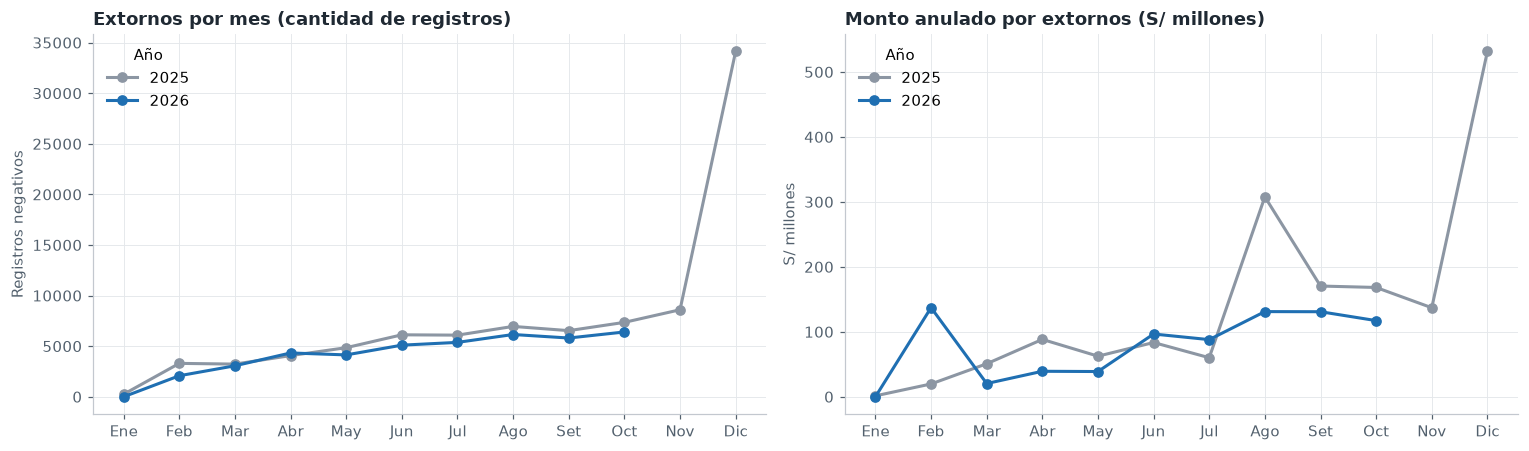

**Lectura automática:** en 2025 hubo **91,484 extornos** (1.69% de los registros mensuales), que anularon **S/ 1,681.4 M** (0.66% del devengado neto) · en 2026 hubo **42,444 extornos** (0.99% de los registros mensuales), que anularon **S/ 799.4 M** (0.37% del devengado neto). Mes con más extornos: diciembre (2025), octubre (2026).

In [14]:
# Extornos (devengado mensual negativo): ¿cuántos hay, cuánto suman y en qué meses se concentran?
def extornos_por_mes(anio):
    acum = []
    for lote in iterar_parquet(SILVER / f"devengado_mensual_{anio}.parquet", columnas=["mes", "monto_devengado", "es_extorno"]):
        acum.append(lote.groupby("mes").agg(registros=("monto_devengado", "size"), extornos=("es_extorno", "sum"),
                                            monto_extornos=("monto_devengado", lambda s: s[s < 0].sum()),
                                            devengado_neto=("monto_devengado", "sum")))
    t = pd.concat(acum).groupby(level=0).sum()
    t["% registros"] = t["extornos"] / t["registros"]
    t["extorno / devengado"] = -t["monto_extornos"] / t["devengado_neto"]
    return t.assign(anio=anio)


extornos = pd.concat([extornos_por_mes(a) for a in ANIOS]).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for anio, g in extornos.groupby("anio"):
    axes[0].plot(g["mes"], g["extornos"], marker="o", lw=2, ms=6, color=COLOR_ANIO[anio], label=str(anio))
    axes[1].plot(g["mes"], -g["monto_extornos"], marker="o", lw=2, ms=6, color=COLOR_ANIO[anio], label=str(anio))
axes[0].set(title="Extornos por mes (cantidad de registros)", ylabel="Registros negativos")
axes[1].set(title="Monto anulado por extornos (S/ millones)", ylabel="S/ millones")
axes[1].yaxis.set_major_formatter(EJE_MILLONES)
for ax in axes:
    ax.set_xticks(range(1, 13), MES_ABREV)
    ax.legend(title="Año")
plt.tight_layout()
guardar(fig, "extornos_por_mes.png")
plt.show()

tot = extornos.groupby("anio")[["registros", "extornos", "monto_extornos", "devengado_neto"]].sum()
nota("**Lectura automática:** " + " · ".join(
    f"en {a} hubo **{t.extornos:,.0f} extornos** ({t.extornos / t.registros:.2%} de los registros mensuales), que anularon "
    f"**{s_millones(-t.monto_extornos)}** ({-t.monto_extornos / t.devengado_neto:.2%} del devengado neto)"
    for a, t in tot.iterrows()) + ". Mes con más extornos: " + ", ".join(
    f"{MESES[int(g.loc[g['extornos'].idxmax(), 'mes']) - 1].lower()} ({a})" for a, g in extornos.groupby("anio")) + ".")

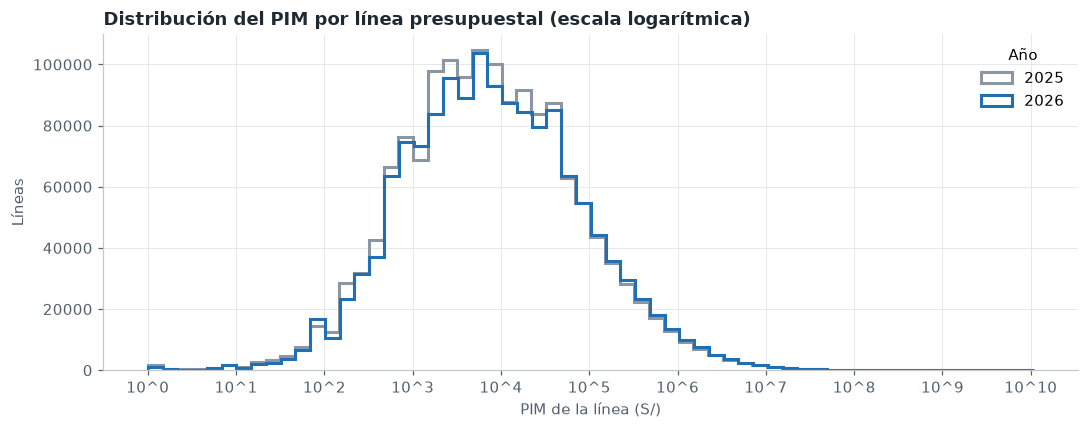

**Lectura automática:** el PIM por línea está **muy sesgado a la derecha** — en 2025 la mediana es S/ 623 pero la media es S/ 103,630; el 1 % de líneas más grandes concentra **73.1%** del PIM · en 2026 la mediana es S/ 950 pero la media es S/ 119,390; el 1 % de líneas más grandes concentra **71.9%** del PIM. Por eso los promedios por línea engañan: los indicadores se calculan como **razón de sumas** (Σ devengado ÷ Σ PIM), no como promedio de porcentajes.

In [15]:
# Estadísticas descriptivas por línea presupuestal (montos en S/). Solo se leen las columnas de montos.
montos_lineas = pd.concat([leer_parquet(SILVER / f"presupuesto_anual_{a}.parquet", ["anio", *MONTOS_SILVER]) for a in ANIOS])
descriptivas = (montos_lineas.groupby("anio")[["monto_pim", "monto_devengado"]]
                .describe(percentiles=[.25, .5, .75, .9, .99]).T.unstack(level=0))
display(descriptivas.style.format("{:,.0f}"))

# Concentración: ¿qué parte del PIM explica el 1 % de líneas más grandes?
conc = {}
for anio, g in montos_lineas.groupby("anio"):
    pim = np.sort(g["monto_pim"].clip(lower=0).to_numpy())[::-1]
    conc[anio] = pim[: max(1, len(pim) // 100)].sum() / pim.sum()

fig, ax = plt.subplots(figsize=(10, 4))
for anio, g in montos_lineas.groupby("anio"):
    v = g.loc[g["monto_pim"] > 0, "monto_pim"]
    ax.hist(np.log10(v), bins=60, histtype="step", lw=2, color=COLOR_ANIO[anio], label=str(anio))
ax.set_xticks(range(0, 11), [f"10^{k}" for k in range(0, 11)])
ax.set(title="Distribución del PIM por línea presupuestal (escala logarítmica)", xlabel="PIM de la línea (S/)", ylabel="Líneas")
ax.legend(title="Año")
plt.tight_layout()
guardar(fig, "distribucion_pim_lineas.png")
plt.show()

d = montos_lineas.groupby("anio")["monto_pim"]
nota("**Lectura automática:** el PIM por línea está **muy sesgado a la derecha** — " + " · ".join(
    f"en {a} la mediana es S/ {d.median()[a]:,.0f} pero la media es S/ {d.mean()[a]:,.0f}; "
    f"el 1 % de líneas más grandes concentra **{conc[a]:.1%}** del PIM" for a in ANIOS)
    + ". Por eso los promedios por línea engañan: los indicadores se calculan como **razón de sumas** (Σ devengado ÷ Σ PIM), no como promedio de porcentajes.")
del montos_lineas

### Decisión de tratamiento

| Hallazgo | Decisión |
|---|---|
| Líneas con todos los montos en 0 | Se excluyen de Silver (no cambian ninguna suma) y se cuentan en el reporte |
| Montos no numéricos o año distinto al del archivo | Se rechaza la fila y se guarda en `silver_rechazados_<año>.csv` |
| Extornos (devengado mensual negativo) | **Se conservan**: forman parte del devengado oficial; Gold los separa en `monto_extorno` para auditarlos |
| Devengado > PIM / Comprometido **a nivel de línea** | **No es un error de calidad, es estructural:** el MEF registra PIM, certificado y compromiso en la línea del *tipo de recurso* principal y el devengado en la línea de la *sub cuenta* (PIM = 0). Al sumar sin `tipo_recurso` las reglas se cumplen (se verifica al grano Gold en la sección 5). Conclusión: **el avance solo es válido desde el nivel de rubro hacia arriba**, nunca por línea con tipo de recurso. Por eso Gold no incluye `tipo_recurso` |
| Nulos en textos | Se muestran como `NO DEFINIDO` en las dimensiones de Gold para que ningún monto se pierda al filtrar |
| Duplicados exactos o de clave | Se reportan; si aparecen, se revisan con la fuente antes de eliminarlos |

---
## 5. Capa Gold: modelo dimensional (esquema estrella)

PIA, PIM, certificado, comprometido y girado son montos **anuales** (una foto a la fecha de corte); el devengado existe **por mes**. Si se mezclaran en una sola tabla, el PIM se repetiría 12 veces o quedaría colgado de un mes arbitrario. Por eso Gold tiene **dos tablas de hechos** que comparten dimensiones (constelación de hechos, Kimball):

```
                         dim_anio ───────────────┐
                            │ 1:*                │ 1:*
                      dim_calendario             │
                            │ 1:* (fecha)        │
 dim_entidad ──┐            ▼                    ▼            ┌── dim_entidad
 dim_funcion ──┼──► fact_gasto_mensual    fact_presupuesto_anual ◄──┼── dim_funcion
 dim_fuente ───┤    (devengado por mes)   (PIA, PIM, cert., comp., ├── dim_fuente_financiamiento
 dim_categoria ┤                           dev. y girado anuales)   ├── dim_categoria_gasto
 dim_tipo ─────┤                                                    ├── dim_tipo_intervencion
 dim_depto ────┤                                                    ├── dim_departamento
 dim_programa ─┘                                                    └── dim_programa_presupuestal
```

| Tabla | 1 fila = | Clave(s) |
|---|---|---|
| `fact_gasto_mensual` | mes × entidad × función × fuente × genérica × tipo × departamento × programa | `fecha` + 7 claves |
| `fact_presupuesto_anual` | año × la misma combinación | `anio` + 7 claves |
| `dim_calendario` | un mes (2025-01-01 … 2026-12-01) | `fecha` |
| `dim_anio` | un año, con su **mes de corte** | `anio` |
| `dim_entidad` | una unidad ejecutora (`sec_ejec`) con nivel, sector, pliego y ubicación | `entidad_key` |
| `dim_funcion` | una función del Estado (salud, educación…) | `funcion_key` |
| `dim_fuente_financiamiento` | fuente + rubro | `fuente_key` |
| `dim_categoria_gasto` | categoría (corriente/capital/deuda) + genérica | `categoria_key` |
| `dim_tipo_intervencion` | actividad o proyecto (inversión) | `tipo_intervencion_key` |
| `dim_departamento` | departamento donde se ubica la **meta** del gasto | `departamento_key` |
| `dim_programa_presupuestal` | categoría presupuestal: programa presupuestal, acciones centrales o APNOP | `programa_key` |

**Grano elegido:** se agrega por encima de la meta, la específica de gasto y el tipo de recurso (ver la decisión de la sección 4) (millones de líneas) a un nivel que responde todas las preguntas del dashboard con una fracción de las filas. Para añadir otra dimensión basta con agregar una entrada a `DIMENSIONES`; así se incorporó el **programa presupuestal** (categoría presupuestal), necesario para analizar la Ley 2026.

Las claves sustitutas son enteros: Power BI comprime y relaciona enteros mucho mejor que textos largos.

In [16]:
# Configuración del modelo: cada dimensión = clave natural (códigos) + atributos descriptivos.
DIMENSIONES = {
    "dim_entidad": {"clave": "entidad_key", "natural": ["sec_ejec"],
                    "atributos": ["nivel_gobierno", "nivel_gobierno_nombre", "sector", "sector_nombre", "pliego",
                                  "pliego_nombre", "ejecutora", "ejecutora_nombre", "departamento_ejecutora_nombre",
                                  "provincia_ejecutora_nombre", "distrito_ejecutora_nombre"]},
    "dim_funcion": {"clave": "funcion_key", "natural": ["funcion"], "atributos": ["funcion_nombre"]},
    "dim_fuente_financiamiento": {"clave": "fuente_key", "natural": ["fuente_financiamiento", "rubro"],
                                  "atributos": ["fuente_financiamiento_nombre", "rubro_nombre"]},
    "dim_categoria_gasto": {"clave": "categoria_key", "natural": ["categoria_gasto", "tipo_transaccion", "generica"],
                            "atributos": ["categoria_gasto_nombre", "tipo_transaccion_nombre", "generica_nombre"]},
    "dim_tipo_intervencion": {"clave": "tipo_intervencion_key", "natural": ["tipo_act_proy"], "atributos": []},
    "dim_departamento": {"clave": "departamento_key", "natural": ["departamento_meta"], "atributos": ["departamento_meta_nombre"]},
    "dim_programa_presupuestal": {"clave": "programa_key", "natural": ["programa_ppto"], "atributos": ["programa_ppto_nombre"]},
}
CLAVES = [d["clave"] for d in DIMENSIONES.values()]
ND_CODIGO, ND_NOMBRE = "ND", "NO DEFINIDO"


def rellenar_nd(df, columnas):
    """Los nulos de las columnas de dimensión pasan a 'ND' / 'NO DEFINIDO' para que ningún monto se pierda."""
    for c in columnas:
        if df[c].isna().any():
            valor = ND_NOMBRE if c.endswith("_nombre") else ND_CODIGO
            s = df[c]
            if isinstance(s.dtype, pd.CategoricalDtype) and valor not in s.cat.categories:
                s = s.cat.add_categories([valor])
            df[c] = s.fillna(valor)
    return df


# Pasada 1: miembros de cada dimensión (combinaciones distintas por año).
COLS_DIM = list(dict.fromkeys(c for d in DIMENSIONES.values() for c in d["natural"] + d["atributos"]))
miembros = {n: [] for n in DIMENSIONES}
for anio in ANIOS:
    for lote in iterar_parquet(SILVER / f"presupuesto_anual_{anio}.parquet", columnas=["anio", *COLS_DIM]):
        lote = rellenar_nd(lote, COLS_DIM)
        for nombre, d in DIMENSIONES.items():
            miembros[nombre].append(lote[["anio", *d["natural"], *d["atributos"]]].drop_duplicates().astype(str))

DIM, inconsistencias = {}, []
for nombre, d in DIMENSIONES.items():
    m = pd.concat(miembros[nombre]).drop_duplicates()
    m["anio"] = m["anio"].astype(int)
    # Consistencia: una clave natural debería tener un solo nombre por año.
    varios = m.groupby(["anio", *d["natural"]]).size()
    inconsistencias.append({"dimensión": nombre, "claves con >1 descripción en un año": int((varios > 1).sum()),
                            "claves cuya descripción cambió entre años": int(m.drop_duplicates([*d["natural"], *d["atributos"]])
                                                                            .duplicated(d["natural"]).sum())})
    # Descripción vigente = la del año más reciente (SCD tipo 1).
    dim = (m.sort_values("anio", ascending=False).drop_duplicates(d["natural"])
           .drop(columns="anio").sort_values(d["natural"]).reset_index(drop=True))
    dim.insert(0, d["clave"], np.arange(1, len(dim) + 1, dtype="int32"))
    DIM[nombre] = dim

DIM["dim_entidad"]["ejecutora_etiqueta"] = DIM["dim_entidad"]["sec_ejec"] + " · " + DIM["dim_entidad"]["ejecutora_nombre"]
# Las municipalidades no tienen sector en el clasificador del MEF: se rotulan por su nivel de gobierno.
_locales = DIM["dim_entidad"]["nivel_gobierno_nombre"].eq("GOBIERNOS LOCALES") & DIM["dim_entidad"]["sector_nombre"].eq(ND_NOMBRE)
DIM["dim_entidad"].loc[_locales, ["sector_nombre", "pliego_nombre"]] = ["GOBIERNOS LOCALES", "GOBIERNOS LOCALES"]
DIM["dim_tipo_intervencion"]["tipo_intervencion"] = DIM["dim_tipo_intervencion"]["tipo_act_proy"].str.title()
# Categoría presupuestal: programas presupuestales (presupuesto por resultados), acciones centrales (9001) y APNOP (9002).
_pp = DIM["dim_programa_presupuestal"]
_pp["programa_etiqueta"] = _pp["programa_ppto"] + " " + _pp["programa_ppto_nombre"]
_pp["tipo_programa"] = np.select([_pp["programa_ppto"].eq("9001"), _pp["programa_ppto"].eq("9002"), _pp["programa_ppto"].eq(ND_CODIGO)],
                                 ["ACCIONES CENTRALES", "APNOP", ND_NOMBRE], "PROGRAMA PRESUPUESTAL")
DIM["dim_categoria_gasto"]["generica_etiqueta"] = (DIM["dim_categoria_gasto"]["tipo_transaccion"] + "." +
                                                   DIM["dim_categoria_gasto"]["generica"] + " " + DIM["dim_categoria_gasto"]["generica_nombre"])
display(pd.DataFrame(inconsistencias))
pd.Series({n: len(t) for n, t in DIM.items()}, name="filas").to_frame().T

,dimensión,claves con >1 descripción en un año,claves cuya descripción cambió entre años
0,dim_entidad,0,3
1,dim_funcion,0,0
2,dim_fuente_financiamiento,0,0
3,dim_categoria_gasto,0,0
4,dim_tipo_intervencion,0,0
5,dim_departamento,0,0
6,dim_programa_presupuestal,0,0


,dim_entidad,dim_funcion,dim_fuente_financiamiento,dim_categoria_gasto,dim_tipo_intervencion,dim_departamento,dim_programa_presupuestal
filas,2893,25,9,12,2,26,91


In [17]:
# Pasada 2: hechos. Cada lote se traduce a claves enteras y se agrega; al final se agregan los parciales.
MAPAS = {n: DIM[n][[d["clave"], *d["natural"]]] for n, d in DIMENSIONES.items()}
NATURALES = list(dict.fromkeys(c for d in DIMENSIONES.values() for c in d["natural"]))


def a_claves(lote):
    lote = rellenar_nd(lote, NATURALES)
    lote[NATURALES] = lote[NATURALES].astype(str)
    for nombre, d in DIMENSIONES.items():
        lote = lote.merge(MAPAS[nombre], on=d["natural"], how="left", validate="many_to_one")
    assert lote[CLAVES].notna().all().all(), "Hay combinaciones sin clave de dimensión"
    return lote.drop(columns=NATURALES)


parciales_anual, parciales_mes = [], []
for anio in ANIOS:
    for lote in iterar_parquet(SILVER / f"presupuesto_anual_{anio}.parquet", columnas=["anio", *NATURALES, *MONTOS_SILVER]):
        lote = a_claves(lote).assign(n_lineas=1)
        parciales_anual.append(lote.groupby(["anio", *CLAVES])[[*MONTOS_SILVER, "n_lineas"]].sum())
    for lote in iterar_parquet(SILVER / f"devengado_mensual_{anio}.parquet", columnas=["fecha", "anio", *NATURALES, "monto_devengado"]):
        lote = a_claves(lote)
        lote["monto_extorno"] = lote["monto_devengado"].where(lote["monto_devengado"] < 0, 0.0)
        lote["n_registros"] = 1
        parciales_mes.append(lote.groupby(["fecha", "anio", *CLAVES])[["monto_devengado", "monto_extorno", "n_registros"]].sum())

fact_presupuesto_anual = pd.concat(parciales_anual).groupby(level=list(range(1 + len(CLAVES)))).sum().reset_index()
fact_gasto_mensual = pd.concat(parciales_mes).groupby(level=list(range(2 + len(CLAVES)))).sum().reset_index()
fact_gasto_mensual["fecha"] = pd.to_datetime(fact_gasto_mensual["fecha"])
del parciales_anual, parciales_mes
print(f"fact_presupuesto_anual: {len(fact_presupuesto_anual):,} filas · fact_gasto_mensual: {len(fact_gasto_mensual):,} filas")

fact_presupuesto_anual: 336,753 filas · fact_gasto_mensual: 1,502,279 filas


In [18]:
# Dimensiones de tiempo: el mes de corte se calcula con los datos, no se escribe a mano.
total_mes = fact_gasto_mensual.groupby("fecha")["monto_devengado"].sum()
anios_info = []
for anio in ANIOS:
    s = total_mes[total_mes.index.year == anio]
    s.index = s.index.month
    con_datos = s[s > 0]
    ultimo = int(con_datos.index.max())
    previos = con_datos[con_datos.index < ultimo]
    parcial = bool(len(previos) and con_datos[ultimo] < UMBRAL_MES_PARCIAL * previos.median())
    anios_info.append({"anio": anio, "mes_ultimo_dato": ultimo, "es_ultimo_mes_parcial": parcial,
                       "mes_ultimo_completo": ultimo - int(parcial)})
dim_anio = pd.DataFrame(anios_info)
CORTE = int(dim_anio["mes_ultimo_completo"].min())        # meses que TODOS los años tienen completos
dim_anio["es_anio_cerrado"] = dim_anio["mes_ultimo_completo"].eq(12)
dim_anio["fecha_ultimo_dato"] = pd.to_datetime(dict(year=dim_anio["anio"], month=dim_anio["mes_ultimo_dato"], day=1))
dim_anio["mes_corte_comparable"] = CORTE
dim_anio["periodo_comparable"] = f"Ene–{MES_ABREV[CORTE - 1]}"
dim_anio["anio_texto"] = dim_anio["anio"].astype(str)
dim_anio["anio_etiqueta"] = np.where(dim_anio["es_anio_cerrado"], dim_anio["anio_texto"] + " (cerrado)",
                                     dim_anio["anio_texto"] + " (al " + dim_anio["mes_ultimo_dato"].map(lambda m: MESES[m - 1].lower()) + ")")

fechas = pd.date_range(f"{min(ANIOS)}-01-01", f"{max(ANIOS)}-12-01", freq="MS")
dim_calendario = pd.DataFrame({"fecha": fechas, "anio": fechas.year, "mes_num": fechas.month})
dim_calendario["mes_nombre"] = dim_calendario["mes_num"].map(lambda m: MESES[m - 1].capitalize())
dim_calendario["mes_abrev"] = dim_calendario["mes_num"].map(lambda m: MES_ABREV[m - 1])
dim_calendario["trimestre"] = "T" + ((dim_calendario["mes_num"] - 1) // 3 + 1).astype(str)
dim_calendario["semestre"] = "S" + ((dim_calendario["mes_num"] - 1) // 6 + 1).astype(str)
dim_calendario["anio_mes"] = dim_calendario["fecha"].dt.strftime("%Y-%m")
dim_calendario["anio_mes_num"] = (dim_calendario["anio"] * 100 + dim_calendario["mes_num"]).astype("int32")
ultimo = dim_calendario["anio"].map(dim_anio.set_index("anio")["mes_ultimo_dato"])
dim_calendario["tiene_datos"] = dim_calendario["mes_num"] <= ultimo
dim_calendario["es_periodo_comparable"] = dim_calendario["mes_num"] <= CORTE
display(dim_anio)
print(f"Periodo comparable entre años: enero a {MESES[CORTE - 1].lower()} (mes {CORTE}).")

,anio,mes_ultimo_dato,es_ultimo_mes_parcial,mes_ultimo_completo,es_anio_cerrado,fecha_ultimo_dato,mes_corte_comparable,periodo_comparable,anio_texto,anio_etiqueta
0,2025,12,False,12,True,2025-12-01,10,Ene–Oct,2025,2025 (cerrado)
1,2026,10,False,10,False,2026-10-01,10,Ene–Oct,2026,2026 (al octubre)


Periodo comparable entre años: enero a octubre (mes 10).


In [19]:
# Exportación Gold (Parquet, compresión snappy) con tipos explícitos para Power BI.
def tipos_de(df):
    tipos = {}
    for c, t in df.dtypes.items():
        if c == "fecha" or c.startswith("fecha_"):
            tipos[c] = "fecha"
        elif pd.api.types.is_bool_dtype(t):
            tipos[c] = "bool"
        elif pd.api.types.is_integer_dtype(t):
            tipos[c] = "int64" if c.startswith("n_") else "int32"
        elif pd.api.types.is_float_dtype(t):
            tipos[c] = "float64"
        else:
            tipos[c] = "texto"
    return tipos


fact_presupuesto_anual[CLAVES + ["anio"]] = fact_presupuesto_anual[CLAVES + ["anio"]].astype("int32")
fact_gasto_mensual[CLAVES + ["anio"]] = fact_gasto_mensual[CLAVES + ["anio"]].astype("int32")
GOLD_TABLAS = {"fact_gasto_mensual": fact_gasto_mensual, "fact_presupuesto_anual": fact_presupuesto_anual,
               "dim_calendario": dim_calendario, "dim_anio": dim_anio, **DIM}
for nombre, tabla in GOLD_TABLAS.items():
    guardar_parquet(tabla, GOLD / f"{nombre}.parquet", tipos_de(tabla))
    print(f"Gold → {(GOLD / (nombre + '.parquet')).relative_to(RAIZ).as_posix():<58} {len(tabla):>10,} filas")

# Controles de cuadre: Gold debe reproducir exactamente los totales de Silver.
print()
for anio in ANIOS:
    fa = fact_presupuesto_anual[fact_presupuesto_anual["anio"] == anio]
    for c in MONTOS_SILVER:
        dif = abs(fa[c].sum() - SILVER_ST[anio]["suma"][c])
        print(f"{'✓' if dif <= TOLERANCIA_SOLES * 10 else '✗'} {anio} {c:<20} Gold = Silver (dif. S/ {dif:,.2f})")
    dif = abs(fact_gasto_mensual.loc[fact_gasto_mensual["anio"] == anio, "monto_devengado"].sum() - fa["monto_devengado"].sum())
    print(f"{'✓' if dif <= TOLERANCIA_SOLES * 10 else '✗'} {anio} Σ devengado mensual = devengado anual (dif. S/ {dif:,.2f})")

# Ciclo del gasto al grano Gold: aquí las reglas SÍ deben cumplirse (el tipo de recurso ya está sumado).
reglas_gold = []
for anio, fa in fact_presupuesto_anual.groupby("anio"):
    for regla_n, (menor, mayor) in REGLAS_EMBUDO.items():
        exceso = (fa[menor] - fa[mayor]).clip(lower=0)
        falla = exceso > TOLERANCIA_SOLES
        reglas_gold.append({"Año": anio, "Nivel": "grano Gold", "Dimensión": "Consistencia", "Regla": regla_n, "Evaluadas": len(fa),
                            "Incumplimientos": int(falla.sum()), "% cumplimiento": round(100 * (1 - falla.mean()), 3),
                            "Monto involucrado (S/)": round(float(exceso[falla].sum()), 2), "Impacto": "Avance > 100 % en el dashboard"})
reglas_gold = pd.DataFrame(reglas_gold)
reporte_calidad = pd.concat([reporte_calidad[reporte_calidad["Nivel"] == "línea"], reglas_gold], ignore_index=True)
reporte_calidad.to_csv(OUTPUTS / "reporte_calidad_dama.csv", index=False, encoding="utf-8-sig")
print()
display(reglas_gold.pivot_table(index="Regla", columns="Año", values=["Incumplimientos", "Monto involucrado (S/)"], sort=False))

Gold → data/gold/gasto_publico/fact_gasto_mensual.parquet          1,502,279 filas
Gold → data/gold/gasto_publico/fact_presupuesto_anual.parquet        336,753 filas
Gold → data/gold/gasto_publico/dim_calendario.parquet                     24 filas
Gold → data/gold/gasto_publico/dim_anio.parquet                            2 filas
Gold → data/gold/gasto_publico/dim_entidad.parquet                     2,893 filas
Gold → data/gold/gasto_publico/dim_funcion.parquet                        25 filas
Gold → data/gold/gasto_publico/dim_fuente_financiamiento.parquet           9 filas
Gold → data/gold/gasto_publico/dim_categoria_gasto.parquet                12 filas
Gold → data/gold/gasto_publico/dim_tipo_intervencion.parquet               2 filas
Gold → data/gold/gasto_publico/dim_departamento.parquet                   26 filas
Gold → data/gold/gasto_publico/dim_programa_presupuestal.parquet          91 filas

✓ 2025 monto_pia            Gold = Silver (dif. S/ 0.00)
✓ 2025 monto_pim            G

Incumplimientos      Monto involucrado (S/)  \
Año                                   2025 2026                   2025   
Regla                                                                    
Certificado ≤ PIM                      8.0  1.0              694958.69   
Comprometido ≤ Certificado             5.0  2.0               12009.94   
Devengado ≤ Comprometido              10.0  1.0              153534.91   
Girado ≤ Devengado                   152.0  0.0             1613303.89   
Devengado ≤ PIM                        9.0  0.0              657914.49   

                                      
Año                             2026  
Regla                                 
Certificado ≤ PIM              400.0  
Comprometido ≤ Certificado    5602.8  
Devengado ≤ Comprometido    100000.0  
Girado ≤ Devengado               0.0  
Devengado ≤ PIM                  0.0

In [20]:
# Diccionario de datos de Gold (para documentar el modelo en Power BI).
DESCRIPCION = {
    "fecha": "Primer día del mes (AAAA-MM-01)", "anio": "Año fiscal", "monto_devengado": "Devengado neto del mes / año (S/)",
    "monto_extorno": "Parte negativa del devengado: anulaciones (S/, ≤ 0)", "n_registros": "Registros línea × mes agregados",
    "n_lineas": "Líneas presupuestales agregadas", "monto_pia": "Presupuesto de apertura (S/)", "monto_pim": "Presupuesto modificado (S/)",
    "monto_certificado": "Certificado anual (S/)", "monto_comprometido": "Comprometido anual (S/)", "monto_girado": "Girado anual (S/)",
    "mes_ultimo_dato": "Último mes con devengado registrado", "es_ultimo_mes_parcial": "El último mes aún está en curso",
    "mes_corte_comparable": "Último mes completo común a todos los años (para comparar 2026 vs 2025)",
    "tiene_datos": "El mes ya tiene devengado registrado", "es_periodo_comparable": "Mes dentro del periodo comparable",
}
diccionario = pd.DataFrame([{"tabla": t, "columna": c, "tipo": tp,
                             "descripción": DESCRIPCION.get(c, "Clave sustituta (entero)" if c.endswith("_key") else "Atributo descriptivo / código MEF")}
                            for t, tabla in GOLD_TABLAS.items() for c, tp in tipos_de(tabla).items()])
diccionario.to_csv(OUTPUTS / "diccionario_datos_gold.csv", index=False, encoding="utf-8-sig")
diccionario[diccionario["tabla"].str.startswith("fact")]

,tabla,columna,tipo,descripción
0,fact_gasto_mensual,fecha,fecha,Primer día del mes (AAAA-MM-01)
1,fact_gasto_mensual,anio,int32,Año fiscal
2,fact_gasto_mensual,entidad_key,int32,Clave sustituta (entero)
3,fact_gasto_mensual,funcion_key,int32,Clave sustituta (entero)
4,fact_gasto_mensual,fuente_key,int32,Clave sustituta (entero)
5,fact_gasto_mensual,categoria_key,int32,Clave sustituta (entero)
6,fact_gasto_mensual,tipo_intervencion_key,int32,Clave sustituta (entero)
7,fact_gasto_mensual,departamento_key,int32,Clave sustituta (entero)
8,fact_gasto_mensual,programa_key,int32,Clave sustituta (entero)
9,fact_gasto_mensual,monto_devengado,float64,Devengado neto del mes / año (S/)


---
## 6. Análisis integral: las cinco líneas de análisis obligatorias

Desde aquí todo se calcula **solo con las tablas Gold**, igual que lo hará Power BI: si las cifras de esta sección cuadran, el dashboard también. La sección sigue el orden del enunciado:

| Línea | Sección |
|---|---|
| 1. Ejecución y proyección presupuestaria | 6.1 |
| 2. Clasificación de entidades | 6.2 |
| 3. Comportamiento mensual del gasto | 6.3 |
| 4. Detección de patrones atípicos | 6.4 |
| 5. Análisis de variaciones | 6.5 |

**Regla de comparación justa:** 2026 todavía no termina. Comparar el devengado *anual* de 2025 (12 meses) con el de 2026 (pocos meses) haría parecer que 2026 gasta mucho menos. Por eso la variación interanual se calcula **a igual mes de corte** (enero → `CORTE`).

Los gráficos con **Plotly** son interactivos (pase el mouse para ver valores) y se guardan también como HTML en `reports/`.

In [21]:
# Tabla base: hechos anuales + devengado del periodo comparable + atributos de las dimensiones.
comparable = (fact_gasto_mensual[fact_gasto_mensual["fecha"].dt.month <= CORTE]
              .groupby(["anio", *CLAVES])["monto_devengado"].sum().rename("dev_comparable").reset_index())
ATRIBUTOS = {"dim_entidad": ["nivel_gobierno_nombre", "sector_nombre", "pliego_nombre", "ejecutora_etiqueta",
                             "departamento_ejecutora_nombre"],
             "dim_funcion": ["funcion_nombre"], "dim_fuente_financiamiento": ["fuente_financiamiento_nombre"],
             "dim_categoria_gasto": ["categoria_gasto_nombre", "generica_nombre"],
             "dim_tipo_intervencion": ["tipo_intervencion"], "dim_departamento": ["departamento_meta_nombre"],
             "dim_programa_presupuestal": ["programa_etiqueta", "tipo_programa"]}
base = fact_presupuesto_anual.merge(comparable, on=["anio", *CLAVES], how="left").fillna({"dev_comparable": 0.0})
for nombre, cols in ATRIBUTOS.items():
    base = base.merge(DIM[nombre][[DIMENSIONES[nombre]["clave"], *cols]].astype({c: "category" for c in cols}),
                      on=DIMENSIONES[nombre]["clave"], how="left")


def resumen(por=None):
    """Indicadores por año (y por una dimensión): PIM, devengado, avance y variación a igual corte."""
    grupos = ["anio"] + ([por] if por else [])
    t = base.groupby(grupos, observed=True)[[*MONTOS_SILVER, "dev_comparable"]].sum()
    t["avance_anual"] = t["monto_devengado"] / t["monto_pim"]
    t["avance_corte"] = t["dev_comparable"] / t["monto_pim"]
    return t


def comparar(por):
    """Una fila por categoría: avance a igual corte de cada año y variación interanual del devengado."""
    t = resumen(por).reset_index().pivot(index=por, columns="anio")
    a0, a1 = ANIOS
    out = pd.DataFrame({f"PIM {a1}": t[("monto_pim", a1)], f"avance {a0} al corte": t[("avance_corte", a0)],
                        f"avance {a1} al corte": t[("avance_corte", a1)], f"avance {a0} anual": t[("avance_anual", a0)],
                        "var. devengado comparable": t[("dev_comparable", a1)] / t[("dev_comparable", a0)] - 1})
    return out.sort_values(f"PIM {a1}", ascending=False)


kpi = resumen().T
kpi.index = ["PIA", "PIM", "Certificado", "Comprometido", "Devengado", "Girado", f"Devengado Ene–{MES_ABREV[CORTE - 1]}",
             "Avance anual (Dev./PIM)", f"Avance a {MES_ABREV[CORTE - 1]} (Dev. comparable/PIM)"]
display(kpi.style.format(lambda v: f"{v:.1%}" if abs(v) < 5 else f"S/ {v / 1e6:,.1f} M"))

anio,2025,2026
PIA,"S/ 251,801.0 M","S/ 257,561.6 M"
PIM,"S/ 272,450.9 M","S/ 291,135.3 M"
Certificado,"S/ 263,078.4 M","S/ 270,816.0 M"
Comprometido,"S/ 258,771.1 M","S/ 252,924.3 M"
Devengado,"S/ 253,674.1 M","S/ 216,371.2 M"
Girado,"S/ 253,293.1 M","S/ 212,823.0 M"
Devengado Ene–Oct,"S/ 199,508.1 M","S/ 216,371.2 M"
Avance anual (Dev./PIM),93.1%,74.3%
Avance a Oct (Dev. comparable/PIM),73.2%,74.3%


### 6.1 Línea 1 · Ejecución y proyección presupuestaria

Se analiza la **evolución del PIA, PIM y devengado**, la **tendencia** de la ejecución y se elaboran **proyecciones estadísticas** del cierre del año en curso con tres métodos, para comparar sus resultados y su incertidumbre.

In [22]:
# 6.1.a Evolución del PIA, PIM y devengado: cuánto se aprobó, cuánto se modificó y cuánto se ejecutó.
a0, a1 = ANIOS
ETIQUETA_ANIO = dim_anio.set_index("anio")["anio_etiqueta"]
evolucion = resumen()[["monto_pia", "monto_pim", "monto_devengado", "dev_comparable"]].copy()
evolucion["modificacion_pct"] = evolucion["monto_pim"] / evolucion["monto_pia"] - 1
evolucion["avance_anual"] = evolucion["monto_devengado"] / evolucion["monto_pim"]
evolucion["avance_corte"] = evolucion["dev_comparable"] / evolucion["monto_pim"]
evolucion["saldo_por_ejecutar"] = evolucion["monto_pim"] - evolucion["monto_devengado"]
display(evolucion.style.format({c: ("{:.1%}" if c.startswith(("modificacion", "avance")) else "S/ {:,.0f}") for c in evolucion.columns}))

if TIENE_PLOTLY:
    etapas_ev = {"PIA": "monto_pia", "PIM": "monto_pim", "Devengado": "monto_devengado"}
    fig = go.Figure()
    for anio in ANIOS:
        vals = [evolucion.loc[anio, c] / 1e9 for c in etapas_ev.values()]
        fig.add_bar(name=ETIQUETA_ANIO[anio], x=list(etapas_ev), y=vals, marker_color=COLOR_ANIO[anio],
                    text=[f"{v:,.1f}" for v in vals], textposition="outside",
                    hovertemplate="%{x} " + str(anio) + ": S/ %{y:,.1f} mil millones<extra></extra>")
    fig.update_layout(title="Evolución del PIA, PIM y devengado (S/ miles de millones)", barmode="group",
                      yaxis_title="S/ miles de millones", height=430)
    mostrar(fig, "evolucion_pia_pim_devengado")

crec_pia = evolucion.loc[a1, "monto_pia"] / evolucion.loc[a0, "monto_pia"] - 1
crec_pim = evolucion.loc[a1, "monto_pim"] / evolucion.loc[a0, "monto_pim"] - 1
nota(f"""**Lectura automática**

- El **PIA** pasó de {s_millones(evolucion.loc[a0, 'monto_pia'])} en {a0} a {s_millones(evolucion.loc[a1, 'monto_pia'])} en {a1} (**{crec_pia:+.1%}**).
- Durante el año el presupuesto se modifica: el **PIM** supera al PIA en **{evolucion.loc[a0, 'modificacion_pct']:+.1%}** en {a0} y en **{evolucion.loc[a1, 'modificacion_pct']:+.1%}** en {a1} (a la fecha de corte). El PIM de {a1} es {crec_pim:+.1%} frente al de {a0}.
- {a0} cerró con un **avance de {evolucion.loc[a0, 'avance_anual']:.1%}** (saldo sin ejecutar: {s_millones(evolucion.loc[a0, 'saldo_por_ejecutar'])}); {a1} lleva **{evolucion.loc[a1, 'avance_anual']:.1%}**.""")

,monto_pia,monto_pim,monto_devengado,dev_comparable,modificacion_pct,avance_anual,avance_corte,saldo_por_ejecutar
anio,,,,,,,,
2025,"S/ 251,801,045,185","S/ 272,450,859,407","S/ 253,674,128,692","S/ 199,508,127,880",8.2%,93.1%,73.2%,"S/ 18,776,730,715"
2026,"S/ 257,561,619,143","S/ 291,135,315,326","S/ 216,371,201,757","S/ 216,371,201,757",13.0%,74.3%,74.3%,"S/ 74,764,113,569"


**Lectura automática**

- El **PIA** pasó de S/ 251,801.0 M en 2025 a S/ 257,561.6 M en 2026 (**+2.3%**).
- Durante el año el presupuesto se modifica: el **PIM** supera al PIA en **+8.2%** en 2025 y en **+13.0%** en 2026 (a la fecha de corte). El PIM de 2026 es +6.9% frente al de 2025.
- 2025 cerró con un **avance de 93.1%** (saldo sin ejecutar: S/ 18,776.7 M); 2026 lleva **74.3%**.

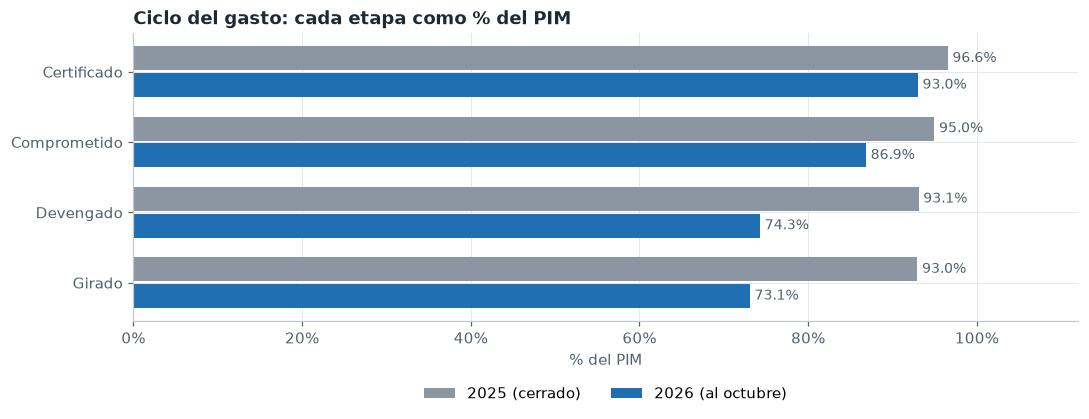

**Lectura automática**

- **2025:** PIM de S/ 272,450.9 M (el PIA se modificó en +8.2%); se devengó el **93.1%**. Quedaron sin ejecutar S/ 18,776.7 M.
- **2026** (datos hasta octubre): PIM de S/ 291,135.3 M; lleva devengado el **74.3%**, pero ya tiene **certificado el 93.0%**: la brecha certificado − devengado es gasto ya reservado que aún no se concreta.
- El girado sigue de cerca al devengado (99.8% del devengado en 2025): una vez reconocida la obligación, el pago es rápido.

In [23]:
# 6.1.b Eficiencia del ciclo del gasto: ¿qué fracción del PIM avanzó cada etapa del ciclo del gasto?
k = resumen()
etapas = {"Certificado": "monto_certificado", "Comprometido": "monto_comprometido", "Devengado": "monto_devengado", "Girado": "monto_girado"}
fig, ax = plt.subplots(figsize=(10, 4))
y = np.arange(len(etapas))
alto = 0.38
for i, anio in enumerate(ANIOS):
    vals = [k.loc[anio, c] / k.loc[anio, "monto_pim"] for c in etapas.values()]
    barras = ax.barh(y + (i - 0.5) * alto, vals, height=alto - 0.04, color=COLOR_ANIO[anio],
                     label=dim_anio.set_index("anio").loc[anio, "anio_etiqueta"])
    ax.bar_label(barras, labels=[f"{v:.1%}" for v in vals], padding=3, fontsize=9, color=TINTA_2)
ax.set_yticks(y, list(etapas))
ax.invert_yaxis()
ax.xaxis.set_major_formatter(EJE_PCT)
ax.set(title="Ciclo del gasto: cada etapa como % del PIM", xlabel="% del PIM", xlim=(0, 1.12))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
plt.tight_layout()
guardar(fig, "ciclo_gasto_pct_pim.png")
plt.show()

a0, a1 = ANIOS
nota(f"""**Lectura automática**

- **{a0}:** PIM de {s_millones(k.loc[a0, 'monto_pim'])} (el PIA se modificó en {k.loc[a0, 'monto_pim'] / k.loc[a0, 'monto_pia'] - 1:+.1%}); se devengó el **{k.loc[a0, 'avance_anual']:.1%}**. Quedaron sin ejecutar {s_millones(k.loc[a0, 'monto_pim'] - k.loc[a0, 'monto_devengado'])}.
- **{a1}** (datos hasta {MESES[int(dim_anio.set_index('anio').loc[a1, 'mes_ultimo_dato']) - 1].lower()}): PIM de {s_millones(k.loc[a1, 'monto_pim'])}; lleva devengado el **{k.loc[a1, 'avance_anual']:.1%}**, pero ya tiene **certificado el {k.loc[a1, 'monto_certificado'] / k.loc[a1, 'monto_pim']:.1%}**: la brecha certificado − devengado es gasto ya reservado que aún no se concreta.
- El girado sigue de cerca al devengado ({k.loc[a0, 'monto_girado'] / k.loc[a0, 'monto_devengado']:.1%} del devengado en {a0}): una vez reconocida la obligación, el pago es rápido.""")

#### 6.1.c Proyecciones estadísticas del cierre

| Método | Supuesto | Cómo se calcula | Incertidumbre |
|---|---|---|---|
| **A. Estacional** | El año en curso repite el calendario de gasto del año base | Devengado acumulado ÷ parte del año base ejecutada a ese mes | Sin intervalo (método determinista) |
| **B. Tendencia lineal** | El gasto mensual sigue una recta en el tiempo | Regresión por mínimos cuadrados del devengado mensual contra el mes | Intervalo de predicción al 95 % |
| **C. Regresión sobre el año base** | Cada mes del año en curso es proporcional al mismo mes del año base (`dev₁ = β · dev₀`) | Regresión por el origen con los meses ya observados | Intervalo de predicción al 95 % |

Para saber qué tan fiable es cada método se hace una **prueba hacia atrás** con el año base: se ajusta con los mismos meses observados del año en curso y se compara la proyección con el cierre real.

In [24]:
# 6.1.c Proyección del cierre con tres métodos estadísticos e intervalo de predicción al 95 %.
T_975 = {1: 12.706, 2: 4.303, 3: 3.182, 4: 2.776, 5: 2.571, 6: 2.447, 7: 2.365, 8: 2.306, 9: 2.262, 10: 2.228, 11: 2.201}


def t_975(gl):
    """Cuantil 0.975 de la t de Student (tabla; ≥ 12 grados de libertad ≈ 1.96–2.18)."""
    return T_975.get(gl, 2.18 if gl < 20 else 1.96)


MESES_NUM = np.arange(1, 13)
dev_mes = (fact_gasto_mensual.assign(mes=fact_gasto_mensual["fecha"].dt.month)
           .groupby(["anio", "mes"])["monto_devengado"].sum().unstack("anio").reindex(MESES_NUM).fillna(0.0))
ULT1 = int(dim_anio.set_index("anio").loc[a1, "mes_ultimo_dato"])
PIM1 = float(evolucion.loc[a1, "monto_pim"])
obs = MESES_NUM <= ULT1


def proyectar(y, x_base, n_obs):
    """Devuelve las tres proyecciones del total anual con los primeros n_obs meses de y (serie mensual)."""
    y_o, base_o = y[:n_obs], x_base[:n_obs]
    acumulado = y_o.sum()
    h = 12 - n_obs
    # A. Estacional: lo observado ÷ parte del año base ejecutada a ese mes.
    a_total = acumulado / (x_base[:n_obs].sum() / x_base.sum())
    # B. Tendencia lineal: y = b0 + b1·mes (mínimos cuadrados) y predicción de los meses que faltan.
    X = np.column_stack([np.ones(n_obs), np.arange(1, n_obs + 1)])
    coef, *_ = np.linalg.lstsq(X, y_o, rcond=None)
    F = np.column_stack([np.ones(h), np.arange(n_obs + 1, 13)])
    pred_b = F @ coef
    gl_b = n_obs - 2
    s2_b = float(((y_o - X @ coef) ** 2).sum() / gl_b)
    sv = F.sum(axis=0)
    var_b = s2_b * (h + sv @ np.linalg.inv(X.T @ X) @ sv)
    # C. Regresión por el origen sobre el año base: y_m = β · base_m.
    beta = float((base_o * y_o).sum() / (base_o ** 2).sum())
    pred_c = beta * x_base[n_obs:]
    gl_c = n_obs - 1
    s2_c = float(((y_o - beta * base_o) ** 2).sum() / gl_c)
    var_c = s2_c * (h + x_base[n_obs:].sum() ** 2 / (base_o ** 2).sum())
    return {"A": (a_total, np.nan, np.nan, None),
            "B": (acumulado + pred_b.sum(), t_975(gl_b) * np.sqrt(var_b), coef[1], pred_b),
            "C": (acumulado + pred_c.sum(), t_975(gl_c) * np.sqrt(var_c), beta, pred_c)}


y1, y0 = dev_mes[a1].to_numpy(), dev_mes[a0].to_numpy()
p_seg = proyectar(y1, y0, ULT1)
# Prueba hacia atrás: aplicar el método B sobre el año base con los mismos meses observados.
# (A y C necesitan un año anterior al año base para probarse; se informa su supuesto.)
p_base = proyectar(y0, y0, ULT1)
error_b = p_base["B"][0] / y0.sum() - 1

NOMBRES_METODO = {"A": "A. Estacional (calendario del año base)", "B": "B. Tendencia lineal (MCO)",
                  "C": "C. Regresión sobre el año base (β)"}
proyeccion_metodos = pd.DataFrame([{
    "metodo_codigo": m, "metodo": NOMBRES_METODO[m], "devengado_proyectado": tot,
    "avance_proyectado": min(tot / PIM1, 1.0),
    "limite_inferior": (tot - mg) / PIM1 if pd.notna(mg) else np.nan,
    "limite_superior": min((tot + mg) / PIM1, 1.0) if pd.notna(mg) else np.nan,
    "parametro": par if par is not None else np.nan,
    "error_prueba_base": error_b if m == "B" else np.nan,
} for m, (tot, mg, par, _) in p_seg.items()])
proyeccion_metodos["es_metodo_oficial"] = proyeccion_metodos["metodo_codigo"].eq("A")
display(proyeccion_metodos.style.format({"devengado_proyectado": "S/ {:,.0f}", "avance_proyectado": "{:.1%}", "limite_inferior": "{:.1%}",
                                         "limite_superior": "{:.1%}", "parametro": "{:,.3f}", "error_prueba_base": "{:+.1%}"}, na_rep="—"))

# Curvas mensuales de avance acumulado (% del PIM) para el dashboard.
acum_real = np.cumsum(y1) / PIM1
filas = []
for m in MESES_NUM:
    fila = {"anio": a1, "mes_num": int(m), "mes_abrev": MES_ABREV[m - 1],
            "real_acumulado": float(acum_real[m - 1]) if m <= ULT1 else np.nan}
    for k in ("B", "C"):
        _tot, _mg, _, pred = p_seg[k]
        if m < ULT1:
            fila[f"proy_{k.lower()}"] = np.nan
        else:
            extra = pred[: m - ULT1].sum() if m > ULT1 else 0.0
            fila[f"proy_{k.lower()}"] = (y1[:ULT1].sum() + extra) / PIM1
    cuota_base = y0[:m].sum() / y0.sum()
    fila["proy_a"] = np.nan if m < ULT1 else p_seg["A"][0] * cuota_base / PIM1
    # El intervalo crece con el horizonte: se reparte en proporción a los meses ya proyectados.
    frac = max(m - ULT1, 0) / max(12 - ULT1, 1)
    fila["lim_inf_c"] = np.nan if m < ULT1 else fila["proy_c"] - frac * p_seg["C"][1] / PIM1
    fila["lim_sup_c"] = np.nan if m < ULT1 else fila["proy_c"] + frac * p_seg["C"][1] / PIM1
    filas.append(fila)
proyeccion_mensual = pd.DataFrame(filas)
for c in ["proy_a", "proy_b", "proy_c", "lim_inf_c", "lim_sup_c"]:
    proyeccion_mensual[c] = proyeccion_mensual[c].clip(upper=1.0)

if TIENE_PLOTLY:
    pm = proyeccion_mensual
    fig = go.Figure()
    fig.add_scatter(x=pm["mes_abrev"], y=pm["lim_sup_c"], mode="lines", line=dict(width=0), showlegend=False, hoverinfo="skip")
    fig.add_scatter(x=pm["mes_abrev"], y=pm["lim_inf_c"], mode="lines", line=dict(width=0), fill="tonexty",
                    fillcolor="rgba(31,111,178,0.15)", name="Intervalo 95 % (método C)", hoverinfo="skip")
    real0 = np.cumsum(y0) / float(evolucion.loc[a0, "monto_pim"])
    fig.add_scatter(x=MES_ABREV, y=real0, mode="lines+markers", name=f"Real {a0}", line=dict(color=COLOR_ANIO[a0]))
    fig.add_scatter(x=pm["mes_abrev"], y=pm["real_acumulado"], mode="lines+markers", name=f"Real {a1}", line=dict(color=COLOR_ANIO[a1], width=3))
    fig.add_scatter(x=pm["mes_abrev"], y=pm["proy_a"], mode="lines", name="A. Estacional", line=dict(color=COLOR_ANIO[a1], dash="dash"))
    fig.add_scatter(x=pm["mes_abrev"], y=pm["proy_b"], mode="lines", name="B. Tendencia lineal", line=dict(color=TINTA_2, dash="dot"))
    fig.add_scatter(x=pm["mes_abrev"], y=pm["proy_c"], mode="lines", name="C. Regresión sobre el año base", line=dict(color=COLOR_META, dash="dash"))
    fig.update_layout(title=f"Proyección del avance acumulado {a1} (% del PIM) con tres métodos", yaxis_tickformat=".0%",
                      yaxis_title="Devengado acumulado ÷ PIM", height=460)
    mostrar(fig, "proyeccion_cierre_metodos")

pa_, pb_, pc_ = (proyeccion_metodos.set_index("metodo_codigo").loc[k] for k in "ABC")
nota(f"""**Lectura automática**

- **A. Estacional:** cierre {a1} proyectado en **{pa_['avance_proyectado']:.1%}** del PIM ({s_millones(pa_['devengado_proyectado'])}). Es el método que usan el POA (sección 8) y el dashboard.
- **C. Regresión sobre el año base:** cada mes de {a1} equivale a **β = {pc_['parametro']:.3f}** veces el mismo mes de {a0}; proyecta **{pc_['avance_proyectado']:.1%}** con un intervalo de predicción al 95 % de **{pc_['limite_inferior']:.1%} – {pc_['limite_superior']:.1%}**.
- **B. Tendencia lineal:** proyecta **{pb_['avance_proyectado']:.1%}** (intervalo {pb_['limite_inferior']:.1%} – {pb_['limite_superior']:.1%}). En la prueba hacia atrás con {a0}, este método **se equivoca en {error_b:+.1%}** respecto del cierre real, porque una recta no capta el pico de diciembre: por eso se prefieren los métodos que usan el calendario del año base (A y C).
- Que A y C coincidan (diferencia de {abs(pa_['avance_proyectado'] - pc_['avance_proyectado']) * 100:.1f} puntos) da confianza a la proyección usada en las metas.""")

,metodo_codigo,metodo,devengado_proyectado,avance_proyectado,limite_inferior,limite_superior,parametro,error_prueba_base,es_metodo_oficial
0,A,A. Estacional (calendario del año base),"S/ 275,115,488,592",94.5%,—,—,—,—,True
1,B,B. Tendencia lineal (MCO),"S/ 260,735,894,303",89.6%,84.8%,94.3%,"90,871,016.220",-3.8%,False
2,C,C. Regresión sobre el año base (β),"S/ 274,997,688,727",94.5%,91.8%,97.1%,1.082,—,False


**Lectura automática**

- **A. Estacional:** cierre 2026 proyectado en **94.5%** del PIM (S/ 275,115.5 M). Es el método que usan el POA (sección 8) y el dashboard.
- **C. Regresión sobre el año base:** cada mes de 2026 equivale a **β = 1.082** veces el mismo mes de 2025; proyecta **94.5%** con un intervalo de predicción al 95 % de **91.8% – 97.1%**.
- **B. Tendencia lineal:** proyecta **89.6%** (intervalo 84.8% – 94.3%). En la prueba hacia atrás con 2025, este método **se equivoca en -3.8%** respecto del cierre real, porque una recta no capta el pico de diciembre: por eso se prefieren los métodos que usan el calendario del año base (A y C).
- Que A y C coincidan (diferencia de 0.0 puntos) da confianza a la proyección usada en las metas.

### 6.2 Línea 2 · Clasificación de entidades según su ejecución

Se comparan y clasifican las **entidades** con su porcentaje de ejecución. Se trabaja en dos niveles del clasificador institucional:

- **Entidad (pliego)**: un ministerio, un organismo, un gobierno regional o una municipalidad. En el dataset, el pliego de los gobiernos locales viene sin código, así que cada municipalidad se identifica por su unidad ejecutora.
- **Unidad ejecutora** (la oficina que ejecuta el gasto dentro del pliego).

Para que ambos años se clasifiquen en la **misma escala anual**, el año cerrado usa su avance final y el año en curso su **avance proyectado al cierre** (método estacional de 6.1, calculado con el calendario propio de cada entidad). Solo se clasifican entidades con PIM ≥ `PIM_MINIMO_RANKING` para evitar el ruido de presupuestos muy pequeños.

| Clase | Avance (devengado ÷ PIM) |
|---|---|
| Muy alta | ≥ 95 % |
| Alta | 90 % – 95 % |
| Media | 75 % – 90 % |
| Baja | 50 % – 75 % |
| Muy baja | < 50 % |

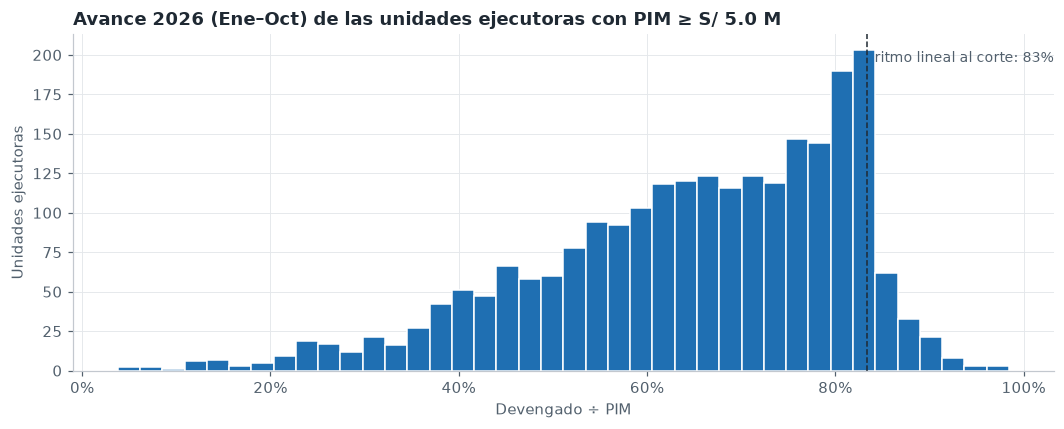

,ejecutora_etiqueta,nivel_gobierno_nombre,departamento_ejecutora_nombre,monto_pim,monto_certificado,dev_comparable,avance,certificado_pct
636,1811 · PROGRAMA DE REDUCCIÓN DE CULTIVOS ILEGALES EN EL PERÚ - PRECIP,GOBIERNO NACIONAL,LIMA,"S/ 74,283,323","S/ 15,295,838","S/ 2,810,849",3.8%,20.6%
806,300147 · MUNICIPALIDAD DISTRITAL DE LA PAMPA,GOBIERNOS LOCALES,ANCASH,"S/ 14,769,639","S/ 1,121,100","S/ 758,418",5.1%,7.6%
731,300072 · MUNICIPALIDAD DISTRITAL DE MARISCAL BENAVIDES,GOBIERNOS LOCALES,AMAZONAS,"S/ 15,382,149","S/ 14,329,570","S/ 1,183,858",7.7%,93.2%
615,1779 · UNIVERSIDAD NACIONAL AUTONOMA DEL DISTRITO DE SAN MARCOS - UNADISAM,GOBIERNO NACIONAL,ANCASH,"S/ 25,219,248","S/ 2,560,819","S/ 2,025,103",8.0%,10.2%
1806,301153 · MUNICIPALIDAD DISTRITAL DE UCUNCHA,GOBIERNOS LOCALES,LA LIBERTAD,"S/ 7,215,361","S/ 6,962,960","S/ 766,025",10.6%,96.5%
616,1780 · UNIVERSIDAD NACIONAL TECNOLOGICA DE CHINCHA - UNATECH,GOBIERNO NACIONAL,ICA,"S/ 19,665,207","S/ 3,325,260","S/ 2,174,600",11.1%,16.9%
854,300195 · MUNICIPALIDAD DISTRITAL DE LLIPA,GOBIERNOS LOCALES,ANCASH,"S/ 8,442,912","S/ 7,781,643","S/ 947,857",11.2%,92.2%
599,1763 · PROYECTO DE TRANSFORMACION DIGITAL CON EQUIDAD - PROTDE,GOBIERNO NACIONAL,LIMA,"S/ 38,885,503","S/ 6,012,275","S/ 4,663,550",12.0%,15.5%
829,300170 · MUNICIPALIDAD DISTRITAL DE MALVAS,GOBIERNOS LOCALES,ANCASH,"S/ 11,676,804","S/ 11,245,114","S/ 1,422,301",12.2%,96.3%
1731,301075 · MUNICIPALIDAD DISTRITAL DE PANCAN,GOBIERNOS LOCALES,JUNIN,"S/ 9,371,653","S/ 6,296,600","S/ 1,216,616",13.0%,67.2%


**Lectura automática:** de 2,371 unidades ejecutoras con PIM ≥ S/ 5.0 M, **10.1%** avanzan menos de la mitad del ritmo lineal (42%). La mediana de avance es 67.4%. Las 15 más rezagadas se guardan en `outputs/gasto_publico/ejecutoras_rezagadas_2026.csv`.

In [25]:
# 6.2.a Unidades ejecutoras: distribución del avance y las más rezagadas (solo con PIM relevante).
ue = (base[base["anio"] == a1].groupby(["ejecutora_etiqueta", "nivel_gobierno_nombre", "departamento_ejecutora_nombre"], observed=True)
      [["monto_pim", "monto_certificado", "dev_comparable"]].sum().reset_index())
ue = ue[ue["monto_pim"] >= PIM_MINIMO_RANKING].copy()
ue["avance"] = ue["dev_comparable"] / ue["monto_pim"]
ue["certificado_pct"] = ue["monto_certificado"] / ue["monto_pim"]
esperado = CORTE / 12

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(ue["avance"].clip(0, 1.2), bins=40, color=AZUL, edgecolor="white")
ax.axvline(esperado, color=TINTA, ls="--", lw=1)
ax.text(esperado, ax.get_ylim()[1] * 0.95, f"  ritmo lineal al corte: {esperado:.0%}", fontsize=9, color=TINTA_2, va="top")
ax.xaxis.set_major_formatter(EJE_PCT)
ax.set(title=f"Avance {a1} (Ene–{MES_ABREV[CORTE - 1]}) de las unidades ejecutoras con PIM ≥ {s_millones(PIM_MINIMO_RANKING)}", xlabel="Devengado ÷ PIM", ylabel="Unidades ejecutoras")
plt.tight_layout()
guardar(fig, "distribucion_avance_ejecutoras.png")
plt.show()

rezagadas = ue.nsmallest(TOP_N, "avance")
rezagadas.to_csv(OUTPUTS / f"ejecutoras_rezagadas_{a1}.csv", index=False, encoding="utf-8-sig")
display(rezagadas.style.format({"monto_pim": "S/ {:,.0f}", "monto_certificado": "S/ {:,.0f}", "dev_comparable": "S/ {:,.0f}",
                                "avance": "{:.1%}", "certificado_pct": "{:.1%}"}))
nota(f"**Lectura automática:** de {len(ue):,} unidades ejecutoras con PIM ≥ {s_millones(PIM_MINIMO_RANKING)}, "
     f"**{(ue['avance'] < esperado / 2).mean():.1%}** avanzan menos de la mitad del ritmo lineal ({esperado / 2:.0%}). "
     f"La mediana de avance es {ue['avance'].median():.1%}. Las {TOP_N} más rezagadas se guardan en `outputs/{CARPETA}/ejecutoras_rezagadas_{a1}.csv`.")

In [26]:
# 6.2.b Clasificación por clases de ejecución y por cuartiles, para pliegos y unidades ejecutoras.
UMBRALES_CLASE = [(0.95, "Muy alta"), (0.90, "Alta"), (0.75, "Media"), (0.50, "Baja"), (-np.inf, "Muy baja")]
ORDEN_CLASE = {c: i for i, (_, c) in enumerate(UMBRALES_CLASE, start=1)}
COLOR_CLASE = {"Muy alta": "#1F6FB2", "Alta": "#6FA8DC", "Media": "#8C96A3", "Baja": "#D49600", "Muy baja": "#C62828"}


def clase_ejecucion(avance):
    for umbral, nombre in UMBRALES_CLASE:
        if avance >= umbral:
            return nombre
    return "Muy baja"


fm_mes = fact_gasto_mensual.assign(mes=fact_gasto_mensual["fecha"].dt.month)
# Entidad = pliego. En los gobiernos locales cada municipalidad es su propio pliego (en el dataset su pliego viene sin código).
ENTIDAD_EXT = DIM["dim_entidad"].copy()
_es_local = ENTIDAD_EXT["nivel_gobierno_nombre"].eq("GOBIERNOS LOCALES")
ENTIDAD_EXT["entidad_codigo"] = np.where(_es_local, "M" + ENTIDAD_EXT["sec_ejec"], "P" + ENTIDAD_EXT["pliego"])
ENTIDAD_EXT["entidad_nombre"] = np.where(_es_local, ENTIDAD_EXT["ejecutora_nombre"], ENTIDAD_EXT["pliego_nombre"])


def avance_por(grupo_cols, dim_extra=None):
    """Avance anual (año cerrado) y proyectado (año en curso) agregando por las columnas de dim_entidad indicadas."""
    ent = ENTIDAD_EXT[list(dict.fromkeys(["entidad_key", *grupo_cols]))]
    pim = fact_presupuesto_anual.merge(ent, on="entidad_key").groupby(["anio", *grupo_cols], observed=True)["monto_pim"].sum()
    dev_anual = fact_presupuesto_anual.merge(ent, on="entidad_key").groupby(["anio", *grupo_cols], observed=True)["monto_devengado"].sum()
    fmg = fm_mes.merge(ent, on="entidad_key")
    dev_hasta = fmg[fmg["mes"] <= ULT1].groupby(["anio", *grupo_cols], observed=True)["monto_devengado"].sum()
    # Calendario propio de cada entidad en el año base: qué parte de su gasto anual llevaba al mes ULT1.
    base_parcial = dev_hasta.xs(a0, level="anio")
    base_total = dev_anual.xs(a0, level="anio")
    cuota_propia = (base_parcial / base_total).where(base_total > 0).clip(0.3, 1.0)
    cuota_nacional = y0[:ULT1].sum() / y0.sum()
    filas = []
    for anio in ANIOS:
        t = pd.DataFrame({"monto_pim": pim.xs(anio, level="anio"), "monto_devengado": dev_anual.xs(anio, level="anio"),
                          "dev_hasta_corte": dev_hasta.xs(anio, level="anio") if anio in dev_hasta.index.get_level_values(0) else 0.0})
        t = t.fillna(0.0)
        t["avance"] = (t["monto_devengado"] / t["monto_pim"]).where(t["monto_pim"] > 0)
        if anio == a0:
            t["avance_evaluado"] = t["avance"]
        else:
            cuota = cuota_propia.reindex(t.index).fillna(cuota_nacional)
            t["avance_evaluado"] = (t["dev_hasta_corte"] / cuota / t["monto_pim"]).where(t["monto_pim"] > 0).clip(upper=1.0)
        t["anio"] = anio
        filas.append(t.reset_index())
    out = pd.concat(filas, ignore_index=True)
    out["pim_relevante"] = out["monto_pim"] >= PIM_MINIMO_RANKING
    out = out[out["monto_pim"] > 0].copy()
    out["clase"] = out["avance_evaluado"].fillna(0).map(clase_ejecucion)
    out["orden_clase"] = out["clase"].map(ORDEN_CLASE)
    out["cuartil"] = ""
    for anio in ANIOS:
        m = (out["anio"] == anio) & out["pim_relevante"]
        out.loc[m, "cuartil"] = pd.qcut(out.loc[m, "avance_evaluado"].rank(method="first"), 4,
                                        labels=["Q1 (25 % más bajo)", "Q2", "Q3", "Q4 (25 % más alto)"]).astype(str)
    return out


clasif_ue = avance_por(["entidad_key"])
clasif_pliego = avance_por(["nivel_gobierno_nombre", "entidad_codigo", "entidad_nombre"])
clasificacion_entidades = clasif_ue[["anio", "entidad_key", "monto_pim", "monto_devengado", "dev_hasta_corte", "avance",
                                     "avance_evaluado", "clase", "orden_clase", "cuartil", "pim_relevante"]].copy()
clasif_pliego.to_csv(OUTPUTS / "clasificacion_pliegos.csv", index=False, encoding="utf-8-sig")

rel = clasif_pliego[clasif_pliego["pim_relevante"]]
conteo_clase = (rel.groupby(["anio", "clase"]).size().unstack("anio").reindex([c for _, c in UMBRALES_CLASE]).fillna(0).astype(int))
conteo_nivel = (rel[rel["anio"] == a1].groupby(["nivel_gobierno_nombre", "clase"], observed=True).size().unstack("clase")
                .reindex(columns=[c for _, c in UMBRALES_CLASE]).fillna(0).astype(int))
display(conteo_clase.rename(columns=lambda a: f"Entidades {a}"))
display(conteo_nivel)

if TIENE_PLOTLY:
    fig = go.Figure()
    for anio in ANIOS:
        fig.add_bar(name=ETIQUETA_ANIO[anio], y=conteo_clase.index, x=conteo_clase[anio], orientation="h",
                    marker_color=COLOR_ANIO[anio], text=conteo_clase[anio], textposition="outside")
    fig.update_layout(title=f"Entidades (pliegos) por clase de ejecución (PIM ≥ {s_millones(PIM_MINIMO_RANKING)}; {a1} = avance proyectado)",
                      barmode="group", yaxis=dict(autorange="reversed"), xaxis_title="Número de entidades", height=420)
    mostrar(fig, "clasificacion_pliegos")

peores = rel[rel["anio"] == a1].nsmallest(10, "avance_evaluado")[["nivel_gobierno_nombre", "entidad_nombre", "monto_pim", "avance", "avance_evaluado", "clase"]]
display(peores.style.format({"monto_pim": "S/ {:,.0f}", "avance": "{:.1%}", "avance_evaluado": "{:.1%}"}))
ue_rel = clasif_ue[clasif_ue["pim_relevante"]]
pct_baja = ue_rel[ue_rel["anio"] == a1]["clase"].isin(["Baja", "Muy baja"]).mean()
nota(f"""**Lectura automática**

- De {len(rel[rel["anio"] == a1]):,} entidades (pliegos) con PIM relevante en {a1}, **{int(conteo_clase.loc[['Muy alta', 'Alta'], a1].sum())}** proyectan una ejecución **alta o muy alta** (≥ 90 %) y **{int(conteo_clase.loc[['Baja', 'Muy baja'], a1].sum())}** una ejecución **baja o muy baja** (< 75 %). En {a0} fueron {int(conteo_clase.loc[['Muy alta', 'Alta'], a0].sum())} y {int(conteo_clase.loc[['Baja', 'Muy baja'], a0].sum())}, respectivamente.
- Entre las unidades ejecutoras, el **{pct_baja:.1%}** queda en clase baja o muy baja en {a1}: son el público objetivo de la asistencia técnica del POA (indicador IND08).
- La clasificación completa de pliegos se guarda en `outputs/{CARPETA}/clasificacion_pliegos.csv`; la de unidades ejecutoras pasa a Gold (`clasificacion_entidades`).""")

anio,Entidades 2025,Entidades 2026
clase,,
Muy alta,213,485
Alta,277,149
Media,633,454
Baja,411,416
Muy baja,82,126


clase,Muy alta,Alta,Media,Baja,Muy baja
nivel_gobierno_nombre,,,,,
GOBIERNO NACIONAL,89,33,21,15,8
GOBIERNOS LOCALES,377,112,430,401,118
GOBIERNOS REGIONALES,19,4,3,0,0


,nivel_gobierno_nombre,entidad_nombre,monto_pim,avance,avance_evaluado,clase
2438,GOBIERNOS LOCALES,MUNICIPALIDAD DISTRITAL DE LA PAMPA,"S/ 14,769,639",5.1%,8.4%,Muy baja
2363,GOBIERNOS LOCALES,MUNICIPALIDAD DISTRITAL DE MARISCAL BENAVIDES,"S/ 15,382,149",7.7%,9.6%,Muy baja
2282,GOBIERNO NACIONAL,U.N. AUTONOMA DEL DISTRITO DE SAN MARCOS,"S/ 25,219,248",8.0%,10.2%,Muy baja
3438,GOBIERNOS LOCALES,MUNICIPALIDAD DISTRITAL DE UCUNCHA,"S/ 7,215,361",10.6%,13.8%,Muy baja
2283,GOBIERNO NACIONAL,U.N. TECNOLOGICA DE CHINCHA,"S/ 19,665,207",11.1%,14.1%,Muy baja
2486,GOBIERNOS LOCALES,MUNICIPALIDAD DISTRITAL DE LLIPA,"S/ 8,442,912",11.2%,14.6%,Muy baja
2461,GOBIERNOS LOCALES,MUNICIPALIDAD DISTRITAL DE MALVAS,"S/ 11,676,804",12.2%,20.0%,Muy baja
3363,GOBIERNOS LOCALES,MUNICIPALIDAD DISTRITAL DE PANCAN,"S/ 9,371,653",13.0%,22.4%,Muy baja
2526,GOBIERNOS LOCALES,MUNICIPALIDAD DISTRITAL DE ALFONSO UGARTE,"S/ 9,927,314",13.2%,22.6%,Muy baja
2804,GOBIERNOS LOCALES,MUNICIPALIDAD DISTRITAL DE OYOLO,"S/ 32,570,369",14.5%,22.9%,Muy baja


**Lectura automática**

- De 1,630 entidades (pliegos) con PIM relevante en 2026, **634** proyectan una ejecución **alta o muy alta** (≥ 90 %) y **542** una ejecución **baja o muy baja** (< 75 %). En 2025 fueron 490 y 493, respectivamente.
- Entre las unidades ejecutoras, el **24.6%** queda en clase baja o muy baja en 2026: son el público objetivo de la asistencia técnica del POA (indicador IND08).
- La clasificación completa de pliegos se guarda en `outputs/gasto_publico/clasificacion_pliegos.csv`; la de unidades ejecutoras pasa a Gold (`clasificacion_entidades`).

### 6.3 Línea 3 · Comportamiento mensual del gasto

Se analiza la **evolución mensual** del devengado, sus **variaciones** mes a mes y los **patrones estacionales**:

- **Índice estacional** = devengado del mes ÷ devengado mensual promedio del año. Un índice de 1.30 indica un mes 30 % más intenso que el promedio.
- **Coeficiente de variación** = desviación estándar ÷ media del gasto mensual: mide cuán irregular es el calendario.
- **Correlación entre años** de los perfiles mensuales: si es alta, el patrón se repite (estacionalidad estable).

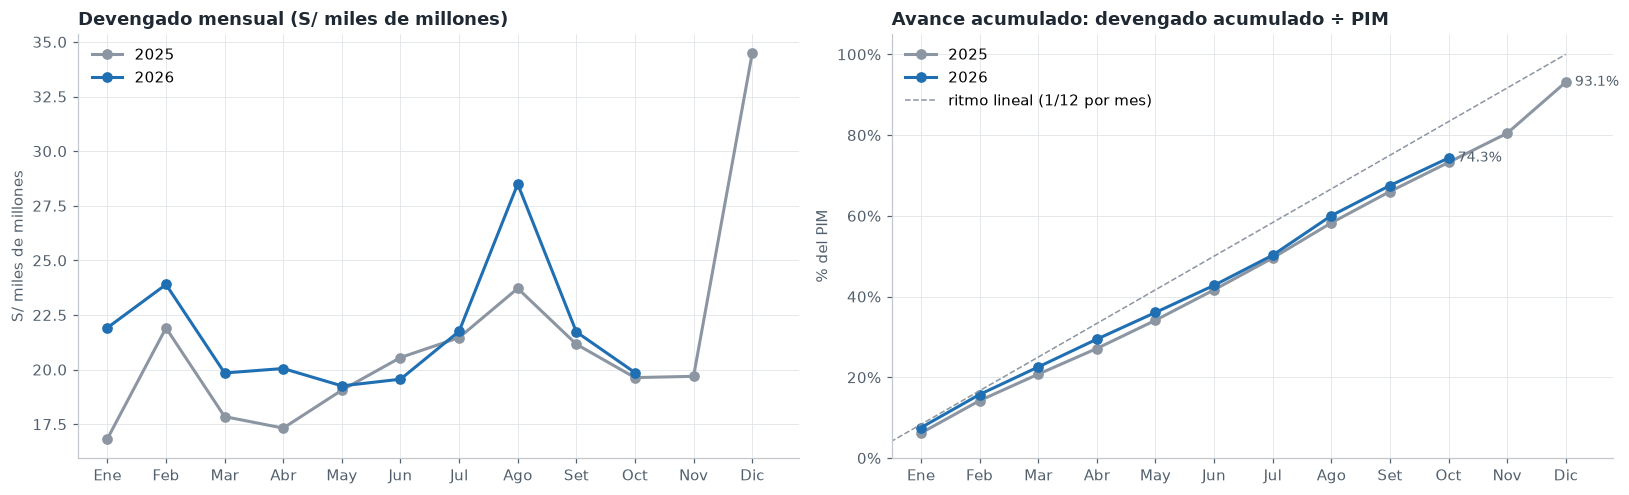

**Lectura automática**

- **Efecto diciembre:** en 2025, diciembre concentró el **13.6%** del devengado anual (un mes "promedio" sería 8.3 %) y el último trimestre el **29.1%**. El mes de mayor gasto fue diciembre.
- En 2025, el avance acumulado estuvo **por debajo del ritmo lineal** en 12 de 12 meses: la ejecución se posterga hacia el cierre del año.
- **A igual corte (enero–octubre)**, 2026 devengó S/ 216,371.2 M, una variación de **+8.5%** frente al mismo periodo de 2025.

In [27]:
# 6.3.a Estacionalidad: devengado mensual y avance acumulado (dos gráficos, un solo eje cada uno).
mensual = fact_gasto_mensual.groupby("fecha")["monto_devengado"].sum()
pim_anio = resumen()["monto_pim"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for anio in ANIOS:
    s = mensual[mensual.index.year == anio]
    s.index = s.index.month
    axes[0].plot(s.index, s.values, marker="o", lw=2, ms=6, color=COLOR_ANIO[anio], label=str(anio))
    acum = s.cumsum() / pim_anio[anio]
    axes[1].plot(acum.index, acum.values, marker="o", lw=2, ms=6, color=COLOR_ANIO[anio], label=str(anio))
    axes[1].annotate(f"{acum.iloc[-1]:.1%}", (acum.index[-1], acum.iloc[-1]), xytext=(6, 0), textcoords="offset points",
                     va="center", fontsize=9, color=TINTA_2)
axes[1].plot([0, 12], [0, 1], ls="--", lw=1, color=GRIS, label="ritmo lineal (1/12 por mes)")
axes[0].set(title="Devengado mensual (S/ miles de millones)", ylabel="S/ miles de millones")
axes[0].yaxis.set_major_formatter(EJE_MIL_MILLONES)
axes[1].set(title="Avance acumulado: devengado acumulado ÷ PIM", ylabel="% del PIM", ylim=(0, 1.05))
axes[1].yaxis.set_major_formatter(EJE_PCT)
for ax in axes:
    ax.set_xticks(range(1, 13), MES_ABREV)
    ax.set_xlim(0.5, 12.8)
    ax.legend()
plt.tight_layout()
guardar(fig, "estacionalidad_mensual.png")
plt.show()

s0 = mensual[mensual.index.year == a0]
dic, t4 = s0.iloc[-1] / s0.sum(), s0.iloc[-3:].sum() / s0.sum()
s1 = mensual[mensual.index.year == a1]
s1 = s1[s1.index.month <= CORTE]
var_corte = s1.sum() / s0[s0.index.month <= CORTE].sum() - 1
mes_max = MESES[int(s0.idxmax().month) - 1].lower()
acum0 = s0.cumsum().to_numpy() / pim_anio[a0]
bajo_lineal = int((acum0 < np.arange(1, len(acum0) + 1) / 12).sum())
nota(f"""**Lectura automática**

- **Efecto diciembre:** en {a0}, diciembre concentró el **{dic:.1%}** del devengado anual (un mes "promedio" sería 8.3 %) y el último trimestre el **{t4:.1%}**. El mes de mayor gasto fue {mes_max}.
- En {a0}, el avance acumulado estuvo **por debajo del ritmo lineal** en {bajo_lineal} de 12 meses: {'la ejecución se posterga hacia el cierre del año' if bajo_lineal >= 6 else 'la ejecución siguió de cerca el calendario'}.
- **A igual corte (enero–{MESES[CORTE - 1].lower()})**, {a1} devengó {s_millones(s1.sum())}, una variación de **{var_corte:+.1%}** frente al mismo periodo de {a0}.""")

In [28]:
# 6.3.b Variación mensual, índice estacional, coeficiente de variación y correlación entre años.
filas = []
for anio in ANIOS:
    ult = int(dim_anio.set_index("anio").loc[anio, "mes_ultimo_dato"])
    s = dev_mes[anio].iloc[:ult]
    promedio = s.mean()
    for m, v in s.items():
        previo = s.get(m - 1, np.nan)
        filas.append({"anio": anio, "mes_num": int(m), "mes_abrev": MES_ABREV[m - 1], "fecha": pd.Timestamp(anio, m, 1),
                      "devengado": float(v), "variacion_mensual": (v / previo - 1) if pd.notna(previo) and previo else np.nan,
                      "indice_estacional": float(v / promedio), "participacion": float(v / s.sum()),
                      "trimestre": f"T{(m - 1) // 3 + 1}"})
estacionalidad_mensual = pd.DataFrame(filas)
cv = estacionalidad_mensual.groupby("anio")["devengado"].agg(lambda s: s.std() / s.mean())
comunes = estacionalidad_mensual[estacionalidad_mensual["mes_num"] <= CORTE].pivot(index="mes_num", columns="anio", values="devengado")
correlacion = float(np.corrcoef(comunes[a0], comunes[a1])[0, 1])
trimestral = (estacionalidad_mensual[estacionalidad_mensual["anio"] == a0].groupby("trimestre")["participacion"].sum())

display(estacionalidad_mensual.pivot(index="mes_abrev", columns="anio", values=["indice_estacional", "variacion_mensual"])
        .reindex(MES_ABREV).style.format("{:.2f}", subset="indice_estacional").format("{:+.1%}", subset="variacion_mensual", na_rep="—"))

if TIENE_PLOTLY:
    fig = make_subplots(rows=1, cols=2, subplot_titles=("Índice estacional (1 = mes promedio)", "Variación respecto del mes anterior"))
    for anio in ANIOS:
        g = estacionalidad_mensual[estacionalidad_mensual["anio"] == anio]
        fig.add_bar(x=g["mes_abrev"], y=g["indice_estacional"], name=ETIQUETA_ANIO[anio], marker_color=COLOR_ANIO[anio], row=1, col=1)
        fig.add_scatter(x=g["mes_abrev"], y=g["variacion_mensual"], mode="lines+markers", name=f"Variación {anio}",
                        line=dict(color=COLOR_ANIO[anio]), row=1, col=2)
    fig.add_hline(y=1, line_dash="dash", line_color=EJE, row=1, col=1)
    fig.add_hline(y=0, line_color=EJE, row=1, col=2)
    fig.update_yaxes(tickformat=".0%", row=1, col=2)
    fig.update_layout(title="Comportamiento mensual del devengado", barmode="group", height=430)
    mostrar(fig, "comportamiento_mensual")

e0 = estacionalidad_mensual[estacionalidad_mensual["anio"] == a0].set_index("mes_num")
pico, valle = int(e0["indice_estacional"].idxmax()), int(e0["indice_estacional"].idxmin())
nota(f"""**Lectura automática**

- **Patrón estacional:** en {a0} el mes más intenso fue **{MESES[pico - 1].lower()}** (índice {e0.loc[pico, 'indice_estacional']:.2f}) y el más bajo **{MESES[valle - 1].lower()}** ({e0.loc[valle, 'indice_estacional']:.2f}). El cuarto trimestre concentró el **{trimestral.get('T4', np.nan):.1%}** del gasto anual (25 % sería un reparto uniforme).
- **Regularidad:** coeficiente de variación mensual de **{cv[a0]:.2f}** en {a0} y **{cv[a1]:.2f}** en {a1} (meses con datos).
- **Estabilidad del patrón:** la correlación entre los perfiles mensuales de {a0} y {a1} (enero–{MESES[CORTE - 1].lower()}) es **r = {correlacion:.2f}**: {'el calendario de gasto se repite, lo que valida la proyección estacional' if correlacion >= 0.7 else 'el calendario cambió entre años; la proyección estacional debe tomarse con cautela'}.""")

**Lectura automática**

- **Patrón estacional:** en 2025 el mes más intenso fue **diciembre** (índice 1.63) y el más bajo **enero** (0.80). El cuarto trimestre concentró el **29.1%** del gasto anual (25 % sería un reparto uniforme).
- **Regularidad:** coeficiente de variación mensual de **0.22** en 2025 y **0.13** en 2026 (meses con datos).
- **Estabilidad del patrón:** la correlación entre los perfiles mensuales de 2025 y 2026 (enero–octubre) es **r = 0.70**: el calendario cambió entre años; la proyección estacional debe tomarse con cautela.

### 6.4 Línea 4 · Detección de patrones atípicos

Se buscan valores **inusuales** del PIA, PIM y devengado de cada unidad ejecutora con dos técnicas estadísticas complementarias:

| Técnica | Regla | Ventaja |
|---|---|---|
| **Rango intercuartílico (Tukey)** | Atípico si el valor está fuera de [Q1 − 1.5·IQR, Q3 + 1.5·IQR]; **extremo** si está fuera de 3·IQR | No supone una distribución; es la regla del diagrama de caja |
| **Puntaje z robusto** | z = 0.6745·(x − mediana) ÷ MAD; atípico si \|z\| > 3.5 (Iglewicz y Hoaglin) | Usa la mediana y la desviación absoluta mediana, que los propios atípicos no distorsionan |

**Decisiones de método**

- Los montos del presupuesto son muy asimétricos (pocas entidades muy grandes y miles pequeñas). En escala original *todo* ministerio grande sería "atípico", así que los montos se analizan en **escala logarítmica** y **dentro de cada nivel de gobierno** (una municipalidad se compara con municipalidades).
- Además de los montos, se evalúan dos **relaciones** que revelan anomalías de gestión: la **modificación PIM ÷ PIA** (presupuestos que crecen o se recortan de forma inusual) y el **avance devengado ÷ PIM**.
- Un atípico **no es un error**: es una alerta para revisar (una transferencia extraordinaria, una obra grande, un registro mal hecho).

In [29]:
# 6.4 Atípicos en PIA, PIM, devengado y sus relaciones, por unidad ejecutora (IQR de Tukey y z robusto).
Z_UMBRAL, K_IQR, K_EXTREMO = 3.5, 1.5, 3.0
ue_m = (fact_presupuesto_anual.groupby(["anio", "entidad_key"])[["monto_pia", "monto_pim", "monto_devengado"]].sum().reset_index()
        .merge(DIM["dim_entidad"][["entidad_key", "nivel_gobierno_nombre", "ejecutora_etiqueta"]], on="entidad_key"))
ue_m = ue_m[ue_m["monto_pim"] > 0].copy()
ue_m["modificacion"] = (ue_m["monto_pim"] / ue_m["monto_pia"]).where(ue_m["monto_pia"] > 0)
ue_m["avance_ue"] = ue_m["monto_devengado"] / ue_m["monto_pim"]
VARIABLES_ATIP = {   # nombre: (columna, transformación, inversa, unidad)
    "PIA": ("monto_pia", np.log10, lambda v: 10 ** v, "S/"),
    "PIM": ("monto_pim", np.log10, lambda v: 10 ** v, "S/"),
    "Devengado": ("monto_devengado", np.log10, lambda v: 10 ** v, "S/"),
    "Modificación PIM ÷ PIA": ("modificacion", np.log10, lambda v: 10 ** v, "veces"),
    "Avance devengado ÷ PIM": ("avance_ue", lambda v: v, lambda v: v, "%"),
}
registros, resumen_atip = [], []
for (anio, nivel), g in ue_m.groupby(["anio", "nivel_gobierno_nombre"], observed=True):
    for var, (colname, f, inv, unidad) in VARIABLES_ATIP.items():
        x = g[colname]
        x = x[(x > 0) if f is np.log10 else x.notna()]
        if len(x) < 10:
            continue
        t = f(x.astype(float))
        q1, q3 = t.quantile([0.25, 0.75])
        iqr = q3 - q1
        med = t.median()
        mad = (t - med).abs().median()
        z = 0.6745 * (t - med) / mad if mad > 0 else pd.Series(0.0, index=t.index)
        fuera_iqr = (t < q1 - K_IQR * iqr) | (t > q3 + K_IQR * iqr)
        extremo = (t < q1 - K_EXTREMO * iqr) | (t > q3 + K_EXTREMO * iqr)
        fuera_z = z.abs() > Z_UMBRAL
        resumen_atip.append({"anio": anio, "nivel": nivel, "variable": var, "n": len(t), "atipicos_iqr": int(fuera_iqr.sum()),
                             "atipicos_z": int(fuera_z.sum()), "ambos": int((fuera_iqr & fuera_z).sum())})
        marcados = t.index[fuera_iqr | fuera_z]
        for i in marcados:
            registros.append({"anio": int(anio), "entidad_key": int(g.loc[i, "entidad_key"]), "nivel_gobierno": nivel, "variable": var,
                              "unidad": unidad, "valor": float(x.loc[i]), "mediana_grupo": float(inv(med)),
                              "limite_inferior": float(inv(q1 - K_IQR * iqr)), "limite_superior": float(inv(q3 + K_IQR * iqr)),
                              "z_robusta": float(z.loc[i]), "tipo": "Alto" if t.loc[i] > med else "Bajo",
                              "tecnica": "IQR y z robusto" if (fuera_iqr.loc[i] and fuera_z.loc[i]) else ("Solo IQR" if fuera_iqr.loc[i] else "Solo z robusto"),
                              "severidad": "Extremo" if extremo.loc[i] else "Moderado"})
atipicos_entidades = pd.DataFrame(registros)
resumen_atip = pd.DataFrame(resumen_atip)
tabla_resumen_atip = resumen_atip.groupby(["variable", "anio"])[["n", "atipicos_iqr", "atipicos_z", "ambos"]].sum().unstack("anio")
display(tabla_resumen_atip)

confirmados = atipicos_entidades[atipicos_entidades["tecnica"] == "IQR y z robusto"].merge(
    DIM["dim_entidad"][["entidad_key", "ejecutora_etiqueta"]], on="entidad_key")
top_atip = (confirmados[confirmados["anio"] == a1].assign(abs_z=lambda d: d["z_robusta"].abs())
            .nlargest(12, "abs_z")[["variable", "nivel_gobierno", "ejecutora_etiqueta", "valor", "mediana_grupo", "z_robusta", "tipo", "severidad"]])
display(top_atip.style.format({"valor": "{:,.2f}", "mediana_grupo": "{:,.2f}", "z_robusta": "{:+.1f}"}))
atipicos_entidades.to_csv(OUTPUTS / "atipicos_entidades.csv", index=False, encoding="utf-8-sig")

if TIENE_PLOTLY:
    largo = []
    for var in ["PIA", "PIM", "Devengado"]:
        colname = VARIABLES_ATIP[var][0]
        d = ue_m[(ue_m["anio"] == a1) & (ue_m[colname] > 0)]
        largo.append(pd.DataFrame({"variable": var, "nivel": d["nivel_gobierno_nombre"].astype(str), "monto": d[colname],
                                   "ejecutora": d["ejecutora_etiqueta"]}))
    largo = pd.concat(largo)
    fig = px.box(largo, x="variable", y="monto", color="nivel", points="outliers", log_y=True, hover_data=["ejecutora"],
                 color_discrete_sequence=[AZUL, GRIS, COLOR_META])
    fig.update_layout(title=f"Distribución del PIA, PIM y devengado {a1} por unidad ejecutora (escala logarítmica): los puntos son atípicos",
                      yaxis_title="S/ (escala log)", height=480)
    mostrar(fig, "atipicos_cajas")

    mod = ue_m[(ue_m["anio"] == a1) & (ue_m["monto_pia"] > 0)].copy()
    mod["atipico"] = mod["entidad_key"].isin(atipicos_entidades.query("anio == @a1 and variable == 'Modificación PIM ÷ PIA'")["entidad_key"])
    fig = px.scatter(mod, x="monto_pia", y="monto_pim", color=mod["atipico"].map({True: "Modificación atípica", False: "Normal"}),
                     log_x=True, log_y=True, hover_data=["ejecutora_etiqueta"], opacity=0.6,
                     color_discrete_map={"Modificación atípica": ESTADO["critico"], "Normal": GRIS})
    lim = [mod["monto_pia"].min(), mod["monto_pia"].max()]
    fig.add_scatter(x=lim, y=lim, mode="lines", line=dict(color=TINTA_2, dash="dash"), name="PIM = PIA")
    fig.update_layout(title=f"PIA frente a PIM {a1} por unidad ejecutora: alejarse de la diagonal = modificación grande",
                      xaxis_title="PIA (S/, escala log)", yaxis_title="PIM (S/, escala log)", legend_title_text="", height=480)
    mostrar(fig, "atipicos_modificacion")

# Meses atípicos a nivel nacional (regla IQR sobre los 12 meses del año base).
s_mes = dev_mes[a0]
q1m, q3m = s_mes.quantile([0.25, 0.75])
meses_atip = [MESES[m - 1].lower() for m in s_mes.index if s_mes[m] > q3m + K_IQR * (q3m - q1m) or s_mes[m] < q1m - K_IQR * (q3m - q1m)]
n_conf = len(confirmados[confirmados["anio"] == a1])
var_top = confirmados[confirmados["anio"] == a1]["variable"].value_counts().idxmax() if n_conf else "—"
EXPLICA_ATIP = {
    "Modificación PIM ÷ PIA": "Un PIM muy por encima del PIA suele deberse a transferencias de partidas o créditos suplementarios recibidos durante el año.",
    "Avance devengado ÷ PIM": "Son unidades ejecutoras con un avance muy por debajo (o por encima) de sus pares: candidatas a seguimiento en el POA.",
    "PIA": "Son presupuestos de apertura inusualmente grandes o pequeños para su nivel de gobierno.",
    "PIM": "Son presupuestos vigentes inusualmente grandes o pequeños para su nivel de gobierno.",
    "Devengado": "Son ejecuciones inusualmente grandes o pequeñas para su nivel de gobierno."}
nota(f"""**Lectura automática**

- En {a1} se detectan **{len(atipicos_entidades[atipicos_entidades['anio'] == a1]):,}** valores atípicos por al menos una técnica; **{n_conf:,}** son confirmados por **ambas** (IQR y z robusto), y son los que conviene revisar primero.
- La variable con más atípicos confirmados es **{var_top}**. {EXPLICA_ATIP.get(var_top, '')}
- **Meses atípicos** del gasto nacional en {a0} (regla IQR): {', '.join(meses_atip) if meses_atip else 'ninguno'}. {'Confirma el efecto diciembre de la línea 3.' if 'diciembre' in meses_atip else ''}
- El detalle completo está en `outputs/{CARPETA}/atipicos_entidades.csv` y en Gold (`atipicos_entidades`).""")

n       atipicos_iqr      atipicos_z      ambos  \
anio                    2025  2026         2025 2026       2025 2026  2025   
variable                                                                     
Avance devengado ÷ PIM  2873  2883          145  118        135  107   130   
Devengado               2864  2876           73   66         26   20    26   
Modificación PIM ÷ PIA  2824  2836          217  146        132  115   132   
PIA                     2824  2836           46   38         14   10    14   
PIM                     2873  2883           83   80         36   31    36   

                             
anio                   2026  
variable                     
Avance devengado ÷ PIM  100  
Devengado                20  
Modificación PIM ÷ PIA  115  
PIA                      10  
PIM                      31

,variable,nivel_gobierno,ejecutora_etiqueta,valor,mediana_grupo,z_robusta,tipo,severidad
515,Modificación PIM ÷ PIA,GOBIERNOS REGIONALES,1460 · GOB. REG. DE PASCO - PASCO SELVA CENTRAL,14.68,1.09,+27.4,Alto,Extremo
524,Modificación PIM ÷ PIA,GOBIERNOS REGIONALES,1742 · GOB. REG. DE JUNIN - EDUCACION RIO ENE MANTARO,9.56,1.09,+22.9,Alto,Extremo
537,Modificación PIM ÷ PIA,GOBIERNOS REGIONALES,814 · REGION ICA-AGRICULTURA,9.42,1.09,+22.7,Alto,Extremo
518,Modificación PIM ÷ PIA,GOBIERNOS REGIONALES,1546 · GOB. REG. DE APURIMAC- GERENCIA SUB REGIONAL COTABAMBAS,8.02,1.09,+21.0,Alto,Extremo
578,Avance devengado ÷ PIM,GOBIERNOS REGIONALES,360003 · MANCOMUNIDAD REGIONAL AMAZONICA - MRA,0.00,0.81,-19.0,Bajo,Extremo
358,Modificación PIM ÷ PIA,GOBIERNO NACIONAL,1766 · UNIVERSIDAD NACIONAL DEL VRAEM - UNAVRAEM,0.09,1.05,-18.5,Bajo,Extremo
526,Modificación PIM ÷ PIA,GOBIERNOS REGIONALES,727 · REGION ANCASH-AGRICULTURA ANCASH,4.95,1.09,+15.9,Alto,Extremo
356,Modificación PIM ÷ PIA,GOBIERNO NACIONAL,1719 · MODERNIZACIÓN DE LA PRESTACIÓN DE LOS SERVICIOS DE AGUA POTABLE Y SANEAMIENTO DE LAS EPSS,8.70,1.05,+15.8,Alto,Extremo
522,Modificación PIM ÷ PIA,GOBIERNOS REGIONALES,1710 · GOB. REG. DEL DPTO. DE ANCASH - AUTORIDAD PORTUARIA REGIONAL DE ANCASH,0.25,1.09,-15.4,Bajo,Extremo
576,Avance devengado ÷ PIM,GOBIERNOS REGIONALES,1775 · GOB. REG. DE JUNIN - GERENCIA SUB REGIONAL CHANCHAMAYO,0.19,0.81,-14.5,Bajo,Extremo


**Lectura automática**

- En 2026 se detectan **455** valores atípicos por al menos una técnica; **276** son confirmados por **ambas** (IQR y z robusto), y son los que conviene revisar primero.
- La variable con más atípicos confirmados es **Modificación PIM ÷ PIA**. Un PIM muy por encima del PIA suele deberse a transferencias de partidas o créditos suplementarios recibidos durante el año.
- **Meses atípicos** del gasto nacional en 2025 (regla IQR): diciembre. Confirma el efecto diciembre de la línea 3.
- El detalle completo está en `outputs/gasto_publico/atipicos_entidades.csv` y en Gold (`atipicos_entidades`).

### 6.5 Línea 5 · Análisis de variaciones

Se examinan los cambios del presupuesto **por entidad, función, categoría y genérica de gasto** con tres medidas:

| Medida | Fórmula | Qué revela |
|---|---|---|
| **Modificación presupuestal** | (PIM − PIA) ÷ PIA del año | Cuánto cambió lo aprobado durante el año |
| **Variación interanual del PIM** | PIM año 2 ÷ PIM año 1 − 1 | Crecimiento o recorte de la asignación |
| **Variación del devengado a igual corte** | Devengado ene–corte año 2 ÷ mismo periodo año 1 − 1 | Si se gasta más o menos que el año anterior |
| **Contribución a la variación** | (PIM año 2 − PIM año 1) ÷ PIM total año 1 | Qué categorías explican el cambio total (en puntos) |

"Categoría" se analiza de dos formas: la **categoría de gasto** (corriente, capital, deuda) y la **categoría presupuestal** (programas presupuestales y acciones centrales).

In [30]:
# 6.5.a Variaciones por entidad (pliego), función, categoría de gasto, categoría presupuestal y genérica.
DIMS_VARIACION = {"Entidad (pliego)": "pliego_nombre", "Función": "funcion_nombre", "Categoría de gasto": "categoria_gasto_nombre",
                  "Categoría presupuestal": "programa_etiqueta", "Genérica de gasto": "generica_nombre"}


def variaciones(por):
    t = base.groupby(["anio", por], observed=True)[["monto_pia", "monto_pim", "monto_devengado", "dev_comparable"]].sum().unstack("anio")
    pim_total0 = t[("monto_pim", a0)].sum()
    out = pd.DataFrame({
        f"PIA {a1}": t[("monto_pia", a1)], f"PIM {a1}": t[("monto_pim", a1)],
        f"modificación {a1} (S/)": t[("monto_pim", a1)] - t[("monto_pia", a1)],
        f"modificación {a1} %": (t[("monto_pim", a1)] / t[("monto_pia", a1)] - 1).where(t[("monto_pia", a1)] > 0),
        f"modificación {a0} %": (t[("monto_pim", a0)] / t[("monto_pia", a0)] - 1).where(t[("monto_pia", a0)] > 0),
        "var. PIA %": (t[("monto_pia", a1)] / t[("monto_pia", a0)] - 1).where(t[("monto_pia", a0)] > 0),
        "var. PIM %": (t[("monto_pim", a1)] / t[("monto_pim", a0)] - 1).where(t[("monto_pim", a0)] > 0),
        "var. devengado igual corte %": (t[("dev_comparable", a1)] / t[("dev_comparable", a0)] - 1).where(t[("dev_comparable", a0)] > 0),
        "contribución a la var. del PIM (pp)": (t[("monto_pim", a1)].fillna(0) - t[("monto_pim", a0)].fillna(0)) / pim_total0,
    })
    return out.sort_values(f"PIM {a1}", ascending=False)


VARIACIONES = {}
for nombre, columna in DIMS_VARIACION.items():
    v = variaciones(columna)
    VARIACIONES[nombre] = v
    v.to_csv(OUTPUTS / f"variaciones_{columna}.csv", encoding="utf-8-sig")
fmt_var = lambda df: df.style.format({c: ("S/ {:,.0f}" if "(S/)" in c or c.startswith(("PIA", "PIM")) else
                                          ("{:+.2%}" if "pp" in c else "{:+.1%}")) for c in df.columns}, na_rep="—")
display(fmt_var(VARIACIONES["Función"].head(TOP_N)))
display(fmt_var(VARIACIONES["Genérica de gasto"]))

if TIENE_PLOTLY:
    fig = make_subplots(rows=2, cols=2, horizontal_spacing=0.28, vertical_spacing=0.16,
                        subplot_titles=["Función (10 de mayor PIM)", "Genérica de gasto", "Categoría de gasto", "Entidad: 10 pliegos con mayor contribución"])
    paneles = [("Función", 1, 1, 10), ("Genérica de gasto", 1, 2, 10), ("Categoría de gasto", 2, 1, 10)]
    for nombre, r, c, n in paneles:
        v = VARIACIONES[nombre].head(n).iloc[::-1]
        fig.add_bar(y=[str(i)[:34] for i in v.index], x=v["var. PIM %"], orientation="h", marker_color=AZUL, showlegend=False,
                    text=[f"{x:+.1%}" for x in v["var. PIM %"]], textposition="outside", row=r, col=c)
    p = VARIACIONES["Entidad (pliego)"]
    p = p.reindex(p["contribución a la var. del PIM (pp)"].abs().sort_values(ascending=False).index).head(10).iloc[::-1]
    fig.add_bar(y=[str(i)[:34] for i in p.index], x=p["contribución a la var. del PIM (pp)"], orientation="h", marker_color=COLOR_META,
                showlegend=False, text=[f"{x * 100:+.2f} pp" for x in p["contribución a la var. del PIM (pp)"]], textposition="outside", row=2, col=2)
    fig.update_xaxes(tickformat=".0%")
    fig.update_layout(title=f"Variación interanual del PIM {a1} vs {a0} y contribución por entidad", height=760)
    mostrar(fig, "variaciones_dimensiones")

f_ = VARIACIONES["Función"]
f_ = f_[f_[f"PIM {a1}"] >= 0.01 * f_[f"PIM {a1}"].sum()]
g_ = VARIACIONES["Genérica de gasto"]
p_ = VARIACIONES["Entidad (pliego)"]
nota(f"""**Lectura automática**

- **Función:** entre las funciones con PIM ≥ 1 % del total, la que más crece es **{str(f_['var. PIM %'].idxmax()).title()}** ({f_['var. PIM %'].max():+.1%}) y la que más se reduce **{str(f_['var. PIM %'].idxmin()).title()}** ({f_['var. PIM %'].min():+.1%}).
- **Genérica:** la mayor modificación PIA→PIM de {a1} está en **{str(g_[f'modificación {a1} %'].idxmax()).title()}** ({g_[f'modificación {a1} %'].max():+.1%}).
- **Entidad:** el pliego que más aporta a la variación total del PIM es **{str(p_['contribución a la var. del PIM (pp)'].idxmax()).title()}** ({p_['contribución a la var. del PIM (pp)'].max() * 100:+.2f} puntos) y el que más la reduce **{str(p_['contribución a la var. del PIM (pp)'].idxmin()).title()}** ({p_['contribución a la var. del PIM (pp)'].min() * 100:+.2f} puntos).
- Las tablas completas están en `outputs/{CARPETA}/variaciones_*.csv`. A continuación se complementa con el detalle por nivel de gobierno, sector, fuente y departamento.""")

,PIA 2026,PIM 2026,modificación 2026 (S/),modificación 2026 %,modificación 2025 %,var. PIA %,var. PIM %,var. devengado igual corte %,contribución a la var. del PIM (pp)
funcion_nombre,,,,,,,,,
EDUCACION,"S/ 48,707,652,461","S/ 52,332,322,738","S/ 3,624,670,277",+7.4%,+3.9%,+0.6%,+4.0%,+5.2%,+0.74%
SALUD,"S/ 32,887,683,068","S/ 35,912,364,107","S/ 3,024,681,039",+9.2%,+9.1%,+7.3%,+7.3%,+9.3%,+0.90%
DEUDA PUBLICA,"S/ 32,386,484,900","S/ 31,524,351,476","S/ -862,133,424",-2.7%,+1.8%,+19.0%,+13.8%,+6.7%,+1.40%
"PLANEAMIENTO, GESTION Y RESERVA DE CONTINGENCIA","S/ 30,080,131,333","S/ 29,845,268,728","S/ -234,862,605",-0.8%,-12.6%,-6.1%,+6.6%,+9.6%,+0.68%
TRANSPORTE,"S/ 22,325,009,055","S/ 29,435,525,012","S/ 7,110,515,957",+31.9%,+25.5%,-3.6%,+1.3%,+5.0%,+0.13%
PREVISION SOCIAL,"S/ 16,075,452,252","S/ 18,060,145,464","S/ 1,984,693,212",+12.3%,+23.2%,+7.2%,-2.2%,+9.5%,-0.15%
ORDEN PUBLICO Y SEGURIDAD,"S/ 15,857,565,131","S/ 17,859,513,888","S/ 2,001,948,757",+12.6%,+6.1%,-3.1%,+2.9%,+6.7%,+0.18%
PROTECCION SOCIAL,"S/ 10,688,747,267","S/ 11,068,521,670","S/ 379,774,403",+3.6%,+1.1%,+2.6%,+5.1%,+5.3%,+0.20%
AGROPECUARIA,"S/ 6,383,254,972","S/ 9,629,310,060","S/ 3,246,055,088",+50.9%,+25.9%,-12.8%,+4.5%,-2.1%,+0.15%


,PIA 2026,PIM 2026,modificación 2026 (S/),modificación 2026 %,modificación 2025 %,var. PIA %,var. PIM %,var. devengado igual corte %,contribución a la var. del PIM (pp)
generica_nombre,,,,,,,,,
PERSONAL Y OBLIGACIONES SOCIALES,"S/ 93,956,938,130","S/ 94,049,420,328","S/ 92,482,198",+0.1%,+3.5%,+12.3%,+8.6%,+10.0%,+2.73%
ADQUISICION DE ACTIVOS NO FINANCIEROS,"S/ 50,084,197,912","S/ 75,782,117,638","S/ 25,697,919,726",+51.3%,+27.5%,-13.2%,+3.0%,+8.0%,+0.80%
BIENES Y SERVICIOS,"S/ 38,688,038,216","S/ 49,539,213,604","S/ 10,851,175,388",+28.0%,+14.6%,-0.3%,+11.5%,+8.8%,+1.87%
SERVICIO DE LA DEUDA PUBLICA,"S/ 32,728,106,021","S/ 31,856,842,556","S/ -871,263,465",-2.7%,+1.9%,+18.7%,+13.4%,+6.3%,+1.38%
PENSIONES Y OTRAS PRESTACIONES SOCIALES,"S/ 16,471,150,275","S/ 16,578,033,071","S/ 106,882,796",+0.6%,+1.3%,+6.0%,+5.3%,+4.5%,+0.31%
OTROS GASTOS,"S/ 10,479,313,288","S/ 14,128,829,542","S/ 3,649,516,254",+34.8%,+35.5%,+1.2%,+0.7%,+18.7%,+0.03%
DONACIONES Y TRANSFERENCIAS,"S/ 10,613,230,320","S/ 8,299,230,014","S/ -2,314,000,306",-21.8%,-22.4%,-2.2%,-1.4%,-4.9%,-0.04%
ADQUISICION DE ACTIVOS FINANCIEROS,"S/ 480,047,428","S/ 470,124,182","S/ -9,923,246",-2.1%,-3.3%,+4.1%,+5.4%,+3.3%,+0.01%
RESERVA DE CONTINGENCIA,"S/ 4,060,597,553","S/ 431,504,391","S/ -3,629,093,162",-89.4%,-84.5%,-40.9%,-59.4%,—,-0.23%


**Lectura automática**

- **Función:** entre las funciones con PIM ≥ 1 % del total, la que más crece es **Defensa Y Seguridad Nacional** (+40.5%) y la que más se reduce **Prevision Social** (-2.2%).
- **Genérica:** la mayor modificación PIA→PIM de 2026 está en **Adquisicion De Activos No Financieros** (+51.3%).
- **Entidad:** el pliego que más aporta a la variación total del PIM es **Gobiernos Locales** (+1.98 puntos) y el que más la reduce **Ministerio De Transportes Y Comunicaciones** (-0.70 puntos).
- Las tablas completas están en `outputs/gasto_publico/variaciones_*.csv`. A continuación se complementa con el detalle por nivel de gobierno, sector, fuente y departamento.

,PIM 2026,avance 2025 al corte,avance 2026 al corte,avance 2025 anual,var. devengado comparable
nivel_gobierno_nombre,,,,,
GOBIERNO NACIONAL,"S/ 164,722,376,393",76.2%,77.9%,95.9%,7.0%
GOBIERNOS REGIONALES,"S/ 67,396,721,381",76.6%,77.3%,96.8%,10.5%
GOBIERNOS LOCALES,"S/ 59,016,217,552",60.6%,61.1%,80.6%,10.9%


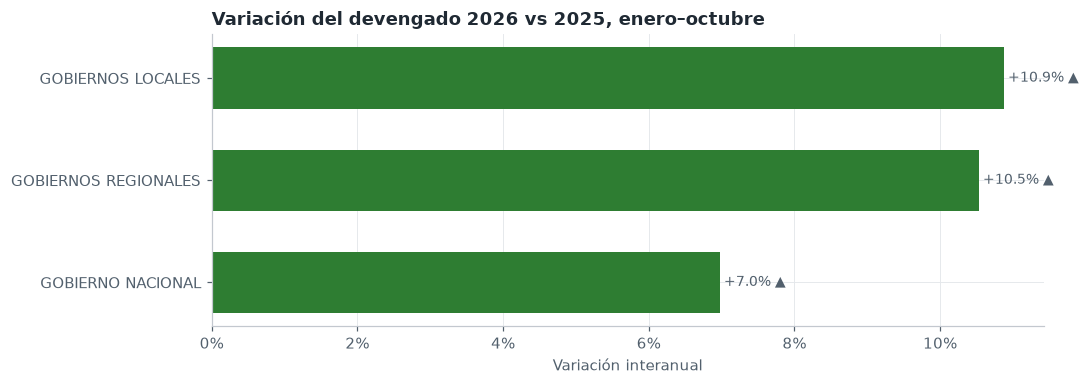

**Lectura automática:** Gobierno Nacional: avance al corte 76.2% (2025) → 77.9% (2026), devengado +7.0% · Gobiernos Regionales: avance al corte 76.6% (2025) → 77.3% (2026), devengado +10.5% · Gobiernos Locales: avance al corte 60.6% (2025) → 61.1% (2026), devengado +10.9%

In [31]:
# 6.5.b Variación interanual a igual corte por nivel de gobierno.
niv = comparar("nivel_gobierno_nombre")
display(niv.style.format({c: ("{:.1%}" if "avance" in c or "var." in c else "S/ {:,.0f}") for c in niv.columns}))

fig, ax = plt.subplots(figsize=(10, 3.6))
v = niv["var. devengado comparable"].sort_values()
colores = [ESTADO["critico"] if x < 0 else ESTADO["bueno"] for x in v]
ax.barh(v.index.astype(str), v.values, color=colores, height=0.6)
for i, x in enumerate(v.values):
    ax.text(x, i, f" {x:+.1%} " + ("▼" if x < 0 else "▲"), va="center", ha="left" if x >= 0 else "right", fontsize=9, color=TINTA_2)
ax.axvline(0, color=EJE, lw=1)
ax.xaxis.set_major_formatter(EJE_PCT)
ax.set(title=f"Variación del devengado {a1} vs {a0}, enero–{MESES[CORTE - 1].lower()}", xlabel="Variación interanual")
plt.tight_layout()
guardar(fig, "variacion_interanual_nivel.png")
plt.show()
nota("**Lectura automática:** " + " · ".join(
    f"{n.title()}: avance al corte {f[f'avance {a0} al corte']:.1%} ({a0}) → {f[f'avance {a1} al corte']:.1%} ({a1}), devengado {f['var. devengado comparable']:+.1%}"
    for n, f in niv.iterrows()))

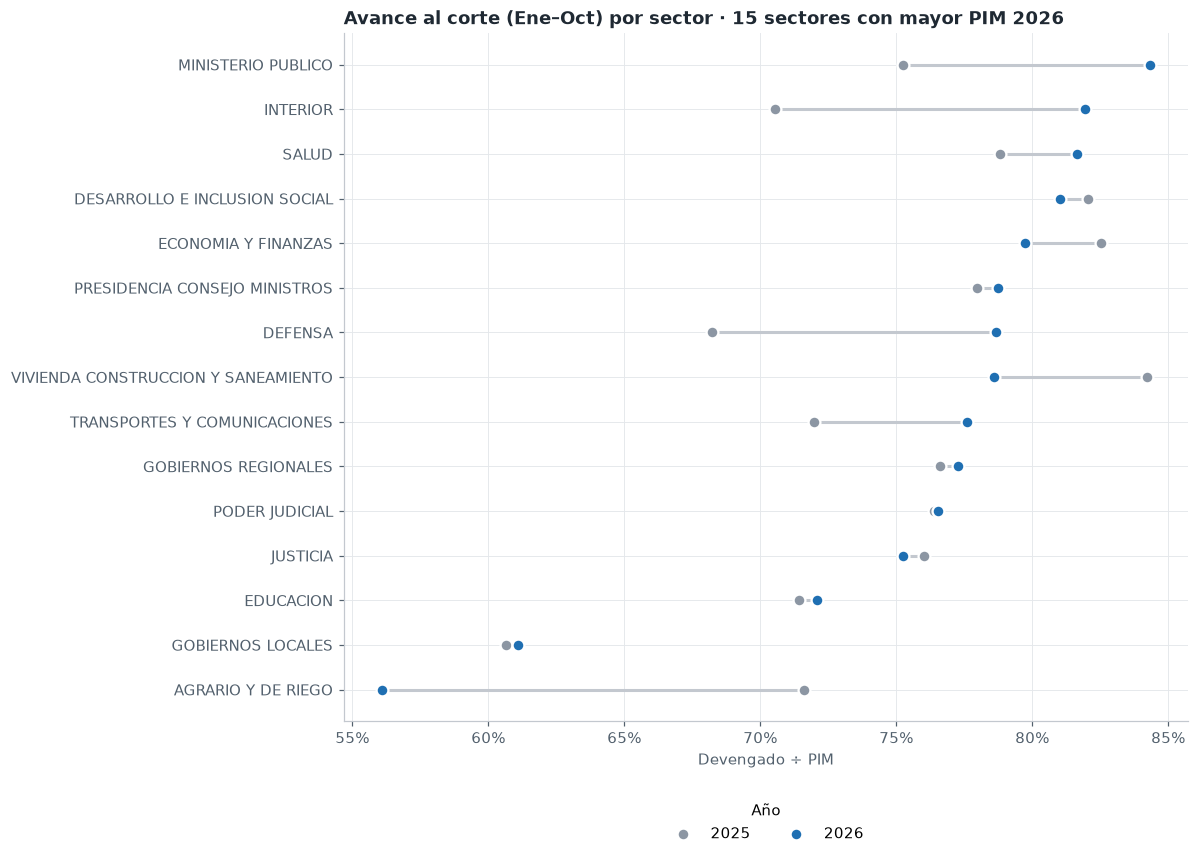

**Lectura automática:** entre los 15 sectores con más PIM, **Ministerio Publico** lidera con 84.3% y **Agrario Y De Riego** es el más rezagado con 56.1% al corte de 2026. Sectores con pesas largas cambiaron mucho su ritmo frente a 2025.

In [32]:
# 6.5.c Sectores: avance a igual corte en ambos años (gráfico de pesas; los 15 sectores con más PIM).
sec = comparar("sector_nombre").head(TOP_N)
sec = sec.sort_values(f"avance {a1} al corte")
fig, ax = plt.subplots(figsize=(11, 1.6 + 0.42 * len(sec)))
y = np.arange(len(sec))
ax.hlines(y, sec[f"avance {a0} al corte"], sec[f"avance {a1} al corte"], color=EJE, lw=2)
for anio in ANIOS:
    ax.scatter(sec[f"avance {anio} al corte"], y, s=60, color=COLOR_ANIO[anio], zorder=3, label=str(anio), edgecolor="white", linewidth=1.5)
ax.set_yticks(y, [s[:42] for s in sec.index.astype(str)])
ax.xaxis.set_major_formatter(EJE_PCT)
ax.set(title=f"Avance al corte (Ene–{MES_ABREV[CORTE - 1]}) por sector · {TOP_N} sectores con mayor PIM {a1}", xlabel="Devengado ÷ PIM")
ax.legend(title="Año", loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
plt.tight_layout()
guardar(fig, "avance_sectores.png")
plt.show()
mejor, peor = sec.index[-1], sec.index[0]
nota(f"**Lectura automática:** entre los {TOP_N} sectores con más PIM, **{str(mejor).title()}** lidera con {sec.loc[mejor, f'avance {a1} al corte']:.1%} "
     f"y **{str(peor).title()}** es el más rezagado con {sec.loc[peor, f'avance {a1} al corte']:.1%} al corte de {a1}. "
     f"Sectores con pesas largas cambiaron mucho su ritmo frente a {a0}.")

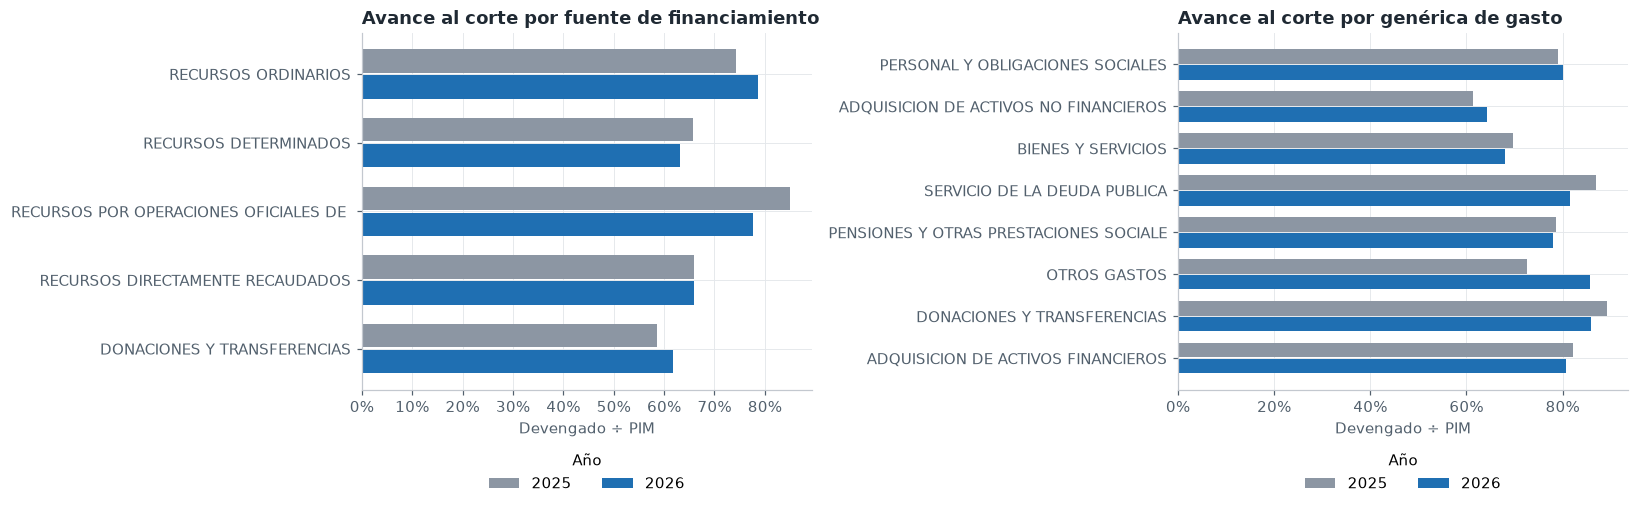

,PIM 2026,avance 2025 al corte,avance 2026 al corte,avance 2025 anual,var. devengado comparable
tipo_intervencion,,,,,
Actividad,"S/ 217,680,683,985",77.1%,77.5%,96.2%,8.5%
Proyecto,"S/ 73,454,631,341",62.2%,65.0%,84.3%,8.3%


**Lectura automática**

- **Proyectos (inversión) frente a actividades (gasto operativo):** al corte de 2026, los proyectos avanzan **65.0%** y las actividades **77.5%**. En 2025, los proyectos cerraron el año con 84.3%.
- La fuente con menor avance al corte de 2026 es **Donaciones Y Transferencias** (61.7%); la de mayor PIM es Recursos Ordinarios.
- Por genérica, la de mayor avance al corte de 2026 es **Donaciones Y Transferencias** (86.0%) y la de menor, **Adquisicion De Activos No Financieros** (64.4%) — solo genéricas con PIM 2026 ≥ 1 % del total.

In [33]:
# 6.5.d Fuente de financiamiento, genérica de gasto (genérica) e intervención: ¿dónde está el rezago?
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, por, titulo in [(axes[0], "fuente_financiamiento_nombre", "fuente de financiamiento"),
                        (axes[1], "generica_nombre", "genérica de gasto")]:
    t = comparar(por).head(8).iloc[::-1]
    y = np.arange(len(t))
    for i, anio in enumerate(ANIOS):
        ax.barh(y + (0.5 - i) * 0.38, t[f"avance {anio} al corte"], height=0.34, color=COLOR_ANIO[anio], label=str(anio))
    ax.set_yticks(y, [s[:38] for s in t.index.astype(str)])
    ax.xaxis.set_major_formatter(EJE_PCT)
    ax.set(title=f"Avance al corte por {titulo}", xlabel="Devengado ÷ PIM")
    ax.legend(title="Año", loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
plt.tight_layout()
guardar(fig, "avance_fuente_generica.png")
plt.show()

tip = comparar("tipo_intervencion")
fue = comparar("fuente_financiamiento_nombre")
gen = comparar("generica_nombre")
gen = gen[gen[f"PIM {a1}"] >= 0.01 * gen[f"PIM {a1}"].sum()]
display(tip.style.format({c: ("{:.1%}" if "avance" in c or "var." in c else "S/ {:,.0f}") for c in tip.columns}))
act = tip.index[tip.index.astype(str).str.upper().str.startswith("ACT")][0]
pro = tip.index[tip.index.astype(str).str.upper().str.startswith("PRO")][0]
nota(f"""**Lectura automática**

- **Proyectos (inversión) frente a actividades (gasto operativo):** al corte de {a1}, los proyectos avanzan **{tip.loc[pro, f'avance {a1} al corte']:.1%}** y las actividades **{tip.loc[act, f'avance {a1} al corte']:.1%}**. En {a0}, los proyectos cerraron el año con {tip.loc[pro, f'avance {a0} anual']:.1%}.
- La fuente con menor avance al corte de {a1} es **{str(fue[f'avance {a1} al corte'].idxmin()).title()}** ({fue[f'avance {a1} al corte'].min():.1%}); la de mayor PIM es {str(fue.index[0]).title()}.
- Por genérica, la de mayor avance al corte de {a1} es **{str(gen[f'avance {a1} al corte'].idxmax()).title()}** ({gen[f'avance {a1} al corte'].max():.1%}) y la de menor, **{str(gen[f'avance {a1} al corte'].idxmin()).title()}** ({gen[f'avance {a1} al corte'].min():.1%}) — solo genéricas con PIM {a1} ≥ 1 % del total.""")

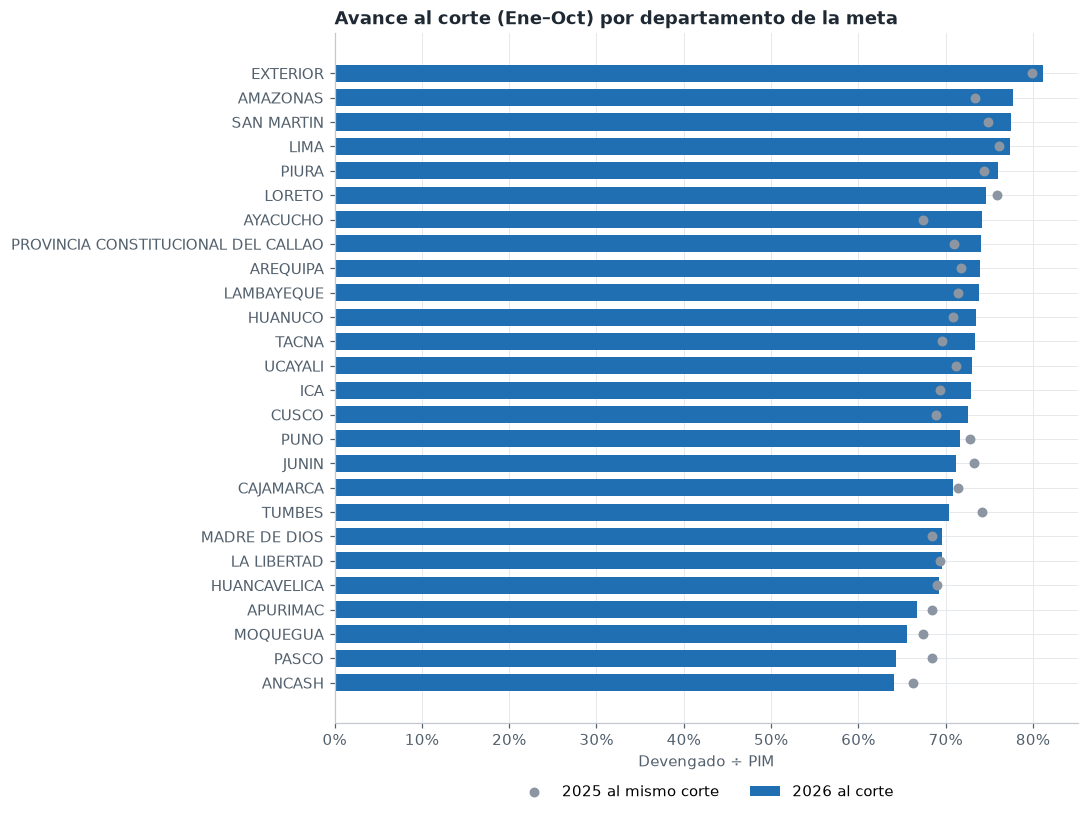

**Lectura automática:** el departamento con mayor avance al corte de 2026 es **Exterior** (81.1%) y el de menor avance **Ancash** (64.1%). Los puntos muestran el avance del año anterior al mismo mes.

In [34]:
# 6.5.e Territorio: avance al corte por departamento donde se ubica la meta del gasto.
dep = comparar("departamento_meta_nombre")
dep = dep[dep.index.astype(str) != ND_NOMBRE].sort_values(f"avance {a1} al corte")
fig, ax = plt.subplots(figsize=(10, 7.5))
y = np.arange(len(dep))
ax.barh(y, dep[f"avance {a1} al corte"], color=COLOR_ANIO[a1], height=0.7, label=f"{a1} al corte")
ax.scatter(dep[f"avance {a0} al corte"], y, color=COLOR_ANIO[a0], zorder=3, s=30, label=f"{a0} al mismo corte")
ax.set_yticks(y, dep.index.astype(str))
ax.xaxis.set_major_formatter(EJE_PCT)
ax.set(title=f"Avance al corte (Ene–{MES_ABREV[CORTE - 1]}) por departamento de la meta", xlabel="Devengado ÷ PIM")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=2)
plt.tight_layout()
guardar(fig, "avance_departamentos.png")
plt.show()
nota(f"**Lectura automática:** el departamento con mayor avance al corte de {a1} es **{str(dep.index[-1]).title()}** ({dep.iloc[-1][f'avance {a1} al corte']:.1%}) "
     f"y el de menor avance **{str(dep.index[0]).title()}** ({dep.iloc[0][f'avance {a1} al corte']:.1%}). Los puntos muestran el avance del año anterior al mismo mes.")

### 6.6 Exactitud: contraste con una cifra oficial publicada

El Congreso (Reporte Temático GPNNA, con datos del MEF al 12-01-2026) publicó para **2025**: PIM total de **S/ 272,405.4 millones** y gasto devengado de **S/ 254,696.1 millones**. Si el total de Gold está cerca, el pipeline no perdió ni duplicó montos. Una diferencia pequeña es esperable: el CSV se descargó meses después y el MEF sigue registrando ajustes del cierre.

In [35]:
REFERENCIA_2025 = {"monto_pim": 272_405.4e6, "monto_devengado": 254_696.1e6}   # MEF, 12-01-2026 (vía Congreso, RT GPNNA)
if MODO_MUESTRA:
    print("Modo muestra: el contraste con el total nacional no aplica.")
elif 2025 in ANIOS:
    k25 = resumen().loc[2025]
    exactitud = pd.DataFrame([{"indicador": c, "Gold (S/ M)": k25[c] / 1e6, "Referencia (S/ M)": v / 1e6,
                               "diferencia %": k25[c] / v - 1} for c, v in REFERENCIA_2025.items()])
    display(exactitud.style.format({"Gold (S/ M)": "{:,.1f}", "Referencia (S/ M)": "{:,.1f}", "diferencia %": "{:+.2%}"}))
    print("✓ Gold reproduce la cifra oficial (±1 %)" if exactitud["diferencia %"].abs().max() < 0.01
          else "⚠ Diferencia mayor a 1 %: revise filtros o la fecha de descarga")

,indicador,Gold (S/ M),Referencia (S/ M),diferencia %
0,monto_pim,"272,450.9","272,405.4",+0.02%
1,monto_devengado,"253,674.1","254,696.1",-0.40%


✓ Gold reproduce la cifra oficial (±1 %)


In [36]:
# Exportar a Gold las tablas del análisis integral (líneas 1 a 4) para el módulo 4 del dashboard.
ANALISIS_TABLAS = {"proyeccion_mensual": proyeccion_mensual, "proyeccion_metodos": proyeccion_metodos,
                   "clasificacion_entidades": clasificacion_entidades, "estacionalidad_mensual": estacionalidad_mensual,
                   "atipicos_entidades": atipicos_entidades.drop(columns=["nivel_gobierno"])}
clasificacion_entidades["entidad_key"] = clasificacion_entidades["entidad_key"].astype("int32")
for nombre, tabla in ANALISIS_TABLAS.items():
    guardar_parquet(tabla, GOLD / f"{nombre}.parquet", tipos_de(tabla))
    tabla.to_csv(OUTPUTS / f"{nombre}.csv", index=False, encoding="utf-8-sig")
    print(f"Gold → {(GOLD / (nombre + '.parquet')).relative_to(RAIZ).as_posix():<58} {len(tabla):>8,} filas")
GOLD_TABLAS.update(ANALISIS_TABLAS)
DESCRIPCION.update({
    "real_acumulado": "Devengado acumulado ÷ PIM (meses con datos)", "proy_a": "Proyección método A (estacional), acumulado ÷ PIM",
    "proy_b": "Proyección método B (tendencia lineal), acumulado ÷ PIM", "proy_c": "Proyección método C (regresión sobre el año base)",
    "lim_inf_c": "Límite inferior del intervalo al 95 % (método C)", "lim_sup_c": "Límite superior del intervalo al 95 % (método C)",
    "metodo_codigo": "A / B / C", "metodo": "Método de proyección", "devengado_proyectado": "Devengado anual proyectado (S/)",
    "avance_proyectado": "Devengado proyectado ÷ PIM (máx. 100 %)", "limite_inferior": "Límite inferior (intervalo o regla IQR)",
    "limite_superior": "Límite superior (intervalo o regla IQR)", "parametro": "Pendiente (B) o β (C) de la regresión",
    "error_prueba_base": "Error de la proyección al aplicarla al año base", "es_metodo_oficial": "Método usado en el POA y el dashboard",
    "dev_hasta_corte": "Devengado hasta el último mes con datos (S/)", "avance": "Devengado ÷ PIM", "avance_evaluado": "Avance usado para clasificar (anual o proyectado)",
    "clase": "Clase de ejecución (Muy alta … Muy baja)", "orden_clase": "Orden de la clase (1 = Muy alta)", "cuartil": "Cuartil del avance entre entidades relevantes",
    "pim_relevante": f"PIM ≥ S/ {PIM_MINIMO_RANKING / 1e6:.0f} M", "devengado": "Devengado del mes (S/)", "variacion_mensual": "Variación respecto del mes anterior",
    "indice_estacional": "Devengado del mes ÷ promedio mensual del año", "participacion": "Parte del devengado del año", "trimestre": "Trimestre",
    "variable": "Variable evaluada", "unidad": "Unidad de la variable", "valor": "Valor observado", "mediana_grupo": "Mediana del nivel de gobierno",
    "z_robusta": "Puntaje z robusto (mediana/MAD)", "tipo": "Alto o bajo frente a la mediana", "tecnica": "Técnica que lo detecta",
    "severidad": "Extremo (fuera de 3·IQR) o moderado",
})

Gold → data/gold/gasto_publico/proyeccion_mensual.parquet               12 filas
Gold → data/gold/gasto_publico/proyeccion_metodos.parquet                3 filas
Gold → data/gold/gasto_publico/clasificacion_entidades.parquet       5,756 filas
Gold → data/gold/gasto_publico/estacionalidad_mensual.parquet           22 filas
Gold → data/gold/gasto_publico/atipicos_entidades.parquet            1,024 filas


---
## 7. Presupuesto Público 2026: Ley N.º 32513

La **Ley N.º 32513, Ley de Presupuesto del Sector Público para el Año Fiscal 2026**, aprueba el presupuesto anual de gastos por **S/ 257 561 619 143** (artículo 1). Sus anexos oficiales distribuyen ese monto por:

| Anexo | Distribución |
|---|---|
| 1 | Categoría y genérica del gasto |
| 2 | Nivel de gobierno y genérica del gasto |
| 3 | Nivel de gobierno y funciones |
| 4 | Niveles de gobierno, pliegos y fuentes de financiamiento |
| 5 | Gobiernos regionales a nivel de productos, proyectos y actividades |
| 6 | Gobiernos locales y genéricas del gasto |

**Cómo se analiza aquí.** El crédito aprobado por la Ley es el **PIA 2026** de cada pliego. Por eso los anexos se reconstruyen con la columna `MONTO_PIA` del año 2026 del dataset del MEF, y primero se **contrasta** con las cifras oficiales publicadas: si cuadran, todas las distribuciones de esta sección (nivel de gobierno, función, pliego, genérica, fuente y programa presupuestal) son las de la Ley.

In [37]:
# 7.1 Contraste del PIA 2026 de Gold con las cifras oficiales de la Ley N.º 32513.
ANIO_LEY = 2026
LEY_TOTAL = 257_561_619_143.00   # Ley N.º 32513, art. 1
LEY_NIVEL = {"GOBIERNO NACIONAL": 162_305.2e6, "GOBIERNOS REGIONALES": 59_460.8e6, "GOBIERNOS LOCALES": 35_795.7e6}
# PIA 2026 por nivel de gobierno (MEF; Congreso, Reporte temático de seguimiento del gasto, junio 2026).
LEY_FUENTE_PCT = {"RECURSOS ORDINARIOS": 0.665, "RECURSOS DETERMINADOS": 0.174, "RECURSOS POR OPERACIONES OFICIALES DE CREDITO": 0.124,
                  "RECURSOS DIRECTAMENTE RECAUDADOS": 0.035, "DONACIONES Y TRANSFERENCIAS": 0.002}
# Participación por fuente del Proyecto de Ley 2026 (MEF, Guía de orientación al ciudadano).
PIA_ANTERIOR_OFICIAL = 251_801e6   # Presupuesto 2025 aprobado (MEF, alcances de la Ley 2026)

if ANIO_LEY not in ANIOS or MODO_MUESTRA:
    print("La Ley 2026 solo se contrasta con los datos completos del año 2026 (modo muestra: cifras ilustrativas).")
pia_ley = base[base["anio"] == ANIO_LEY]
pia_total = float(pia_ley["monto_pia"].sum())
filas = [{"concepto": "Total", "categoria": "Presupuesto del Sector Público 2026", "monto_oficial": LEY_TOTAL,
          "participacion_oficial": 1.0, "monto_gold": pia_total, "participacion_gold": 1.0,
          "referencia": "Ley N.º 32513, art. 1"}]
por_nivel = pia_ley.groupby("nivel_gobierno_nombre", observed=True)["monto_pia"].sum()
for nivel, oficial in LEY_NIVEL.items():
    filas.append({"concepto": "Nivel de gobierno", "categoria": nivel, "monto_oficial": oficial, "participacion_oficial": oficial / LEY_TOTAL,
                  "monto_gold": float(por_nivel.get(nivel, 0.0)), "participacion_gold": float(por_nivel.get(nivel, 0.0)) / pia_total,
                  "referencia": "MEF – PIA 2026 por nivel de gobierno"})
por_fuente = pia_ley.groupby("fuente_financiamiento_nombre", observed=True)["monto_pia"].sum()
for fuente, p in LEY_FUENTE_PCT.items():
    filas.append({"concepto": "Fuente de financiamiento", "categoria": fuente, "monto_oficial": np.nan, "participacion_oficial": p,
                  "monto_gold": float(por_fuente.get(fuente, 0.0)), "participacion_gold": float(por_fuente.get(fuente, 0.0)) / pia_total,
                  "referencia": "MEF – Proyecto de Ley 2026 (participación)"})
filas.append({"concepto": "Crecimiento", "categoria": "PIA 2026 frente al PIA 2025", "monto_oficial": LEY_TOTAL - PIA_ANTERIOR_OFICIAL,
              "participacion_oficial": LEY_TOTAL / PIA_ANTERIOR_OFICIAL - 1,
              "monto_gold": pia_total - float(base[base["anio"] == ANIO_LEY - 1]["monto_pia"].sum()),
              "participacion_gold": pia_total / float(base[base["anio"] == ANIO_LEY - 1]["monto_pia"].sum()) - 1,
              "referencia": "MEF – Presupuesto 2025 aprobado: S/ 251 801 M"})
ley_2026_cuadre = pd.DataFrame(filas)
ley_2026_cuadre["diferencia_pct"] = np.where(ley_2026_cuadre["monto_oficial"].notna() & (ley_2026_cuadre["concepto"] != "Crecimiento"),
                                             ley_2026_cuadre["monto_gold"] / ley_2026_cuadre["monto_oficial"] - 1, np.nan)
ley_2026_cuadre["orden"] = np.arange(1, len(ley_2026_cuadre) + 1)
display(ley_2026_cuadre.style.format({"monto_oficial": "S/ {:,.0f}", "monto_gold": "S/ {:,.0f}", "participacion_oficial": "{:.1%}",
                                      "participacion_gold": "{:.1%}", "diferencia_pct": "{:+.3%}"}, na_rep="—"))
dif_total = pia_total / LEY_TOTAL - 1
print(("✓" if abs(dif_total) < 0.001 else "⚠") + f" PIA 2026 de Gold vs Ley N.º 32513: diferencia {dif_total:+.4%}")
guardar_parquet(ley_2026_cuadre, GOLD / "ley_2026_cuadre.parquet", tipos_de(ley_2026_cuadre))
ley_2026_cuadre.to_csv(OUTPUTS / "ley_2026_cuadre.csv", index=False, encoding="utf-8-sig")
GOLD_TABLAS["ley_2026_cuadre"] = ley_2026_cuadre
DESCRIPCION.update({"concepto": "Tipo de contraste", "categoria": "Categoría contrastada", "monto_oficial": "Monto publicado (S/)",
                    "participacion_oficial": "Participación publicada", "monto_gold": "PIA 2026 calculado en Gold (S/)",
                    "participacion_gold": "Participación calculada en Gold", "referencia": "Documento oficial de referencia",
                    "diferencia_pct": "Gold ÷ oficial − 1"})

,concepto,categoria,monto_oficial,participacion_oficial,monto_gold,participacion_gold,referencia,diferencia_pct,orden
0,Total,Presupuesto del Sector Público 2026,"S/ 257,561,619,143",100.0%,"S/ 257,561,619,143",100.0%,"Ley N.º 32513, art. 1",+0.000%,1
1,Nivel de gobierno,GOBIERNO NACIONAL,"S/ 162,305,200,000",63.0%,"S/ 162,305,205,072",63.0%,MEF – PIA 2026 por nivel de gobierno,+0.000%,2
2,Nivel de gobierno,GOBIERNOS REGIONALES,"S/ 59,460,800,000",23.1%,"S/ 59,460,754,465",23.1%,MEF – PIA 2026 por nivel de gobierno,-0.000%,3
3,Nivel de gobierno,GOBIERNOS LOCALES,"S/ 35,795,700,000",13.9%,"S/ 35,795,659,606",13.9%,MEF – PIA 2026 por nivel de gobierno,-0.000%,4
4,Fuente de financiamiento,RECURSOS ORDINARIOS,—,66.5%,"S/ 171,239,540,211",66.5%,MEF – Proyecto de Ley 2026 (participación),—,5
5,Fuente de financiamiento,RECURSOS DETERMINADOS,—,17.4%,"S/ 44,855,886,524",17.4%,MEF – Proyecto de Ley 2026 (participación),—,6
6,Fuente de financiamiento,RECURSOS POR OPERACIONES OFICIALES DE CREDITO,—,12.4%,"S/ 31,902,777,237",12.4%,MEF – Proyecto de Ley 2026 (participación),—,7
7,Fuente de financiamiento,RECURSOS DIRECTAMENTE RECAUDADOS,—,3.5%,"S/ 9,042,023,112",3.5%,MEF – Proyecto de Ley 2026 (participación),—,8
8,Fuente de financiamiento,DONACIONES Y TRANSFERENCIAS,—,0.2%,"S/ 521,392,059",0.2%,MEF – Proyecto de Ley 2026 (participación),—,9
9,Crecimiento,PIA 2026 frente al PIA 2025,"S/ 5,760,619,143",2.3%,"S/ 5,760,573,958",2.3%,MEF – Presupuesto 2025 aprobado: S/ 251 801 M,—,10


✓ PIA 2026 de Gold vs Ley N.º 32513: diferencia +0.0000%


In [38]:
# 7.2 Distribución del presupuesto 2026 (anexos 1–4): nivel, fuente, genérica, categoría presupuestal, función y pliego.
def distribucion(por, n=None):
    t = (base[base["anio"].isin([ANIO_LEY - 1, ANIO_LEY])].groupby(["anio", por], observed=True)["monto_pia"].sum()
         .unstack("anio").fillna(0.0))
    out = pd.DataFrame({"PIA 2026": t[ANIO_LEY], "participación": t[ANIO_LEY] / t[ANIO_LEY].sum(),
                        "PIA 2025": t[ANIO_LEY - 1], "variación": (t[ANIO_LEY] / t[ANIO_LEY - 1] - 1).where(t[ANIO_LEY - 1] > 0)})
    out = out.sort_values("PIA 2026", ascending=False)
    return out.head(n) if n else out


LEY_DIST = {"Nivel de gobierno": distribucion("nivel_gobierno_nombre"),
            "Fuente de financiamiento": distribucion("fuente_financiamiento_nombre"),
            "Genérica de gasto": distribucion("generica_nombre"),
            "Tipo de categoría presupuestal": distribucion("tipo_programa"),
            "Función": distribucion("funcion_nombre"),
            "Pliego (15 mayores)": distribucion("pliego_nombre", TOP_N),
            "Programa presupuestal (15 mayores)": distribucion("programa_etiqueta", TOP_N)}
fmt_ley = {"PIA 2026": "S/ {:,.0f}", "PIA 2025": "S/ {:,.0f}", "participación": "{:.1%}", "variación": "{:+.1%}"}
for nombre in ["Función", "Pliego (15 mayores)", "Programa presupuestal (15 mayores)"]:
    display(Markdown(f"**{nombre}**"))
    display(LEY_DIST[nombre].style.format(fmt_ley, na_rep="—"))
for nombre, t in LEY_DIST.items():
    t.to_csv(OUTPUTS / f"ley_2026_{nombre.split(' (')[0].lower().replace(' ', '_')}.csv", encoding="utf-8-sig")

if TIENE_PLOTLY:
    paneles = ["Nivel de gobierno", "Fuente de financiamiento", "Genérica de gasto", "Tipo de categoría presupuestal"]
    fig = make_subplots(rows=2, cols=2, subplot_titles=paneles, horizontal_spacing=0.32, vertical_spacing=0.14)
    for k, nombre in enumerate(paneles):
        t = LEY_DIST[nombre].head(8).iloc[::-1]
        fig.add_bar(y=[str(i)[:36] for i in t.index], x=t["PIA 2026"] / 1e9, orientation="h", marker_color=AZUL, showlegend=False,
                    text=[f"{p:.1%}" for p in t["participación"]], textposition="outside",
                    hovertemplate="%{y}: S/ %{x:,.1f} mil millones<extra></extra>", row=k // 2 + 1, col=k % 2 + 1)
    fig.update_xaxes(title_text="S/ miles de millones")
    fig.update_layout(title="Ley N.º 32513: distribución del presupuesto 2026 (PIA)", height=720)
    mostrar(fig, "ley_2026_distribucion")

    fn = LEY_DIST["Función"].head(12).iloc[::-1]
    fig = go.Figure()
    fig.add_bar(y=fn.index.astype(str), x=fn["PIA 2025"] / 1e9, orientation="h", name="PIA 2025", marker_color=COLOR_ANIO.get(ANIO_LEY - 1, GRIS))
    fig.add_bar(y=fn.index.astype(str), x=fn["PIA 2026"] / 1e9, orientation="h", name="PIA 2026 (Ley N.º 32513)", marker_color=AZUL,
                text=[f"{v:+.1%}" for v in fn["variación"]], textposition="outside")
    fig.update_layout(title="PIA por función: Ley 2026 frente al presupuesto 2025 (12 funciones con mayor asignación)",
                      barmode="group", xaxis_title="S/ miles de millones", height=600)
    mostrar(fig, "ley_2026_funciones")

niv = LEY_DIST["Nivel de gobierno"]
fn = LEY_DIST["Función"]
fn_rel = fn[fn["participación"] >= 0.01]
tc = LEY_DIST["Tipo de categoría presupuestal"]
nota(f"""**Lectura automática**

- La Ley asigna **{s_millones(pia_total)}** (diferencia con el monto legal: {dif_total:+.3%}). Por nivel: Gobierno Nacional **{niv.loc['GOBIERNO NACIONAL', 'participación']:.1%}**, gobiernos regionales **{niv.loc['GOBIERNOS REGIONALES', 'participación']:.1%}** ({niv.loc['GOBIERNOS REGIONALES', 'variación']:+.1%} frente a 2025) y gobiernos locales **{niv.loc['GOBIERNOS LOCALES', 'participación']:.1%}**.
- La función con mayor asignación es **{str(fn.index[0]).title()}** ({fn.iloc[0]['participación']:.1%} del total). Entre las funciones con al menos 1 % del presupuesto, la que más crece es **{str(fn_rel['variación'].idxmax()).title()}** ({fn_rel['variación'].max():+.1%}) y la que más se reduce **{str(fn_rel['variación'].idxmin()).title()}** ({fn_rel['variación'].min():+.1%}).
- El **{tc.loc['PROGRAMA PRESUPUESTAL', 'participación'] if 'PROGRAMA PRESUPUESTAL' in tc.index else float('nan'):.1%}** del presupuesto se asigna mediante **programas presupuestales** (presupuesto por resultados); el resto financia acciones centrales y asignaciones que no resultan en productos (APNOP).""" if not MODO_MUESTRA else "Modo muestra: lectura omitida.")

**Función**

,PIA 2026,participación,PIA 2025,variación
funcion_nombre,,,,
EDUCACION,"S/ 48,707,652,461",18.9%,"S/ 48,411,631,966",+0.6%
SALUD,"S/ 32,887,683,068",12.8%,"S/ 30,656,541,754",+7.3%
DEUDA PUBLICA,"S/ 32,386,484,900",12.6%,"S/ 27,214,727,707",+19.0%
"PLANEAMIENTO, GESTION Y RESERVA DE CONTINGENCIA","S/ 30,080,131,333",11.7%,"S/ 32,017,271,071",-6.1%
TRANSPORTE,"S/ 22,325,009,055",8.7%,"S/ 23,169,590,402",-3.6%
PREVISION SOCIAL,"S/ 16,075,452,252",6.2%,"S/ 14,990,491,448",+7.2%
ORDEN PUBLICO Y SEGURIDAD,"S/ 15,857,565,131",6.2%,"S/ 16,356,697,262",-3.1%
PROTECCION SOCIAL,"S/ 10,688,747,267",4.1%,"S/ 10,420,788,873",+2.6%
JUSTICIA,"S/ 8,645,488,038",3.4%,"S/ 8,826,106,170",-2.0%


**Pliego (15 mayores)**

,PIA 2026,participación,PIA 2025,variación
pliego_nombre,,,,
M. DE ECONOMIA Y FINANZAS,"S/ 40,076,682,947",15.6%,"S/ 36,436,785,807",+10.0%
GOBIERNOS LOCALES,"S/ 35,795,659,606",13.9%,"S/ 35,323,230,357",+1.3%
M. DEL INTERIOR,"S/ 13,397,947,493",5.2%,"S/ 12,893,682,003",+3.9%
M. DE SALUD,"S/ 11,396,612,777",4.4%,"S/ 11,049,259,363",+3.1%
MINISTERIO DE TRANSPORTES Y COMUNICACIONES,"S/ 10,726,702,690",4.2%,"S/ 12,027,420,715",-10.8%
M. DE EDUCACION,"S/ 9,877,797,480",3.8%,"S/ 13,225,912,066",-25.3%
M. DE DEFENSA,"S/ 9,634,203,776",3.7%,"S/ 8,855,566,395",+8.8%
OFICINA DE NORMALIZACION PREVISIONAL-ONP,"S/ 9,553,937,477",3.7%,"S/ 9,280,712,218",+2.9%
MINISTERIO DE DESARROLLO E INCLUSION SOCIAL,"S/ 7,505,624,076",2.9%,"S/ 7,308,758,239",+2.7%


**Programa presupuestal (15 mayores)**

,PIA 2026,participación,PIA 2025,variación
programa_etiqueta,,,,
9002 ASIGNACIONES PRESUPUESTARIAS QUE NO RESULTAN EN PRODUCTOS,"S/ 110,052,169,138",42.7%,"S/ 109,424,336,055",+0.6%
9001 ACCIONES CENTRALES,"S/ 33,824,611,663",13.1%,"S/ 31,852,673,613",+6.2%
0090 LOGROS DE APRENDIZAJE DE ESTUDIANTES DE LA EDUCACION BASICA REGULAR,"S/ 27,891,310,370",10.8%,"S/ 24,383,268,731",+14.4%
"0138 REDUCCION DEL COSTO, TIEMPO E INSEGURIDAD EN EL SISTEMA DE TRANSPORTE","S/ 12,798,550,698",5.0%,"S/ 14,889,440,343",-14.0%
0135 MEJORA DE LAS CAPACIDADES MILITARES PARA LA DEFENSA Y EL DESARROLLO NACIONAL,"S/ 7,207,181,471",2.8%,"S/ 6,438,348,254",+11.9%
0030 REDUCCION DE DELITOS Y FALTAS QUE AFECTAN LA SEGURIDAD CIUDADANA,"S/ 6,877,664,165",2.7%,"S/ 5,388,417,747",+27.6%
"0148 REDUCCION DEL TIEMPO, INSEGURIDAD Y COSTO AMBIENTAL EN EL TRANSPORTE URBANO","S/ 4,744,625,559",1.8%,"S/ 3,450,592,778",+37.5%
0066 FORMACION UNIVERSITARIA DE PREGRADO,"S/ 3,965,850,379",1.5%,"S/ 4,318,708,289",-8.2%
1001 PRODUCTOS ESPECIFICOS PARA DESARROLLO INFANTIL TEMPRANO,"S/ 3,625,840,461",1.4%,"S/ 3,686,692,266",-1.7%


**Lectura automática**

- La Ley asigna **S/ 257,561.6 M** (diferencia con el monto legal: +0.000%). Por nivel: Gobierno Nacional **63.0%**, gobiernos regionales **23.1%** (+9.2% frente a 2025) y gobiernos locales **13.9%**.
- La función con mayor asignación es **Educacion** (18.9% del total). Entre las funciones con al menos 1 % del presupuesto, la que más crece es **Cultura Y Deporte** (+22.7%) y la que más se reduce **Agropecuaria** (-12.8%).
- El **44.1%** del presupuesto se asigna mediante **programas presupuestales** (presupuesto por resultados); el resto financia acciones centrales y asignaciones que no resultan en productos (APNOP).

---
## 8. Planeamiento operativo anual: objetivos, indicadores, líneas base, metas y acciones

El EDA describe **qué pasó**. Esta sección convierte ese diagnóstico en **instrumentos de planeamiento**: indicadores con ficha técnica, una línea base, una proyección del año en curso y **metas** para el año siguiente.

En el sector público peruano, el planeamiento operativo anual se concreta en el **Plan Operativo Institucional (POI)**, elaborado con la *Guía para el Planeamiento Institucional* del CEPLAN. El POI tiene una **ficha técnica por indicador** (Anexo B-3) y una **programación física y financiera mensual** (Anexo B-5). Este proyecto produce el equivalente para el **gasto agregado del Estado**:

| Paso | Qué se obtiene | Para qué sirve en el POA |
|---|---|---|
| 8.1 Fichas técnicas | 9 indicadores con fórmula, unidad, sentido y frecuencia | Definir qué se mide y cómo |
| 8.1.b Objetivos y acciones | 4 **objetivos operativos** y una **acción de mejora** con responsable por indicador | Vincular cada meta con lo que hay que hacer |
| 8.2 Línea base | Valor de cada indicador en **2025** (año cerrado) | Punto de partida de las metas |
| 8.3 Seguimiento y proyección | Valor de **2026 al corte** y **proyección de cierre 2026** | Saber si el año en curso llegará a su meta |
| 8.4 Metas | **Meta 2026** (no retroceder) y **meta POA 2027** (mejora gradual con tope) | Compromisos medibles para el siguiente año |
| 8.5 Programación mensual 2027 | Curva de avance acumulado que **reduce la concentración de diciembre** | Calendario de ejecución (equivalente a la programación financiera mensual) |
| 8.6 Metas por sector | Línea base, proyección y meta 2027 por sector, con prioridad | Bajar la meta nacional a quienes la ejecutan |

**Reglas de las metas (transparentes y reproducibles):**

- **Meta 2026 = línea base 2025.** El año en curso no debería terminar peor que el anterior.
- **Meta POA 2027 = línea base + mejora**, con un **tope realista** (si "mayor es mejor") o un **piso** (si "menor es mejor"). Las mejoras están en `INDICADORES` y se pueden ajustar.
- **Semáforo:** *Cumple* si la proyección alcanza la meta; *En riesgo* si queda a menos de `TOLERANCIA_PP` puntos; *No cumple* en otro caso.

In [39]:
# 8.1 Fichas técnicas de los indicadores. Cada fila es un compromiso medible del POA.
ANIO_BASE, ANIO_SEG = ANIOS[0], ANIOS[-1]     # 2025 = línea base (año cerrado) · 2026 = año en seguimiento
ANIO_POA = ANIO_SEG + 1                        # 2027 = año que se planifica
TOLERANCIA_PP = 0.02                           # 2 puntos porcentuales: zona "en riesgo" del semáforo
UMBRAL_UE_ALTA = 0.90                          # una unidad ejecutora tiene "alta ejecución" si avanza ≥ 90 %

# sentido: +1 = mayor es mejor · -1 = menor es mejor ; mejora en puntos (fracción) ; limite = tope o piso
INDICADORES = pd.DataFrame([
    ("IND01", "Avance de ejecución presupuestal", "Medir la capacidad de gasto frente al presupuesto modificado",
     "Devengado ÷ PIM", +1, "Mensual", 0.02, 0.98),
    ("IND02", "Certificación del PIM", "Medir cuánto del presupuesto ya tiene un gasto previsto y reservado",
     "Certificado ÷ PIM", +1, "Mensual", 0.01, 0.99),
    ("IND03", "Ejecución de inversiones", "Medir el avance de los proyectos de inversión",
     "Devengado de proyectos ÷ PIM de proyectos", +1, "Mensual", 0.05, 0.95),
    ("IND04", "Concentración del gasto en diciembre", "Detectar la postergación del gasto al cierre del año",
     "Devengado de diciembre ÷ Devengado anual", -1, "Anual", 0.02, 1 / 12),
    ("IND05", "Avance al primer semestre", "Verificar el ritmo de ejecución a mitad de año",
     "Devengado enero–junio ÷ PIM", +1, "Semestral", 0.03, 0.60),
    ("IND06", "Eficacia de pago", "Medir qué parte de lo devengado ya se pagó",
     "Girado ÷ Devengado", +1, "Mensual", 0.001, 1.00),
    ("IND07", "Modificación presupuestal", "Medir la calidad de la programación inicial (PIA)",
     "(PIM − PIA) ÷ PIA", -1, "Anual", 0.02, 0.0),
    ("IND08", "Unidades ejecutoras con alta ejecución", f"Medir cuántas UE logran un avance ≥ {UMBRAL_UE_ALTA:.0%}",
     f"N.° UE con avance ≥ {UMBRAL_UE_ALTA:.0%} ÷ N.° UE con PIM ≥ S/ {PIM_MINIMO_RANKING / 1e6:.0f} M", +1, "Anual", 0.05, 1.00),
    ("IND09", "Tasa de extornos", "Medir la calidad del registro del gasto (anulaciones)",
     "− Extornos ÷ Devengado", -1, "Mensual", 0.001, 0.0),
], columns=["codigo", "indicador", "objetivo", "formula", "sentido", "frecuencia", "mejora", "limite"])
INDICADORES["unidad"] = "%"
INDICADORES["fuente"] = "MEF – Consulta Amigable (datos abiertos) · capa Gold"
INDICADORES["sentido_texto"] = np.where(INDICADORES["sentido"] > 0, "Mayor es mejor", "Menor es mejor")
INDICADORES[["codigo", "indicador", "objetivo", "formula", "unidad", "sentido_texto", "frecuencia", "fuente"]]

,codigo,indicador,objetivo,formula,unidad,sentido_texto,frecuencia,fuente
0,IND01,Avance de ejecución presupuestal,Medir la capacidad de gasto frente al presupue...,Devengado ÷ PIM,%,Mayor es mejor,Mensual,MEF – Consulta Amigable (datos abiertos) · cap...
1,IND02,Certificación del PIM,Medir cuánto del presupuesto ya tiene un gasto...,Certificado ÷ PIM,%,Mayor es mejor,Mensual,MEF – Consulta Amigable (datos abiertos) · cap...
2,IND03,Ejecución de inversiones,Medir el avance de los proyectos de inversión,Devengado de proyectos ÷ PIM de proyectos,%,Mayor es mejor,Mensual,MEF – Consulta Amigable (datos abiertos) · cap...
3,IND04,Concentración del gasto en diciembre,Detectar la postergación del gasto al cierre d...,Devengado de diciembre ÷ Devengado anual,%,Menor es mejor,Anual,MEF – Consulta Amigable (datos abiertos) · cap...
4,IND05,Avance al primer semestre,Verificar el ritmo de ejecución a mitad de año,Devengado enero–junio ÷ PIM,%,Mayor es mejor,Semestral,MEF – Consulta Amigable (datos abiertos) · cap...
5,IND06,Eficacia de pago,Medir qué parte de lo devengado ya se pagó,Girado ÷ Devengado,%,Mayor es mejor,Mensual,MEF – Consulta Amigable (datos abiertos) · cap...
6,IND07,Modificación presupuestal,Medir la calidad de la programación inicial (PIA),(PIM − PIA) ÷ PIA,%,Menor es mejor,Anual,MEF – Consulta Amigable (datos abiertos) · cap...
7,IND08,Unidades ejecutoras con alta ejecución,Medir cuántas UE logran un avance ≥ 90%,N.° UE con avance ≥ 90% ÷ N.° UE con PIM ≥ S/ 5 M,%,Mayor es mejor,Anual,MEF – Consulta Amigable (datos abiertos) · cap...
8,IND09,Tasa de extornos,Medir la calidad del registro del gasto (anula...,− Extornos ÷ Devengado,%,Menor es mejor,Mensual,MEF – Consulta Amigable (datos abiertos) · cap...


In [40]:
# 8.1.b Objetivos operativos y acciones de mejora: cada indicador sirve a un objetivo y tiene una acción concreta.
OBJETIVOS_OPERATIVOS = pd.DataFrame([
    ("OO1", "Mejorar la capacidad de ejecución del gasto público", "Más presupuesto convertido en bienes, servicios y obras"),
    ("OO2", "Mejorar la calidad de la programación presupuestal", "Un PIA más realista y el gasto previsto desde el inicio del año"),
    ("OO3", "Ejecutar el gasto de forma oportuna durante el año", "Menos concentración del gasto en el último mes"),
    ("OO4", "Fortalecer la gestión de pagos y la calidad del registro", "Obligaciones pagadas a tiempo y registros sin anulaciones"),
], columns=["objetivo_codigo", "objetivo_operativo", "resultado_esperado"])

ACCIONES_MEJORA = {   # indicador: (objetivo, acción de mejora, responsable)
    "IND01": ("OO1", "Programar un calendario mensual de compromisos por unidad ejecutora, revisar el avance cada mes y reasignar en el "
                     "tercer trimestre los saldos que no tengan certificación.", "Oficina de Planeamiento y Presupuesto (OPP)"),
    "IND02": ("OO2", "Certificar en enero el gasto recurrente (planillas, servicios, contratos vigentes) y depurar cada trimestre las "
                     "certificaciones que no llegaron a compromiso.", "OPP y Oficina de Logística"),
    "IND03": ("OO1", "Priorizar proyectos con expediente técnico aprobado, programar valorizaciones mensuales y alertar a los proyectos "
                     "con avance menor a 50 % al cierre del tercer trimestre.", "Oficina de Programación Multianual de Inversiones (OPMI)"),
    "IND04": ("OO3", "Adelantar al primer semestre los procesos del Plan Anual de Contrataciones y limitar los devengados de diciembre a "
                     "obligaciones ya comprometidas.", "Oficina de Logística y OPP"),
    "IND05": ("OO3", "Fijar hitos semestrales de devengado por unidad ejecutora y evaluarlos en el seguimiento del POI del primer semestre.",
              "OPP"),
    "IND06": ("OO4", "Girar dentro de los cinco días hábiles siguientes al devengado y conciliar cada mes con el Tesoro Público.",
              "Oficina de Tesorería"),
    "IND07": ("OO2", "Formular el PIA con la ejecución histórica y la programación multianual; sustentar las modificaciones mayores a 10 %.",
              "OPP"),
    "IND08": ("OO1", "Asistencia técnica a las unidades ejecutoras clasificadas con ejecución baja o muy baja (sección 6.2) con metas "
                     "trimestrales de avance.", "OPP del pliego y Dirección General de Presupuesto Público (MEF)"),
    "IND09": ("OO4", "Capacitar en el registro del SIAF y revisar cada mes los extornos recurrentes por unidad ejecutora.",
              "Oficinas de Contabilidad y Tesorería"),
}
INDICADORES["objetivo_codigo"] = INDICADORES["codigo"].map(lambda c: ACCIONES_MEJORA[c][0])
INDICADORES["accion_mejora"] = INDICADORES["codigo"].map(lambda c: ACCIONES_MEJORA[c][1])
INDICADORES["responsable"] = INDICADORES["codigo"].map(lambda c: ACCIONES_MEJORA[c][2])
INDICADORES = INDICADORES.merge(OBJETIVOS_OPERATIVOS, on="objetivo_codigo", how="left")
display(OBJETIVOS_OPERATIVOS.merge(INDICADORES.groupby("objetivo_codigo")["codigo"].agg(", ".join).rename("indicadores"),
                                   on="objetivo_codigo"))
INDICADORES[["objetivo_codigo", "codigo", "indicador", "accion_mejora", "responsable"]]

,objetivo_codigo,objetivo_operativo,resultado_esperado,indicadores
0,OO1,Mejorar la capacidad de ejecución del gasto pú...,"Más presupuesto convertido en bienes, servicio...","IND01, IND03, IND08"
1,OO2,Mejorar la calidad de la programación presupue...,Un PIA más realista y el gasto previsto desde ...,"IND02, IND07"
2,OO3,Ejecutar el gasto de forma oportuna durante el...,Menos concentración del gasto en el último mes,"IND04, IND05"
3,OO4,Fortalecer la gestión de pagos y la calidad de...,Obligaciones pagadas a tiempo y registros sin ...,"IND06, IND09"


,objetivo_codigo,codigo,indicador,accion_mejora,responsable
0,OO1,IND01,Avance de ejecución presupuestal,Programar un calendario mensual de compromisos...,Oficina de Planeamiento y Presupuesto (OPP)
1,OO2,IND02,Certificación del PIM,Certificar en enero el gasto recurrente (plani...,OPP y Oficina de Logística
2,OO1,IND03,Ejecución de inversiones,Priorizar proyectos con expediente técnico apr...,Oficina de Programación Multianual de Inversio...
3,OO3,IND04,Concentración del gasto en diciembre,Adelantar al primer semestre los procesos del ...,Oficina de Logística y OPP
4,OO3,IND05,Avance al primer semestre,Fijar hitos semestrales de devengado por unida...,OPP
5,OO4,IND06,Eficacia de pago,Girar dentro de los cinco días hábiles siguien...,Oficina de Tesorería
6,OO2,IND07,Modificación presupuestal,Formular el PIA con la ejecución histórica y l...,OPP
7,OO1,IND08,Unidades ejecutoras con alta ejecución,Asistencia técnica a las unidades ejecutoras c...,OPP del pliego y Dirección General de Presupue...
8,OO4,IND09,Tasa de extornos,Capacitar en el registro del SIAF y revisar ca...,Oficinas de Contabilidad y Tesorería


In [41]:
# 8.2–8.3 Línea base, valor al corte y proyección de cierre. Todo sale de las tablas Gold.
fm = fact_gasto_mensual.assign(mes=fact_gasto_mensual["fecha"].dt.month)
fa = fact_presupuesto_anual
k_proy = DIM["dim_tipo_intervencion"].loc[
    DIM["dim_tipo_intervencion"]["tipo_act_proy"].str.upper().str.startswith("PROY"), "tipo_intervencion_key"].tolist()


def anual(anio, col, filtro=None):
    t = fa[fa["anio"] == anio]
    return float((t[filtro(t)] if filtro else t)[col].sum())


def devengado(anio, meses, filtro=None, col="monto_devengado"):
    t = fm[(fm["anio"] == anio) & fm["mes"].isin(list(meses))]
    return float((t[filtro(t)] if filtro else t)[col].sum())


def es_proyecto(t):
    return t["tipo_intervencion_key"].isin(k_proy)


MESES_CORTE, TODOS = range(1, CORTE + 1), range(1, 13)
ULTIMO_SEG = int(dim_anio.set_index("anio").loc[ANIO_SEG, "mes_ultimo_dato"])
MESES_SEG = range(1, ULTIMO_SEG + 1)

# Factor estacional de la línea base: qué parte del devengado anual ya se había ejecutado al mes de corte.
cuota_corte = devengado(ANIO_BASE, MESES_CORTE) / devengado(ANIO_BASE, TODOS)
cuota_corte_proy = devengado(ANIO_BASE, MESES_CORTE, es_proyecto) / devengado(ANIO_BASE, TODOS, es_proyecto)
dev_proyectado = devengado(ANIO_SEG, MESES_SEG) / (devengado(ANIO_BASE, MESES_SEG) / devengado(ANIO_BASE, TODOS))
dev_proyectado_proy = (devengado(ANIO_SEG, MESES_SEG, es_proyecto)
                       / (devengado(ANIO_BASE, MESES_SEG, es_proyecto) / devengado(ANIO_BASE, TODOS, es_proyecto)))


def ue_alta(anio, proyectar=False):
    """% de unidades ejecutoras (PIM ≥ mínimo) con avance ≥ umbral; en el año en curso, con su devengado proyectado."""
    pim = fa[fa["anio"] == anio].groupby("entidad_key")["monto_pim"].sum()
    if proyectar:
        actual = fm[(fm["anio"] == anio) & fm["mes"].isin(list(MESES_SEG))].groupby("entidad_key")["monto_devengado"].sum()
        base_parcial = fm[(fm["anio"] == ANIO_BASE) & fm["mes"].isin(list(MESES_SEG))].groupby("entidad_key")["monto_devengado"].sum()
        base_total = fm[fm["anio"] == ANIO_BASE].groupby("entidad_key")["monto_devengado"].sum()
        cuota_ue = (base_parcial / base_total).where(base_total > 0).clip(0.3, 1.0)
        cuota_nac = devengado(ANIO_BASE, MESES_SEG) / devengado(ANIO_BASE, TODOS)
        dev = actual / cuota_ue.reindex(actual.index).fillna(cuota_nac)
    else:
        dev = fa[fa["anio"] == anio].groupby("entidad_key")["monto_devengado"].sum()
    t = pd.DataFrame({"pim": pim, "dev": dev}).fillna(0)
    t = t[t["pim"] >= PIM_MINIMO_RANKING]
    return float((t["dev"] / t["pim"] >= UMBRAL_UE_ALTA).mean())


pim_b, pim_s = anual(ANIO_BASE, "monto_pim"), anual(ANIO_SEG, "monto_pim")
pim_proy_b = anual(ANIO_BASE, "monto_pim", es_proyecto)
pim_proy_s = anual(ANIO_SEG, "monto_pim", es_proyecto)
dic_b = devengado(ANIO_BASE, [12]) / devengado(ANIO_BASE, TODOS)
# Diciembre proyectado: lo que falta del año se reparte como en la línea base (noviembre vs diciembre).
falta = max(dev_proyectado - devengado(ANIO_SEG, MESES_SEG), 0)
peso_dic = devengado(ANIO_BASE, [12]) / max(devengado(ANIO_BASE, range(ULTIMO_SEG + 1, 13)), 1)
dic_proy = (falta * peso_dic) / dev_proyectado if ULTIMO_SEG < 12 else devengado(ANIO_SEG, [12]) / dev_proyectado

valores = {
    "IND01": (anual(ANIO_BASE, "monto_devengado") / pim_b, devengado(ANIO_SEG, MESES_SEG) / pim_s, dev_proyectado / pim_s),
    "IND02": (anual(ANIO_BASE, "monto_certificado") / pim_b, anual(ANIO_SEG, "monto_certificado") / pim_s,
              anual(ANIO_SEG, "monto_certificado") / pim_s),
    "IND03": (anual(ANIO_BASE, "monto_devengado", es_proyecto) / pim_proy_b,
              devengado(ANIO_SEG, MESES_SEG, es_proyecto) / pim_proy_s, dev_proyectado_proy / pim_proy_s),
    "IND04": (dic_b, np.nan, dic_proy),
    "IND05": (devengado(ANIO_BASE, range(1, 7)) / pim_b, devengado(ANIO_SEG, range(1, 7)) / pim_s,
              devengado(ANIO_SEG, range(1, 7)) / pim_s),
    "IND06": (anual(ANIO_BASE, "monto_girado") / anual(ANIO_BASE, "monto_devengado"),
              anual(ANIO_SEG, "monto_girado") / anual(ANIO_SEG, "monto_devengado"),
              anual(ANIO_SEG, "monto_girado") / anual(ANIO_SEG, "monto_devengado")),
    "IND07": (pim_b / anual(ANIO_BASE, "monto_pia") - 1, pim_s / anual(ANIO_SEG, "monto_pia") - 1,
              pim_s / anual(ANIO_SEG, "monto_pia") - 1),
    "IND08": (ue_alta(ANIO_BASE), np.nan, ue_alta(ANIO_SEG, proyectar=True)),
    "IND09": (-devengado(ANIO_BASE, TODOS, col="monto_extorno") / devengado(ANIO_BASE, TODOS),
              -devengado(ANIO_SEG, MESES_SEG, col="monto_extorno") / devengado(ANIO_SEG, MESES_SEG),
              -devengado(ANIO_SEG, MESES_SEG, col="monto_extorno") / devengado(ANIO_SEG, MESES_SEG)),
}
ind = INDICADORES.copy()
ind[["linea_base", "valor_al_corte", "proyeccion_cierre"]] = [list(valores[c]) for c in ind["codigo"]]
# Un avance proyectado no puede superar el 100 % del presupuesto.
ind.loc[ind["codigo"].isin(["IND01", "IND03"]), "proyeccion_cierre"] = ind["proyeccion_cierre"].clip(upper=1.0)
nota(f"""**Método de proyección (8.3).** El devengado de {ANIO_SEG} hasta {MESES[ULTIMO_SEG - 1].lower()} se divide entre la parte del año que,
en {ANIO_BASE}, ya estaba ejecutada a ese mes ({devengado(ANIO_BASE, MESES_SEG) / devengado(ANIO_BASE, TODOS):.1%}). Es un método **estacional ingenuo**:
supone que {ANIO_SEG} repetirá el calendario de gasto de {ANIO_BASE}, y se acota al 100 % del PIM. Proyección de devengado {ANIO_SEG}: **{s_millones(dev_proyectado)}**.""")

**Método de proyección (8.3).** El devengado de 2026 hasta octubre se divide entre la parte del año que,
en 2025, ya estaba ejecutada a ese mes (78.6%). Es un método **estacional ingenuo**:
supone que 2026 repetirá el calendario de gasto de 2025, y se acota al 100 % del PIM. Proyección de devengado 2026: **S/ 275,115.5 M**.

In [42]:
# 8.4 Metas: 2026 = no retroceder frente a la línea base; POA 2027 = línea base + mejora, con tope o piso.
def meta_poa(fila):
    # Nunca por debajo de la línea base: si ya se superó el tope, la meta es mantener lo logrado.
    if fila["sentido"] > 0:
        return max(fila["linea_base"], min(fila["limite"], fila["linea_base"] + fila["mejora"]))
    return min(fila["linea_base"], max(fila["limite"], fila["linea_base"] - fila["mejora"]))


def estado(fila):
    if pd.isna(fila["proyeccion_cierre"]):
        return "Sin dato"
    brecha = round((fila["proyeccion_cierre"] - fila["meta_anio_seg"]) * fila["sentido"], 6)
    return "Cumple" if brecha >= 0 else ("En riesgo" if brecha >= -TOLERANCIA_PP else "No cumple")


ind["meta_anio_seg"] = ind["linea_base"]
ind["meta_poa"] = ind.apply(meta_poa, axis=1)

# 8.5 Programación mensual del POA: perfil de gasto de la línea base con un diciembre menos concentrado.
dev_mes_base = fm[fm["anio"] == ANIO_BASE].groupby("mes")["monto_devengado"].sum().reindex(TODOS, fill_value=0)
perfil_base = dev_mes_base / dev_mes_base.sum()
dic_meta = float(ind.set_index("codigo").loc["IND04", "meta_poa"])
perfil_poa = perfil_base.copy()
perfil_poa.iloc[:11] = perfil_base.iloc[:11] * (1 - dic_meta) / perfil_base.iloc[:11].sum()
perfil_poa.iloc[11] = dic_meta
meta_avance_poa = float(ind.set_index("codigo").loc["IND01", "meta_poa"])
curva_poa = perfil_poa.cumsum() * meta_avance_poa
# La meta del primer semestre se deriva de la curva: así las metas son coherentes entre sí.
ind.loc[ind["codigo"] == "IND05", "meta_poa"] = float(curva_poa.loc[6])

ind["brecha_proyeccion_pp"] = (ind["proyeccion_cierre"] - ind["meta_anio_seg"]) * ind["sentido"]
ind["estado"] = ind.apply(estado, axis=1)
COLOR_ESTADO = {"Cumple": ESTADO["bueno"], "En riesgo": ESTADO["alerta"], "No cumple": ESTADO["critico"], "Sin dato": GRIS}
ind["color_estado"] = ind["estado"].map(COLOR_ESTADO)
ind["orden"] = np.arange(1, len(ind) + 1)

tabla_metas = ind[["codigo", "indicador", "sentido_texto", "linea_base", "valor_al_corte", "proyeccion_cierre",
                   "meta_anio_seg", "estado", "meta_poa"]].rename(columns={
    "sentido_texto": "sentido", "linea_base": f"línea base {ANIO_BASE}", "valor_al_corte": f"{ANIO_SEG} al corte",
    "proyeccion_cierre": f"proyección {ANIO_SEG}", "meta_anio_seg": f"meta {ANIO_SEG}", "estado": f"estado {ANIO_SEG}",
    "meta_poa": f"meta POA {ANIO_POA}"})
pcts = [c for c in tabla_metas.columns if c[:1].isdigit() or c.startswith(("línea", "proy", "meta"))]
display(tabla_metas.style.format({c: "{:.1%}" for c in pcts}, na_rep="—")
        .map(lambda v: f"color: {COLOR_ESTADO.get(v, TINTA)}; font-weight: bold" if v in COLOR_ESTADO else "",
             subset=[f"estado {ANIO_SEG}"]))
conteo = ind["estado"].value_counts()
nota(f"**Lectura automática:** semáforo {ANIO_SEG} de los {len(ind)} indicadores según la proyección de cierre — "
     f"Cumple: **{conteo.get('Cumple', 0)}** · En riesgo: **{conteo.get('En riesgo', 0)}** · No cumple: **{conteo.get('No cumple', 0)}**. "
     f"La meta POA {ANIO_POA} de avance es **{meta_avance_poa:.1%}** con un diciembre que no supere el **{dic_meta:.1%}** del gasto anual.")

,codigo,indicador,sentido,línea base 2025,2026 al corte,proyección 2026,meta 2026,estado 2026,meta POA 2027
0,IND01,Avance de ejecución presupuestal,Mayor es mejor,93.1%,74.3%,94.5%,93.1%,Cumple,95.1%
1,IND02,Certificación del PIM,Mayor es mejor,96.6%,93.0%,93.0%,96.6%,No cumple,97.6%
2,IND03,Ejecución de inversiones,Mayor es mejor,84.3%,65.0%,88.1%,84.3%,Cumple,89.3%
3,IND04,Concentración del gasto en diciembre,Menor es mejor,13.6%,—,13.6%,13.6%,Cumple,11.6%
4,IND05,Avance al primer semestre,Mayor es mejor,41.7%,42.8%,42.8%,41.7%,Cumple,43.5%
5,IND06,Eficacia de pago,Mayor es mejor,99.8%,98.4%,98.4%,99.8%,En riesgo,99.9%
6,IND07,Modificación presupuestal,Menor es mejor,8.2%,13.0%,13.0%,8.2%,No cumple,6.2%
7,IND08,Unidades ejecutoras con alta ejecución,Mayor es mejor,49.4%,—,53.3%,49.4%,Cumple,54.4%
8,IND09,Tasa de extornos,Menor es mejor,0.7%,0.4%,0.4%,0.7%,Cumple,0.6%


**Lectura automática:** semáforo 2026 de los 9 indicadores según la proyección de cierre — Cumple: **6** · En riesgo: **1** · No cumple: **2**. La meta POA 2027 de avance es **95.1%** con un diciembre que no supere el **11.6%** del gasto anual.

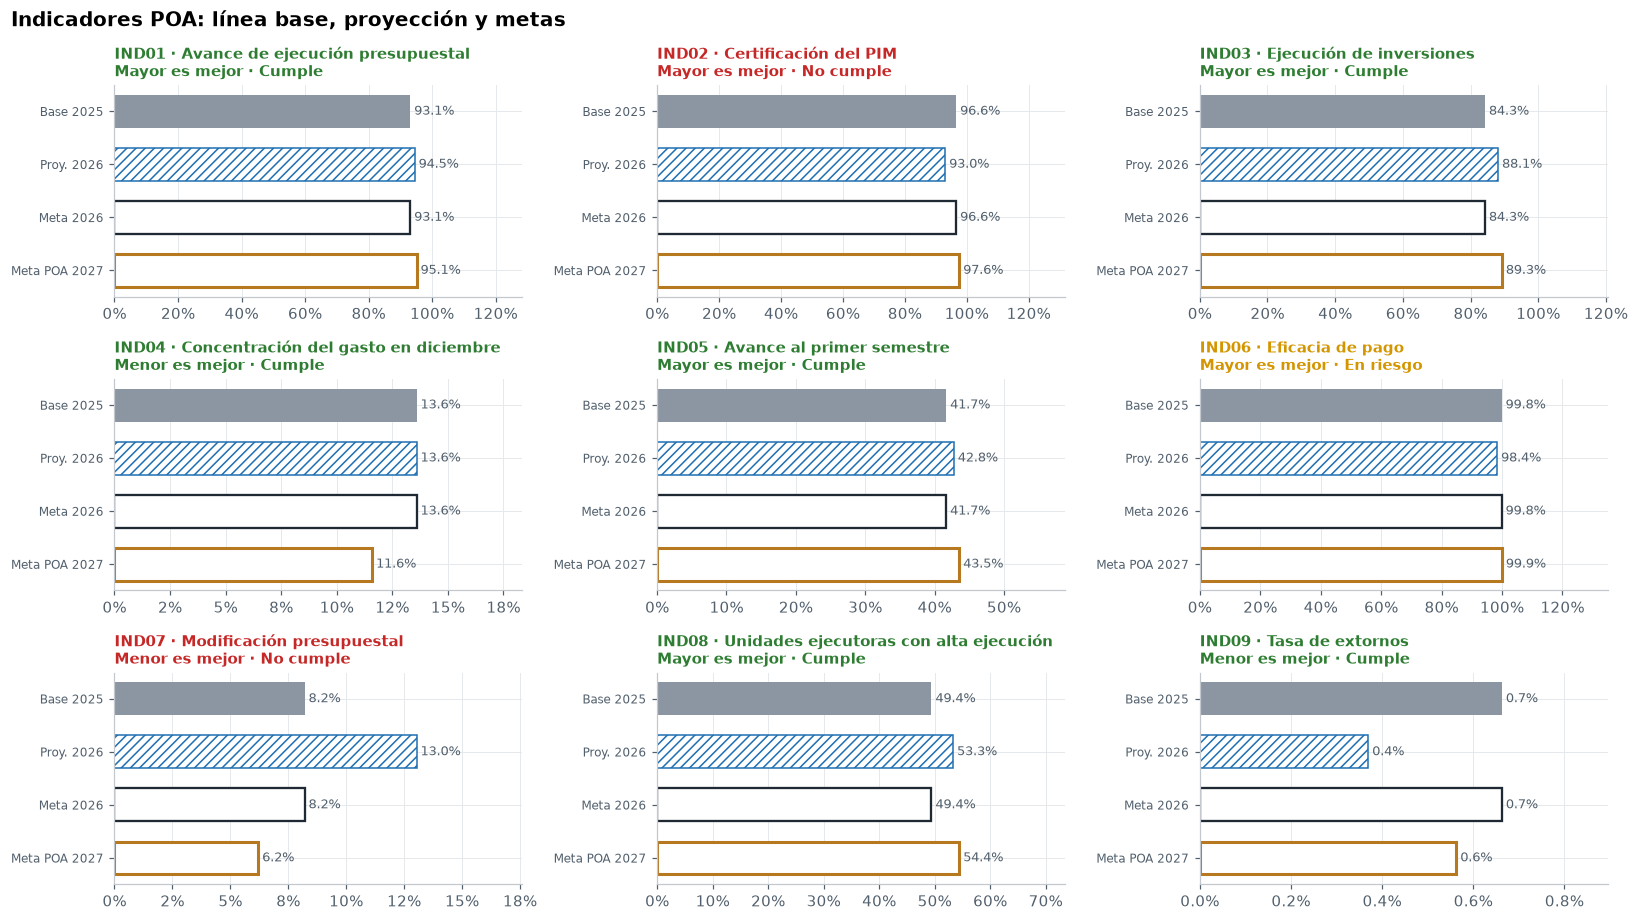

In [43]:
# Indicadores frente a su meta (notación IBCS: real = sólido, meta = contorno, proyección = rayado).
fig, axes = plt.subplots(3, 3, figsize=(15, 8.5))
for ax, (_, f) in zip(axes.ravel(), ind.iterrows()):
    etiquetas = [f"Base {ANIO_BASE}", f"Proy. {ANIO_SEG}", f"Meta {ANIO_SEG}", f"Meta POA {ANIO_POA}"]
    vals = [f["linea_base"], f["proyeccion_cierre"], f["meta_anio_seg"], f["meta_poa"]]
    estilos = [dict(color=COLOR_ANIO[ANIO_BASE]), dict(color="white", edgecolor=COLOR_ANIO[ANIO_SEG], hatch="////"),
               dict(color="white", edgecolor=TINTA, linewidth=1.5), dict(color="white", edgecolor=COLOR_META, linewidth=2)]
    for i, (v, e) in enumerate(zip(vals, estilos)):
        if pd.notna(v):
            ax.barh(i, v, height=0.62, **e)
            ax.text(v, i, f" {v:.1%}", va="center", fontsize=8.5, color=TINTA_2)
    ax.set_yticks(range(4), etiquetas, fontsize=8)
    ax.invert_yaxis()
    tope_x = max(v for v in vals if pd.notna(v)) * 1.35
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=1 if tope_x < 0.05 else 0))
    ax.set_xlim(0, tope_x)
    ax.set_title(f"{f['codigo']} · {f['indicador']}\n{f['sentido_texto']} · {f['estado']}", fontsize=9.5,
                 color=COLOR_ESTADO[f["estado"]] if f["estado"] != "Sin dato" else TINTA)
plt.suptitle(f"Indicadores POA: línea base, proyección y metas", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
guardar(fig, "indicadores_poa.png")
plt.show()

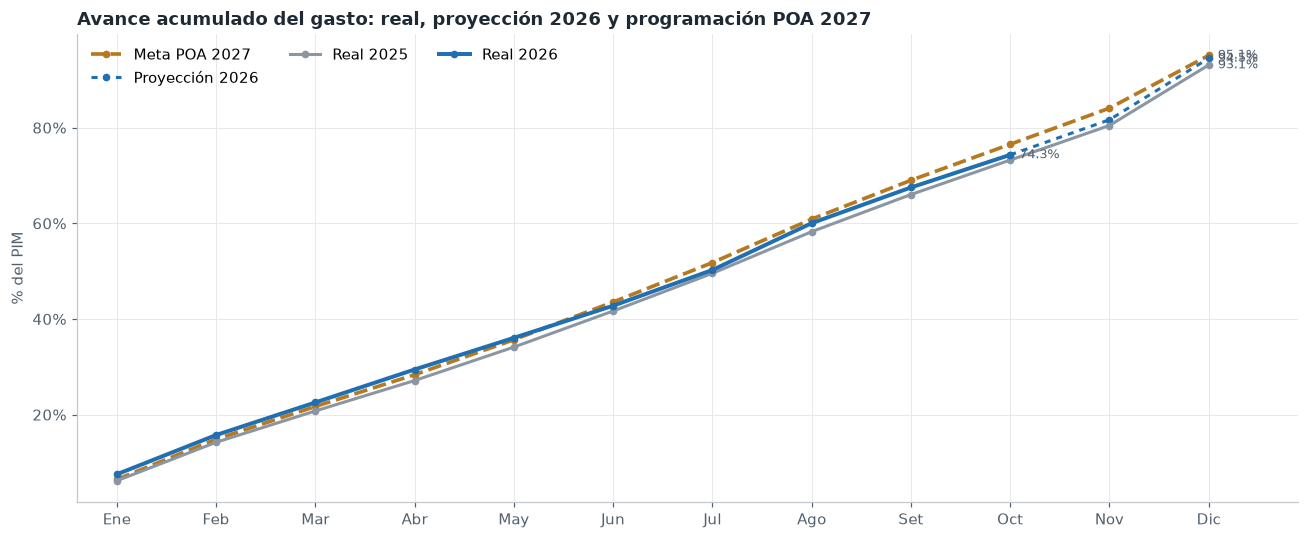

**Programación POA 2027 (hitos trimestrales de avance acumulado):** Mar: **21.7%** · Jun: **43.5%** · Set: **69.0%** · Dic: **95.1%**. Frente a 2025, adelanta gasto a los primeros meses porque diciembre baja de 13.6% a 11.6%.

In [44]:
# 8.5 Curvas de avance acumulado: real, proyección, programación y meta POA.
real = {a: fm[fm["anio"] == a].groupby("mes")["monto_devengado"].sum().cumsum() / anual(a, "monto_pim") for a in (ANIO_BASE, ANIO_SEG)}
real[ANIO_SEG] = real[ANIO_SEG].loc[:ULTIMO_SEG]
proyeccion_seg = real[ANIO_SEG].copy()
for m in range(ULTIMO_SEG + 1, 13):
    proyeccion_seg.loc[m] = proyeccion_seg.loc[m - 1] + perfil_base.loc[m] * dev_proyectado / pim_s
filas = []
for serie, anio, s in [("Real", ANIO_BASE, real[ANIO_BASE]), ("Real", ANIO_SEG, real[ANIO_SEG]),
                       ("Proyección", ANIO_SEG, proyeccion_seg.loc[ULTIMO_SEG:]),
                       ("Meta POA", ANIO_POA, curva_poa)]:
    for m, v in s.items():
        filas.append({"serie": serie, "anio": anio, "serie_etiqueta": f"{serie} {anio}", "mes_num": int(m),
                      "mes_abrev": MES_ABREV[int(m) - 1], "avance_acumulado": float(v)})
programacion_poa = pd.DataFrame(filas)
# Programación financiera referencial del POA: supone un PIM igual al del año en seguimiento.
programacion_poa["pim_referencial"] = np.where(programacion_poa["serie"] == "Meta POA", pim_s, np.nan)
programacion_poa["devengado_programado"] = programacion_poa["avance_acumulado"] * programacion_poa["pim_referencial"]

fig, ax = plt.subplots(figsize=(12, 5))
estilos = {f"Real {ANIO_BASE}": dict(color=COLOR_ANIO[ANIO_BASE], lw=2),
           f"Real {ANIO_SEG}": dict(color=COLOR_ANIO[ANIO_SEG], lw=2.6),
           f"Proyección {ANIO_SEG}": dict(color=COLOR_ANIO[ANIO_SEG], lw=2, ls=(0, (2, 2))),
           f"Meta POA {ANIO_POA}": dict(color=COLOR_META, lw=2.4, ls="--")}
for etiqueta, g in programacion_poa.groupby("serie_etiqueta"):
    ax.plot(g["mes_num"], g["avance_acumulado"], marker="o", ms=4, label=etiqueta, **estilos[etiqueta])
    ax.annotate(f"{g['avance_acumulado'].iloc[-1]:.1%}", (g["mes_num"].iloc[-1], g["avance_acumulado"].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=8.5, color=TINTA_2)
ax.set_xticks(range(1, 13), MES_ABREV)
ax.set_xlim(0.6, 12.9)
ax.yaxis.set_major_formatter(EJE_PCT)
ax.set(title=f"Avance acumulado del gasto: real, proyección {ANIO_SEG} y programación POA {ANIO_POA}", ylabel="% del PIM")
ax.legend(ncol=3, loc="upper left")
plt.tight_layout()
guardar(fig, "programacion_poa.png")
plt.show()
hitos = {m: float(curva_poa.loc[m]) for m in (3, 6, 9, 12)}
nota(f"**Programación POA {ANIO_POA} (hitos trimestrales de avance acumulado):** " +
     " · ".join(f"{MES_ABREV[m - 1]}: **{v:.1%}**" for m, v in hitos.items()) +
     f". Frente a {ANIO_BASE}, adelanta gasto a los primeros meses porque diciembre baja de {dic_b:.1%} a {dic_meta:.1%}.")

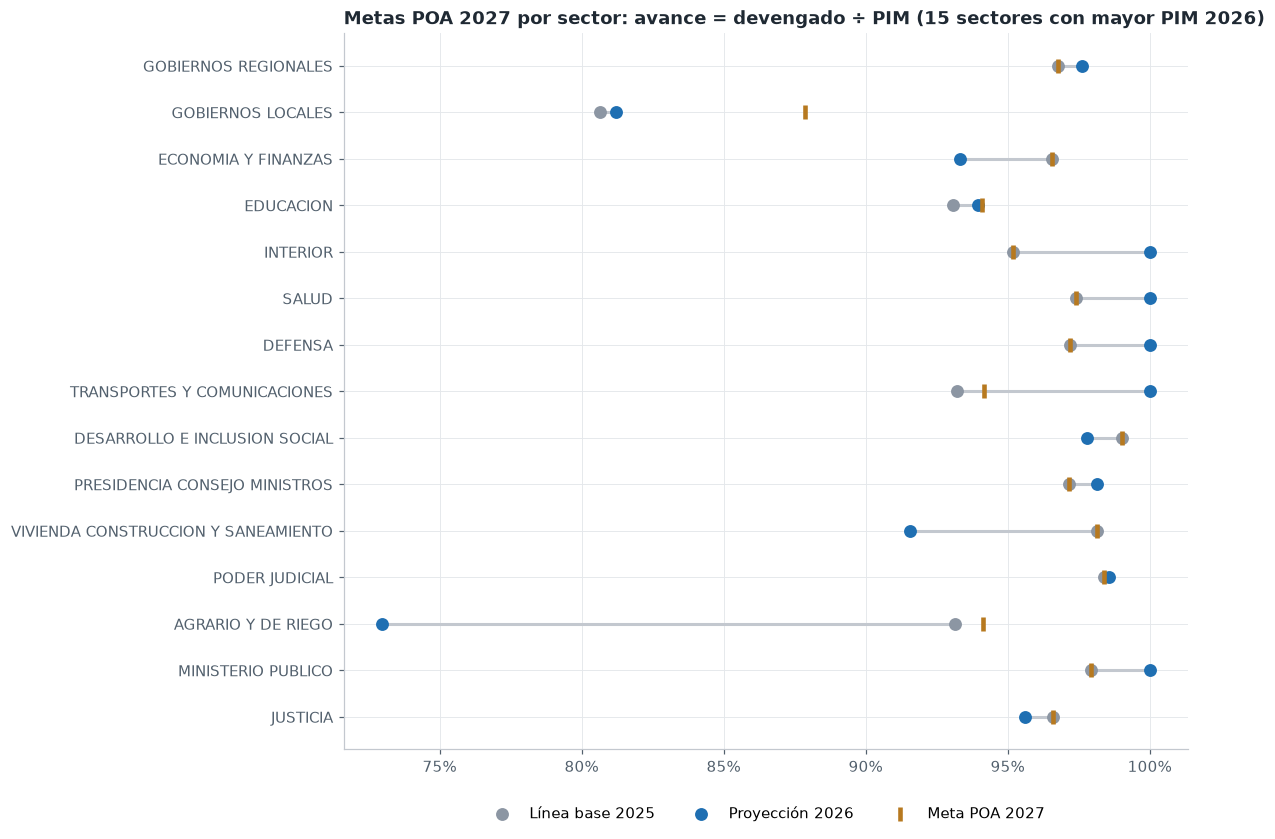

**Lectura automática:** 3 de 33 sectores tienen **prioridad alta** (su proyección 2026 queda más de 5 puntos debajo de su línea base): Vivienda Construccion Y Saneamiento, Agrario Y De Riego, Comercio Exterior Y Turismo. La meta POA 2027 de cada sector cierra la mitad de su brecha frente a la meta nacional (95.1%).

In [45]:
# 8.6 Metas por sector: la meta nacional se reparte según el punto de partida de cada sector.
META_NAC = meta_avance_poa
sec = (base.groupby(["anio", "sector_nombre"], observed=True)[["monto_pim", "monto_devengado", "dev_comparable"]].sum()
       .unstack("anio"))
cuota_sector = (sec[("dev_comparable", ANIO_BASE)] / sec[("monto_devengado", ANIO_BASE)]).where(sec[("monto_devengado", ANIO_BASE)] > 0)
metas_sector = pd.DataFrame({
    "pim_anio_seg": sec[("monto_pim", ANIO_SEG)],
    "avance_base": sec[("monto_devengado", ANIO_BASE)] / sec[("monto_pim", ANIO_BASE)],
    "avance_al_corte": sec[("dev_comparable", ANIO_SEG)] / sec[("monto_pim", ANIO_SEG)],
})
# La proyección se acota al 100 % del PIM: no se puede devengar más de lo presupuestado.
metas_sector["proyeccion_cierre"] = (sec[("dev_comparable", ANIO_SEG)] / cuota_sector.clip(0.3, 1).fillna(cuota_corte)
                                     / sec[("monto_pim", ANIO_SEG)]).clip(upper=1.0)
# Si el sector está debajo de la meta nacional, cierra la mitad de su brecha; si ya la supera, mantiene su línea base.
metas_sector["meta_poa"] = np.where(metas_sector["avance_base"] < META_NAC,
                                    metas_sector["avance_base"] + 0.5 * (META_NAC - metas_sector["avance_base"]),
                                    metas_sector["avance_base"])
metas_sector["brecha_proyeccion_pp"] = metas_sector["proyeccion_cierre"] - metas_sector["avance_base"]
metas_sector["prioridad"] = np.select([metas_sector["brecha_proyeccion_pp"] < -0.05, metas_sector["brecha_proyeccion_pp"] < 0],
                                      ["Alta", "Media"], "Baja")
metas_sector["accion_sugerida"] = metas_sector["prioridad"].map({
    "Alta": "Plan de aceleración del gasto con seguimiento mensual y asistencia técnica a sus unidades ejecutoras",
    "Media": "Seguimiento trimestral de la programación y reasignación oportuna de saldos",
    "Baja": "Mantener la programación y difundir sus buenas prácticas"})
metas_sector["color_prioridad"] = metas_sector["prioridad"].map({"Alta": ESTADO["critico"], "Media": ESTADO["alerta"], "Baja": ESTADO["bueno"]})
metas_sector = (metas_sector.dropna(subset=["pim_anio_seg", "avance_base"]).sort_values("pim_anio_seg", ascending=False)
                .reset_index().rename(columns={"sector_nombre": "sector"}))
metas_sector["sector"] = metas_sector["sector"].astype(str)

top = metas_sector.head(TOP_N).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 1.4 + 0.42 * len(top)))
y = np.arange(len(top))
ax.hlines(y, top["avance_base"], top["proyeccion_cierre"], color=EJE, lw=2)
ax.scatter(top["avance_base"], y, s=55, color=COLOR_ANIO[ANIO_BASE], label=f"Línea base {ANIO_BASE}", zorder=3)
ax.scatter(top["proyeccion_cierre"], y, s=55, color=COLOR_ANIO[ANIO_SEG], label=f"Proyección {ANIO_SEG}", zorder=3)
ax.scatter(top["meta_poa"], y, s=90, marker="|", color=COLOR_META, linewidths=3, label=f"Meta POA {ANIO_POA}", zorder=4)
ax.set_yticks(y, [s[:40] for s in top["sector"]])
ax.xaxis.set_major_formatter(EJE_PCT)
ax.set_title(f"Metas POA {ANIO_POA} por sector: avance = devengado ÷ PIM ({TOP_N} sectores con mayor PIM {ANIO_SEG})")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=3)
plt.tight_layout()
guardar(fig, "metas_poa_sector.png")
plt.show()
alta = metas_sector[metas_sector["prioridad"] == "Alta"]
nota(f"**Lectura automática:** {len(alta)} de {len(metas_sector)} sectores tienen **prioridad alta** (su proyección {ANIO_SEG} queda más de 5 puntos "
     f"debajo de su línea base)" + (": " + ", ".join(s.title() for s in alta.head(6)["sector"]) + ("…" if len(alta) > 6 else "") if len(alta) else "") +
     f". La meta POA {ANIO_POA} de cada sector cierra la mitad de su brecha frente a la meta nacional ({META_NAC:.1%}).")

In [46]:
# Exportar los instrumentos del POA a la capa Gold para que Power BI los use.
indicadores_poa = ind[["orden", "objetivo_codigo", "objetivo_operativo", "resultado_esperado", "codigo", "indicador", "objetivo", "formula", "unidad", "sentido_texto", "frecuencia", "fuente",
                       "linea_base", "valor_al_corte", "proyeccion_cierre", "meta_anio_seg", "meta_poa",
                       "brecha_proyeccion_pp", "estado", "color_estado", "accion_mejora", "responsable"]].rename(columns={"sentido_texto": "sentido"})
indicadores_poa = indicadores_poa.assign(anio_base=ANIO_BASE, anio_seguimiento=ANIO_SEG, anio_poa=ANIO_POA)
POA_TABLAS = {"indicadores_poa": indicadores_poa, "metas_sector_poa": metas_sector, "programacion_poa": programacion_poa}
for nombre, tabla in POA_TABLAS.items():
    guardar_parquet(tabla, GOLD / f"{nombre}.parquet", tipos_de(tabla))
    tabla.to_csv(OUTPUTS / f"{nombre}.csv", index=False, encoding="utf-8-sig")
    print(f"Gold → {(GOLD / (nombre + '.parquet')).relative_to(RAIZ).as_posix():<55} {len(tabla):>4} filas")

DESCRIPCION.update({
    "orden": "Orden de presentación", "codigo": "Código del indicador", "indicador": "Nombre del indicador",
    "objetivo": "Qué busca medir", "formula": "Fórmula de cálculo", "unidad": "Unidad de medida", "sentido": "Mayor o menor es mejor",
    "frecuencia": "Periodicidad de medición", "fuente": "Origen del dato", "linea_base": f"Valor del año base ({ANIO_BASE})",
    "valor_al_corte": f"Valor de {ANIO_SEG} al último mes con datos", "proyeccion_cierre": f"Proyección de cierre {ANIO_SEG} (método estacional)",
    "meta_anio_seg": f"Meta {ANIO_SEG} = línea base", "meta_poa": f"Meta del POA {ANIO_POA}", "brecha_proyeccion_pp": "Proyección − meta (puntos, en el sentido del indicador)",
    "estado": "Cumple / En riesgo / No cumple", "color_estado": "Color del semáforo (hex)", "anio_base": "Año de la línea base",
    "anio_seguimiento": "Año en seguimiento", "anio_poa": "Año planificado", "sector": "Sector del presupuesto",
    "pim_anio_seg": f"PIM {ANIO_SEG} (S/)", "avance_base": f"Avance {ANIO_BASE} (devengado ÷ PIM)", "avance_al_corte": f"Avance {ANIO_SEG} al corte",
    "prioridad": "Alta / Media / Baja según la brecha de la proyección", "color_prioridad": "Color de la prioridad (hex)",
    "serie": "Real / Proyección / Meta POA", "serie_etiqueta": "Serie y año", "mes_num": "Mes (1–12)",
    "mes_abrev": "Mes abreviado", "avance_acumulado": "Devengado acumulado ÷ PIM", "pim_referencial": "PIM supuesto para el POA (S/)",
    "devengado_programado": "Devengado acumulado programado (S/)", "objetivo_codigo": "Código del objetivo operativo",
    "objetivo_operativo": "Objetivo operativo del POA", "resultado_esperado": "Resultado que persigue el objetivo",
    "accion_mejora": "Acción de mejora propuesta", "responsable": "Unidad orgánica responsable", "accion_sugerida": "Acción sugerida según la prioridad",
})
GOLD_TABLAS.update(POA_TABLAS)
diccionario = pd.DataFrame([{"tabla": t, "columna": c, "tipo": tp,
                             "descripción": DESCRIPCION.get(c, "Clave sustituta (entero)" if c.endswith("_key") else "Atributo descriptivo / código MEF")}
                            for t, tabla in GOLD_TABLAS.items() for c, tp in tipos_de(tabla).items()])
diccionario.to_csv(OUTPUTS / "diccionario_datos_gold.csv", index=False, encoding="utf-8-sig")
print(f"\nDiccionario actualizado: {len(diccionario)} columnas en {diccionario['tabla'].nunique()} tablas → outputs/{CARPETA}/diccionario_datos_gold.csv")

Gold → data/gold/gasto_publico/indicadores_poa.parquet            9 filas
Gold → data/gold/gasto_publico/metas_sector_poa.parquet          33 filas
Gold → data/gold/gasto_publico/programacion_poa.parquet          37 filas

Diccionario actualizado: 191 columnas en 20 tablas → outputs/gasto_publico/diccionario_datos_gold.csv


---
## 9. Diagnóstico final, gobierno de datos y sesgos

In [47]:
r = reporte_silver.sum(axis=1)
diagnostico = pd.DataFrame([
    {"Problema": "Líneas sin ningún monto", "Cuantificación": f"{r['lineas_sin_ningun_monto']:,} líneas",
     "Impacto": "Ninguno en sumas; inflan el conteo de líneas", "Acción": "Excluir en Silver y contarlas"},
    {"Problema": "Textos con espacios dobles, bordes y minúsculas", "Cuantificación": f"{cambios.sum().sum():,} celdas",
     "Impacto": "Un mismo nombre aparecería dos veces en los segmentadores", "Acción": "Normalizar en Silver"},
    {"Problema": "Extornos (devengado negativo)", "Cuantificación": f"{int(tot['extornos'].sum()):,} registros · {s_millones(-tot['monto_extornos'].sum())}",
     "Impacto": "Reducen el devengado de meses posteriores", "Acción": "Conservar; separar en monto_extorno"},
    {"Problema": "Devengado > PIM por línea (PIM en la línea principal, devengado en la sub cuenta)",
     "Cuantificación": f"{sum(p['embudo_n']['Devengado ≤ PIM'] for p in PERFIL.values()):,} líneas → "
                       f"{int(reglas_gold.loc[reglas_gold['Regla'] == 'Devengado ≤ PIM', 'Incumplimientos'].sum()):,} combinaciones al grano Gold",
     "Impacto": "Avances de 'infinito %' si se analiza por tipo de recurso", "Acción": "No usar tipo_recurso en Gold; medir avance desde el rubro hacia arriba"},
    {"Problema": f"{a1} es un año en curso", "Cuantificación": f"Datos hasta {MESES[int(dim_anio.set_index('anio').loc[a1, 'mes_ultimo_dato']) - 1].lower()}",
     "Impacto": "Comparar años completos con años en curso exagera la caída", "Acción": "Comparar a igual corte (dim_anio.mes_corte_comparable)"},
])
diagnostico.to_csv(OUTPUTS / "diagnostico_final.csv", index=False, encoding="utf-8-sig")
diagnostico

,Problema,Cuantificación,Impacto,Acción
0,Líneas sin ningún monto,"336,134 líneas",Ninguno en sumas; inflan el conteo de líneas,Excluir en Silver y contarlas
1,"Textos con espacios dobles, bordes y minúsculas","14,954,830 celdas",Un mismo nombre aparecería dos veces en los se...,Normalizar en Silver
2,Extornos (devengado negativo),"133,928 registros · S/ 2,480.8 M",Reducen el devengado de meses posteriores,Conservar; separar en monto_extorno
3,Devengado > PIM por línea (PIM en la línea pri...,"1,566,580 líneas → 9 combinaciones al grano Gold",Avances de 'infinito %' si se analiza por tipo...,No usar tipo_recurso en Gold; medir avance des...
4,2026 es un año en curso,Datos hasta octubre,Comparar años completos con años en curso exag...,Comparar a igual corte (dim_anio.mes_corte_com...


### Gobierno de datos, en la medida necesaria

| Control | Aplicación en este proyecto |
|---|---|
| Propietario de datos | MEF (SIAF), publicado en datos abiertos |
| Data steward | El equipo: custodia el contrato de 73 columnas, las reglas de limpieza y el diccionario de Gold |
| Linaje | CSV MEF → Bronze (`_archivo_origen`, `_fila_origen`) → Silver (`id_linea` = año × 10⁷ + fila) → Gold → indicadores y metas POA → Power BI |
| Metadatos | Fecha de ingesta, mes de corte por año, diccionario `diccionario_datos_gold.csv` |
| Ética | Datos públicos agregados de entidades; no hay datos personales |

### Sesgos y límites

- **PIM como foto:** el PIM de un año en curso todavía crece con modificaciones; el avance de 2026 es contra el PIM **a la fecha de descarga**, mientras que el de 2025 es contra su PIM **final**. Por eso "avance al corte" de 2025 subestima ligeramente cómo iba 2025 en ese mismo momento.
- **Mes en curso:** si el último mes está incompleto, se excluye del periodo comparable (regla `UMBRAL_MES_PARCIAL`).
- **Ubicación:** `departamento_ejecutora` dice dónde está la oficina que gasta (muchas en Lima); `departamento_meta` dice dónde se ejecuta el gasto. El análisis territorial usa la **meta**.
- **Avance ≠ calidad:** devengar rápido no garantiza que el gasto produzca resultados.
- **Proyección ingenua:** la proyección de cierre supone que el año en curso repite el calendario de gasto del año base; un cambio de gobierno, una emergencia o una ley de crédito suplementario la invalidan. Por eso las metas se revisan cada trimestre.
- **Metas por regla, no por negociación:** las metas del POA salen de reglas transparentes (línea base + mejora con tope). En un POI real se validan con cada unidad ejecutora.

---
## 10. Cierre: hallazgos, evidencia, metas y acciones

Esta sección reúne en un solo lugar lo que responde el **objetivo general**: cómo se comportó el presupuesto (líneas 1 a 5 y Ley 2026), qué indicadores y metas se proponen y qué acciones de mejora se derivan. Todas las cifras se calculan con los resultados de esta ejecución, de modo que se actualizan si se vuelve a correr el notebook con datos nuevos.

In [48]:
# 10.1 Hallazgos principales: una fila por línea de análisis, con su evidencia y su implicancia para el POA.
ev0, ev1 = evolucion.loc[a0], evolucion.loc[a1]
pm = proyeccion_metodos.set_index("metodo_codigo")
cc = conteo_clase
cl_alta = int(cc.loc[["Muy alta", "Alta"], a1].sum())
cl_baja = int(cc.loc[["Baja", "Muy baja"], a1].sum())
e_base = estacionalidad_mensual[estacionalidad_mensual["anio"] == a0].set_index("mes_num")
mes_pico = int(e_base["indice_estacional"].idxmax())
at1 = atipicos_entidades[atipicos_entidades["anio"] == a1]
fun = VARIACIONES["Función"]
fun = fun[fun[f"PIM {a1}"] >= 0.01 * fun[f"PIM {a1}"].sum()]
cnt = ind["estado"].value_counts()
cuadra = abs(dif_total) < 0.01   # con la muestra no cuadra (solo trae parte de las entidades)
txt_ley = (f"cuadra con la Ley ({dif_total:+.3%})" if cuadra
           else f"difiere de la Ley en {dif_total:+.1%} porque la ejecución usó datos parciales")
txt_pico = (f"El gasto se concentra al cierre: {MESES[mes_pico - 1].lower()} es el mes más intenso" if mes_pico >= 11
            else f"El mes de mayor gasto es {MESES[mes_pico - 1].lower()}")
var_pia = ev1['monto_pia'] / ev0['monto_pia'] - 1
no_cumple = ind[ind["estado"] == "No cumple"]
hallazgos = pd.DataFrame([
    {"Línea / tema": "1. Ejecución y proyección",
     "Hallazgo": f"{a0} cerró con {ev0['avance_anual']:.1%} de ejecución; {a1} lleva {ev1['avance_anual']:.1%} y proyecta {pm.loc['A', 'avance_proyectado']:.1%} al cierre",
     "Evidencia": f"Métodos A y C coinciden ({pm.loc['A', 'avance_proyectado']:.1%} y {pm.loc['C', 'avance_proyectado']:.1%}; IC 95 % {pm.loc['C', 'limite_inferior']:.1%}–{pm.loc['C', 'limite_superior']:.1%}); el PIM supera al PIA en {ev1['modificacion_pct']:+.1%}",
     "Implicancia para el POA": "La meta de avance 2027 puede subir sobre la línea base sin ser irreal"},
    {"Línea / tema": "2. Clasificación de entidades",
     "Hallazgo": f"{cl_alta} entidades proyectan ejecución alta o muy alta y {cl_baja} baja o muy baja",
     "Evidencia": f"{pct_baja:.1%} de las unidades ejecutoras con PIM relevante queda en clase baja o muy baja en {a1}",
     "Implicancia para el POA": "Focalizar asistencia técnica en las clases baja y muy baja (IND08)"},
    {"Línea / tema": "3. Comportamiento mensual",
     "Hallazgo": f"{txt_pico} (índice {e_base.loc[mes_pico, 'indice_estacional']:.2f})",
     "Evidencia": f"El 4.º trimestre concentra el {trimestral.get('T4', np.nan):.1%} del gasto de {a0}; correlación entre años r = {correlacion:.2f}",
     "Implicancia para el POA": "Programar el gasto para reducir la concentración de diciembre (IND04 y programación mensual)"},
    {"Línea / tema": "4. Patrones atípicos",
     "Hallazgo": f"{len(at1):,} alertas en {a1}; {int((at1['tecnica'] == 'IQR y z robusto').sum()):,} confirmadas por ambas técnicas",
     "Evidencia": f"La variable con más atípicos confirmados es «{var_top}»",
     "Implicancia para el POA": "Revisar las modificaciones presupuestales inusuales y los avances muy bajos antes de fijar metas por entidad"},
    {"Línea / tema": "5. Variaciones",
     "Hallazgo": f"El PIM {a1} varía {ev1['monto_pim'] / ev0['monto_pim'] - 1:+.1%} frente a {a0}",
     "Evidencia": f"Mayor crecimiento: {str(fun['var. PIM %'].idxmax()).title()} ({fun['var. PIM %'].max():+.1%}); mayor reducción: {str(fun['var. PIM %'].idxmin()).title()} ({fun['var. PIM %'].min():+.1%})",
     "Implicancia para el POA": "Las metas sectoriales deben considerar los cambios de asignación entre años"},
    {"Línea / tema": "Ley N.º 32513 (2026)",
     "Hallazgo": f"El PIA 2026 suma {s_millones(pia_total)} y {txt_ley}",
     "Evidencia": f"Crecimiento de {LEY_TOTAL / PIA_ANTERIOR_OFICIAL - 1:+.1%} frente al presupuesto 2025; {LEY_DIST['Función'].iloc[0]['participación']:.1%} se asigna a {str(LEY_DIST['Función'].index[0]).title()}",
     "Implicancia para el POA": "El POA 2027 parte de una asignación validada contra la norma oficial"},
    {"Línea / tema": "Planeamiento operativo",
     "Hallazgo": f"De {len(ind)} indicadores, {cnt.get('Cumple', 0)} cumplen, {cnt.get('En riesgo', 0)} están en riesgo y {cnt.get('No cumple', 0)} no cumplen la meta {ANIO_SEG}",
     "Evidencia": f"Meta POA {ANIO_POA}: avance de {meta_avance_poa:.1%} con diciembre ≤ {dic_meta:.1%}; {len(alta)} sectores con prioridad alta",
     "Implicancia para el POA": "Ejecutar primero las acciones de los indicadores que no cumplen"},
])
hallazgos.to_csv(OUTPUTS / "hallazgos_cierre.csv", index=False, encoding="utf-8-sig")
display(hallazgos.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"}))

Línea / tema,Hallazgo,Evidencia,Implicancia para el POA
1. Ejecución y proyección,2025 cerró con 93.1% de ejecución; 2026 lleva 74.3% y proyecta 94.5% al cierre,Métodos A y C coinciden (94.5% y 94.5%; IC 95 % 91.8%–97.1%); el PIM supera al PIA en +13.0%,La meta de avance 2027 puede subir sobre la línea base sin ser irreal
2. Clasificación de entidades,634 entidades proyectan ejecución alta o muy alta y 542 baja o muy baja,24.6% de las unidades ejecutoras con PIM relevante queda en clase baja o muy baja en 2026,Focalizar asistencia técnica en las clases baja y muy baja (IND08)
3. Comportamiento mensual,El gasto se concentra al cierre: diciembre es el mes más intenso (índice 1.63),El 4.º trimestre concentra el 29.1% del gasto de 2025; correlación entre años r = 0.70,Programar el gasto para reducir la concentración de diciembre (IND04 y programación mensual)
4. Patrones atípicos,455 alertas en 2026; 276 confirmadas por ambas técnicas,La variable con más atípicos confirmados es «Modificación PIM ÷ PIA»,Revisar las modificaciones presupuestales inusuales y los avances muy bajos antes de fijar metas por entidad
5. Variaciones,El PIM 2026 varía +6.9% frente a 2025,Mayor crecimiento: Defensa Y Seguridad Nacional (+40.5%); mayor reducción: Prevision Social (-2.2%),Las metas sectoriales deben considerar los cambios de asignación entre años
Ley N.º 32513 (2026),"El PIA 2026 suma S/ 257,561.6 M y cuadra con la Ley (+0.000%)",Crecimiento de +2.3% frente al presupuesto 2025; 18.9% se asigna a Educacion,El POA 2027 parte de una asignación validada contra la norma oficial
Planeamiento operativo,"De 9 indicadores, 6 cumplen, 1 están en riesgo y 2 no cumplen la meta 2026",Meta POA 2027: avance de 95.1% con diciembre ≤ 11.6%; 3 sectores con prioridad alta,Ejecutar primero las acciones de los indicadores que no cumplen


In [49]:
# 10.2 Conclusiones y acciones prioritarias (texto generado con las cifras de esta ejecución).
acciones = "\n".join(f"   - **{r.codigo} {r.indicador}** ({r.objetivo_codigo}): {r.accion_mejora} *Responsable: {r.responsable}.*"
                     for r in no_cumple.itertuples()) or "   - Todos los indicadores alcanzan su meta; mantener la programación."
sectores_alta = ", ".join(s.title() for s in alta["sector"].head(6)) if len(alta) else "ninguno"
nota(f"""### Conclusiones

1. **Comportamiento del presupuesto.** El presupuesto aprobado {'creció' if var_pia >= 0 else 'disminuyó'} de {s_millones(ev0['monto_pia'])} ({a0}) a {s_millones(ev1['monto_pia'])} ({a1}), {var_pia:+.1%}, y durante el año se modifica de forma importante (el PIM supera al PIA en {ev1['modificacion_pct']:+.1%}). La ejecución de {a0} fue de **{ev0['avance_anual']:.1%}** y la de {a1} se proyecta en **{pm.loc['A', 'avance_proyectado']:.1%}**, con un intervalo estadístico de {pm.loc['C', 'limite_inferior']:.1%}–{pm.loc['C', 'limite_superior']:.1%}.
2. **Dónde está el rezago.** La ejecución no es homogénea: {pct_baja:.1%} de las unidades ejecutoras relevantes queda en clase baja o muy baja, el gasto se concentra en el último trimestre ({trimestral.get('T4', np.nan):.1%} en {a0}) y {int((at1['tecnica'] == 'IQR y z robusto').sum()):,} valores atípicos confirmados requieren revisión.
3. **Presupuesto 2026.** El análisis de la Ley N.º 32513 {'se apoya en datos que cuadran con la cifra oficial (' + format(dif_total, '+.3%') + '), por lo que las distribuciones por nivel, función, pliego, genérica y fuente del dashboard son confiables' if cuadra else 'debe leerse con cautela: los datos de esta ejecución difieren de la cifra oficial en ' + format(dif_total, '+.1%')}. El presupuesto 2026 crece {LEY_TOTAL / PIA_ANTERIOR_OFICIAL - 1:+.1%} frente a 2025 y su mayor asignación por función es {str(LEY_DIST['Función'].index[0]).title()} ({LEY_DIST['Función'].iloc[0]['participación']:.1%}).
4. **Indicadores y metas.** Se formularon **{len(ind)} indicadores** agrupados en **{len(OBJETIVOS_OPERATIVOS)} objetivos operativos**, con línea base {ANIO_BASE}, meta {ANIO_SEG} y meta POA {ANIO_POA}. La meta central es un avance de **{meta_avance_poa:.1%}** en {ANIO_POA}, con una programación mensual que reduce diciembre a {dic_meta:.1%} del gasto anual.

### Acciones prioritarias para el POA {ANIO_POA}

1. Indicadores que **no cumplen** su meta {ANIO_SEG}:
{acciones}
2. Sectores con **prioridad alta**: {sectores_alta}. Acción: plan de aceleración del gasto con seguimiento mensual.
3. Unidades ejecutoras en clase **baja o muy baja** (sección 6.2): asistencia técnica y metas trimestrales.
4. Seguimiento **trimestral** con el dashboard (módulos 3, 4 y 6) y revisión de metas si la proyección sale del intervalo al 95 %.

### Respuesta al objetivo

El dashboard permite **analizar el comportamiento del presupuesto público** (módulos 1 a 5), **formular indicadores** con línea base y fórmula (módulo 6.1) y **establecer metas** anuales, mensuales y sectoriales con acciones de mejora (módulos 6.1 y 6.2), que son los insumos del **planeamiento operativo anual**.""")

### Conclusiones

1. **Comportamiento del presupuesto.** El presupuesto aprobado creció de S/ 251,801.0 M (2025) a S/ 257,561.6 M (2026), +2.3%, y durante el año se modifica de forma importante (el PIM supera al PIA en +13.0%). La ejecución de 2025 fue de **93.1%** y la de 2026 se proyecta en **94.5%**, con un intervalo estadístico de 91.8%–97.1%.
2. **Dónde está el rezago.** La ejecución no es homogénea: 24.6% de las unidades ejecutoras relevantes queda en clase baja o muy baja, el gasto se concentra en el último trimestre (29.1% en 2025) y 276 valores atípicos confirmados requieren revisión.
3. **Presupuesto 2026.** El análisis de la Ley N.º 32513 se apoya en datos que cuadran con la cifra oficial (+0.000%), por lo que las distribuciones por nivel, función, pliego, genérica y fuente del dashboard son confiables. El presupuesto 2026 crece +2.3% frente a 2025 y su mayor asignación por función es Educacion (18.9%).
4. **Indicadores y metas.** Se formularon **9 indicadores** agrupados en **4 objetivos operativos**, con línea base 2025, meta 2026 y meta POA 2027. La meta central es un avance de **95.1%** en 2027, con una programación mensual que reduce diciembre a 11.6% del gasto anual.

### Acciones prioritarias para el POA 2027

1. Indicadores que **no cumplen** su meta 2026:
   - **IND02 Certificación del PIM** (OO2): Certificar en enero el gasto recurrente (planillas, servicios, contratos vigentes) y depurar cada trimestre las certificaciones que no llegaron a compromiso. *Responsable: OPP y Oficina de Logística.*
   - **IND07 Modificación presupuestal** (OO2): Formular el PIA con la ejecución histórica y la programación multianual; sustentar las modificaciones mayores a 10 %. *Responsable: OPP.*
2. Sectores con **prioridad alta**: Vivienda Construccion Y Saneamiento, Agrario Y De Riego, Comercio Exterior Y Turismo. Acción: plan de aceleración del gasto con seguimiento mensual.
3. Unidades ejecutoras en clase **baja o muy baja** (sección 6.2): asistencia técnica y metas trimestrales.
4. Seguimiento **trimestral** con el dashboard (módulos 3, 4 y 6) y revisión de metas si la proyección sale del intervalo al 95 %.

### Respuesta al objetivo

El dashboard permite **analizar el comportamiento del presupuesto público** (módulos 1 a 5), **formular indicadores** con línea base y fórmula (módulo 6.1) y **establecer metas** anuales, mensuales y sectoriales con acciones de mejora (módulos 6.1 y 6.2), que son los insumos del **planeamiento operativo anual**.

**Siguiente paso → Power BI.** Abra `dashboard/presupuesto_publico_poa.pbix`. Sus **siete módulos** usan las tablas de `data/gold/gasto_publico/`:

| Módulo | Secciones del notebook |
|---|---|
| 1. Resumen ejecutivo | 6.1.a |
| 2. Diagnóstico presupuestario | 6.1 y 6.5 |
| 3. Indicadores de gestión | 6.1, 6.5 y 8.2 |
| 4. Análisis integral (4.1 a 4.5) | 6.1 a 6.5 |
| 5. Presupuesto Público 2026 | 7 |
| 6. Planeamiento operativo anual | 8 |
| 7. Seguimiento y consulta | 6.2 y 6.4 (detalle por entidad) |

La conexión, el modelo y las medidas DAX están en `docs/Manual_Tecnico.docx`; el recorrido del tablero, en `docs/Manual_de_Usuario.docx`.

---
## Referencias

- Ministerio de Economía y Finanzas del Perú. Datos abiertos de ejecución presupuestal del gasto: *Gasto devengado mensual* 2025 y 2026 [CSV]. Plataforma Nacional de Datos Abiertos.
- Congreso de la República (2025). *Ley N.º 32513, Ley de Presupuesto del Sector Público para el Año Fiscal 2026* y anexos 1 a 6. Diario Oficial El Peruano.
- Ministerio de Economía y Finanzas (2025). *Alcances de la Ley de Presupuesto del Sector Público 2026* y *Guía de orientación al ciudadano del Proyecto de Ley de Presupuesto 2026*.
- Congreso de la República, Área de Servicios de Investigación y Seguimiento Presupuestal. Reportes temáticos de seguimiento del gasto público 2026 y *Ejecución presupuestal del gasto público en niñas, niños y adolescentes – GPNNA, diciembre 2025*.
- Centro Nacional de Planeamiento Estratégico (CEPLAN). *Guía para el Planeamiento Institucional* (Res. N.° 033-2017-CEPLAN/PCD y modificatorias).
- Iglewicz, B. y Hoaglin, D. (1993). *How to Detect and Handle Outliers*. ASQC Quality Press (puntaje z modificado).
- Tukey, J. W. (1977). *Exploratory Data Analysis*. Addison-Wesley (regla del rango intercuartílico).
- Hyndman, R. J. y Athanasopoulos, G. *Forecasting: Principles and Practice* (3.ª ed.), OTexts (métodos de pronóstico e intervalos de predicción).
- DAMA International. *DAMA-DMBOK: Data Management Body of Knowledge* (2.ª ed.).
- Kimball, R. y Ross, M. *The Data Warehouse Toolkit* (3.ª ed.). Wiley.
- Hichert, R. y Faisst, J. *International Business Communication Standards (IBCS)*, versión 2.0 (alineada con ISO 24896).